# NFReqBiLSTM (multiseed)

In [ ]:
pip install lime shap scikit-learn tensorflow matplotlib seaborn nltk pandas memory_profiler psutil


RUN 1/10  (seed=34)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


  Acc=0.6120  F1(macro)=0.4742  F1(weighted)=0.5830
  LIME fidelity=0.885±0.107  Faithfulness@5=0.1872
  Fitting TF-IDF Ridge surrogate + computing SHAP...


/tmp/ipykernel_46727/2322890803.py:390: RuntimeWarning: invalid value encountered in log
  (y_soft_test_bilstm + eps) * (np.log((y_soft_test_bilstm + eps) / (y_soft_test_surr + eps))),
/usr/local/lib/python3.13/dist-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


  [Surrogate vs BiLSTM] mean KL-like divergence on test: nan

RUN 2/10  (seed=35)
  Acc=0.7322  F1(macro)=0.6991  F1(weighted)=0.7274
  LIME fidelity=0.635±0.217  Faithfulness@5=0.5463

RUN 3/10  (seed=36)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


... (11 outputs left out)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


  Acc=0.7760  F1(macro)=0.7458  F1(weighted)=0.7743
  LIME fidelity=0.689±0.264  Faithfulness@5=0.3970

RUN 10/10  (seed=43)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


  Acc=0.7814  F1(macro)=0.7435  F1(weighted)=0.7808
  LIME fidelity=0.711±0.218  Faithfulness@5=0.4941

AGGREGATE RESULTS OVER 10 RUNS (seeds 34..43)
            metric   mean    std
          accuracy 0.7530 0.0519
   precision_macro 0.7323 0.0715
      recall_macro 0.7147 0.0752
          f1_macro 0.7136 0.0845
precision_weighted 0.7584 0.0510
   recall_weighted 0.7530 0.0519
       f1_weighted 0.7481 0.0599
         train_acc 0.9391 0.0847
          test_acc 0.7530 0.0519
        train_loss 0.2333 0.2742
         test_loss 0.8856 0.1564

=== Per-class metrics (mean ± std across runs) ===
          class  precision_mean  precision_std  recall_mean  recall_std  f1_mean  f1_std  support_mean
Maintainability          0.7750         0.1218       0.6630      0.1309   0.6961  0.0828       27.0000
    Operability          0.6727         0.0945       0.6387      0.0955   0.6508  0.0843       31.0000
    Performance          0.7145         0.2490       0.6783      0.2559   0.6880  0.2410     

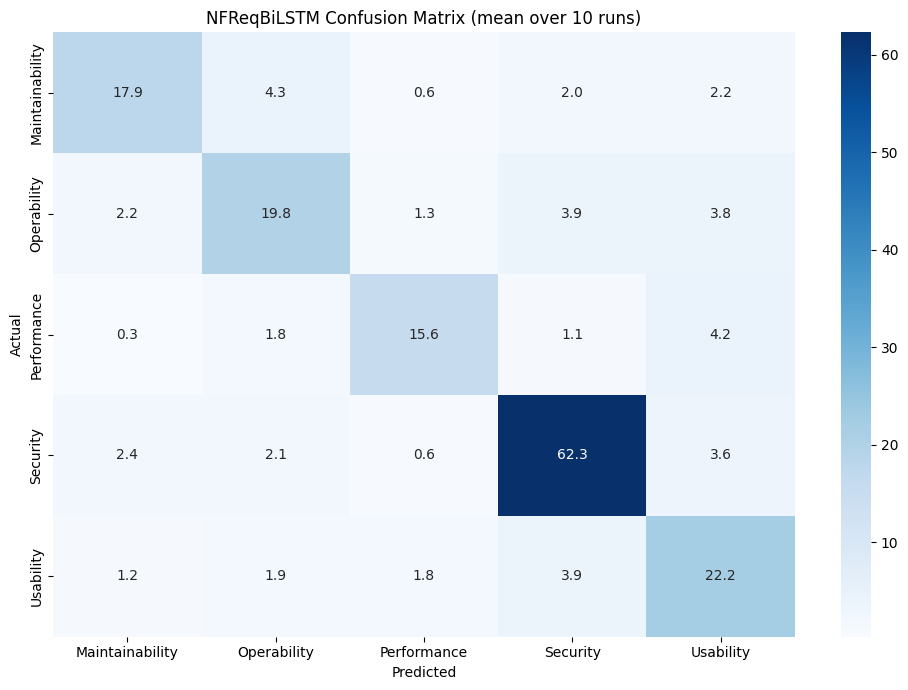

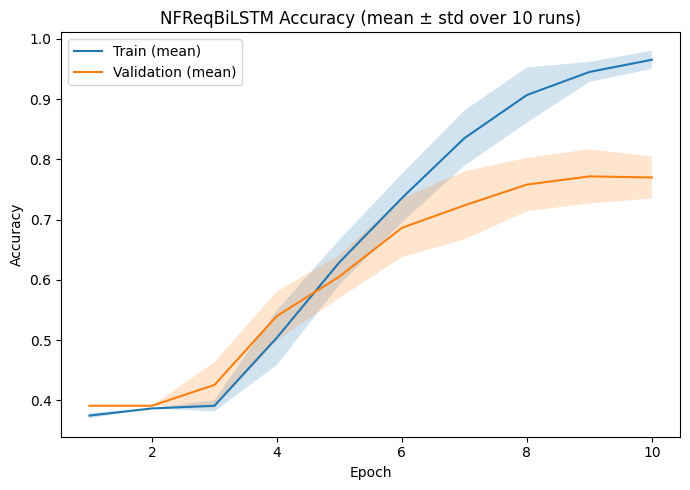

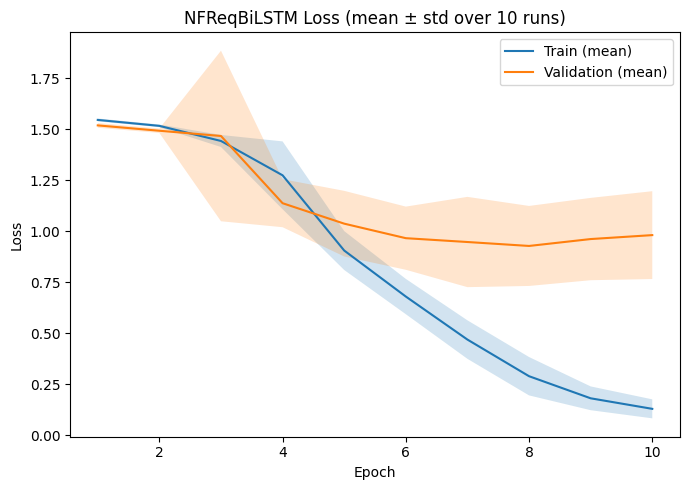


=== Top-20 words by avg positive LIME weight, aggregated over 10 runs ===
         word  avg_positive_lime_weight  avg_tfidf
      element                    0.5405     0.0034
automatically                    0.4373     0.0000
      pattern                    0.4291     0.0042
    compliant                    0.3805     0.0000
     discrete                    0.3719     0.0019
         real                    0.3629     0.0020
      queries                    0.3612     0.0000
         code                    0.3325     0.0028
         book                    0.3306     0.0000
    passwords                    0.3284     0.0000
     accesses                    0.3235     0.0000
       orange                    0.3200     0.0000
      disease                    0.3144     0.0038
        https                    0.3109     0.0000
   registered                    0.3027     0.0024
     security                    0.2998     0.0114
        input                    0.2989     0.0044
     br

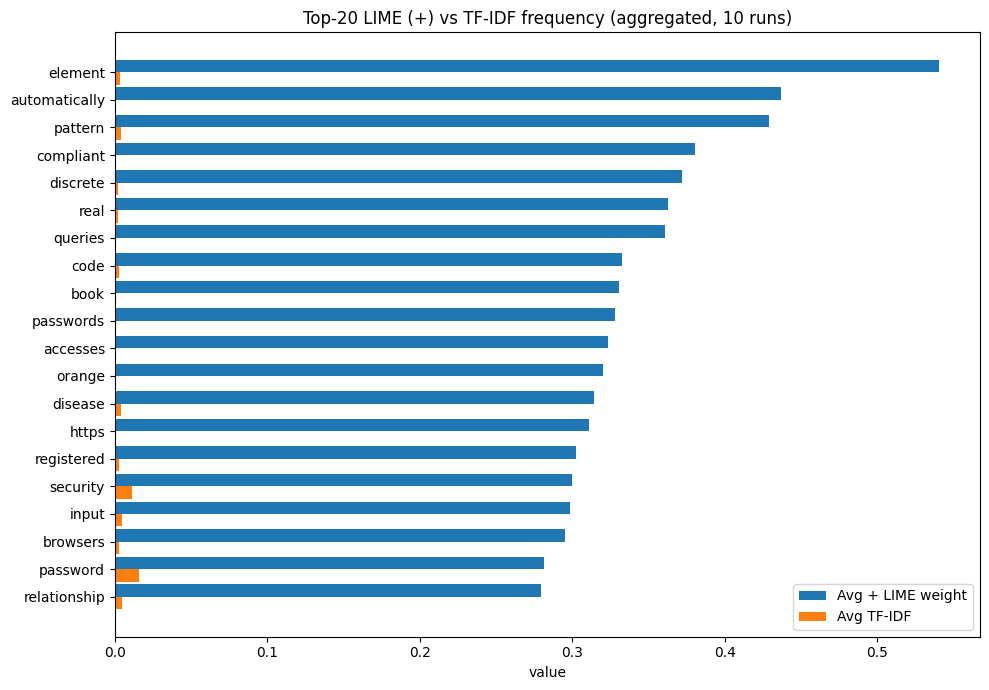

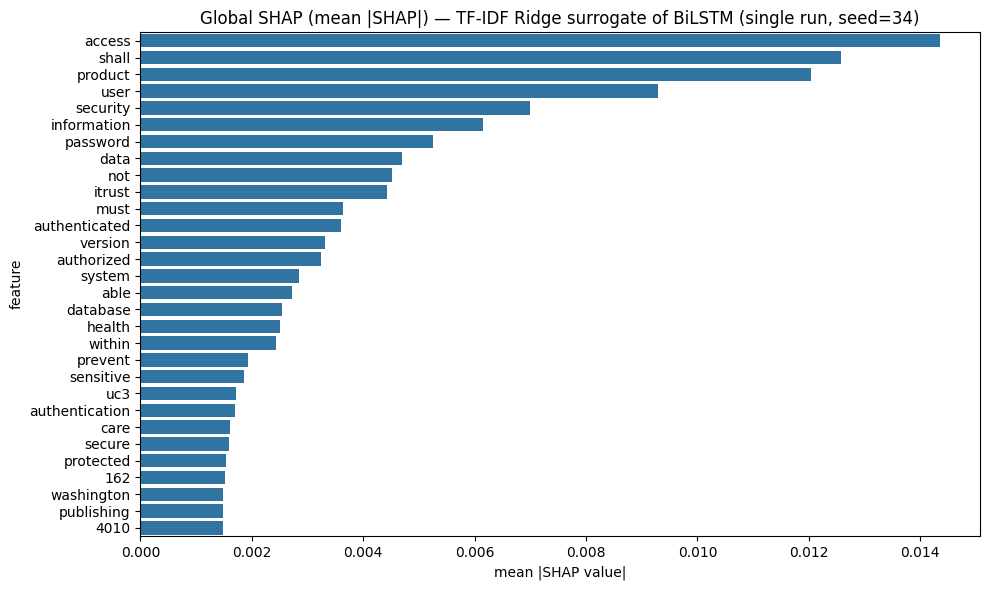


[INFO] All aggregate results, per-run CSVs, and figures saved to: /content/nfreqbilstm_multirun_results
[INFO] Files written:
   - accuracy_curve_mean.png
   - aggregate_metrics.csv
   - computational_cost.csv
   - confusion_matrix_mean.png
   - faithfulness_results.csv
   - lime_vs_tfidf_top20.csv
   - lime_vs_tfidf_top20.png
   - loss_curve_mean.png
   - per_class_metrics.csv
   - per_run_metrics.csv
   - shap_global_summary.png
   - summary.json

DONE: 10 runs completed.


In [ ]:
# Deps: pip install lime shap scikit-learn tensorflow matplotlib seaborn nltk pandas memory_profiler psutil

import os
import re
import json
import random
import time
import gc
import numpy as np
import pandas as pd
from memory_profiler import memory_usage

# -------- NLTK setup --------
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

# -------- ML / DL --------
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix
)
from sklearn.multioutput import MultiOutputRegressor
from sklearn.linear_model import Ridge

import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import (Input, Embedding, Bidirectional, LSTM,
                                     GlobalMaxPooling1D, GlobalAveragePooling1D,
                                     Concatenate, Dense, Dropout, SpatialDropout1D)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# -------- Explainability --------
from lime.lime_text import LimeTextExplainer
import shap

# ============== Configuration ==============
CSV_PATH = "/content/NFR_five.csv"

# ---- Multi-run settings ----
N_RUNS = 10
BASE_SEED = 34
OUTPUT_DIR = "/content/nfreqbilstm_multirun_results"
SHAP_RUN_EVERY_ITERATION = False

TEST_SIZE = 0.20

# Tokenizer / Sequence params (for BiLSTM)
MAX_NUM_WORDS = 30000
MAX_LEN = 120
EMBED_DIM = 128
LSTM_UNITS = 128

# Classic TF-IDF space (for SHAP surrogate + comparison charts)
MAX_FEATURES_TFIDF = 5000

EPOCHS = 12
BATCH_SIZE = 32

INFERENCE_TIMING_REPEATS = 5   # repeat full-test-set inference this many times, average

# LIME / Faithfulness parameters
LIME_NUM_SAMPLES = 1000         # perturbations per instance
LIME_NUM_FEATURES = 10          # tokens highlighted per instance
LIME_SUBSET_SIZE = 100          # how many test rows to explain (cap)
FAITHFULNESS_TOPK = [3, 5, 10]  # deletion tests

# SHAP parameters (fast via LinearExplainer on the surrogate)
RUN_SHAP = True
SHAP_EVAL_SIZE = 100            # from test set

EXPECTED_CATEGORIES = [
    "Maintainability", "Operability", "Performance", "Security", "Usability"
]

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============== Cleaning / Preprocessing ==============
REPLACE_BY_SPACE = re.compile(r'[/(){}|@,;]')
STOPWORDS = set(stopwords.words("english"))

# Preserve negation
for w in ["not", "no", "nor"]:
    STOPWORDS.discard(w)

lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = REPLACE_BY_SPACE.sub(" ", text)
    text = re.sub(r"\s+", " ", text).strip()

    tokens = text.split()

    tokens = [
        lemmatizer.lemmatize(t)
        for t in tokens
        if t not in STOPWORDS
    ]

    return " ".join(tokens)

# ============== Load & filter data once (shared across all runs) ==============
df = pd.read_csv(CSV_PATH, encoding='latin1')
if 'sentence' not in df.columns or 'class_name' not in df.columns:
    raise ValueError("CSV must contain columns: 'sentence' and 'class_name'")

df['sentence'] = df['sentence'].fillna('')
df['class_name'] = df['class_name'].fillna('')
df = df[df['class_name'].isin(EXPECTED_CATEGORIES)].reset_index(drop=True)
if df.empty:
    raise ValueError("No rows left after filtering by EXPECTED_CATEGORIES. Check your CSV or categories.")

df['text_clean'] = df['sentence'].apply(clean_text)

Y_df = pd.get_dummies(df['class_name'], dtype=int)
Y_df = Y_df.reindex(columns=EXPECTED_CATEGORIES, fill_value=0)
Y_all = Y_df.values
y_idx_all = Y_all.argmax(axis=1)
sentences_all = df['sentence'].tolist()
text_clean_all = df['text_clean'].tolist()

# ============== Model builder ==============
def create_bilstm_model(vocab_size: int, embed_dim: int, max_len: int, num_classes: int) -> tf.keras.Model:
    inp = Input(shape=(max_len,), name="tokens")
    x = Embedding(input_dim=vocab_size, output_dim=embed_dim, input_length=max_len, name="embed")(inp)
    x = SpatialDropout1D(0.2)(x)
    x = Bidirectional(LSTM(LSTM_UNITS, return_sequences=True))(x)
    maxp = GlobalMaxPooling1D()(x)
    avgp = GlobalAveragePooling1D()(x)
    x = Concatenate()([maxp, avgp])
    x = Dropout(0.4)(x)
    x = Dense(256, activation="relu")(x)
    x = Dropout(0.4)(x)
    out = Dense(num_classes, activation="softmax")(x)
    model = Model(inp, out)
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

def remove_tokens(raw_text: str, tokens_to_remove: list) -> str:
    words = raw_text.split()
    rem = set([t.lower() for t in tokens_to_remove])
    kept = [w for w in words if w.lower() not in rem]
    return " ".join(kept)

_GPU_AVAILABLE = len(tf.config.list_physical_devices('GPU')) > 0

def _reset_gpu_peak():
    if _GPU_AVAILABLE:
        try:
            tf.config.experimental.reset_memory_stats('GPU:0')
        except Exception:
            pass

def _get_gpu_peak_mb():
    if _GPU_AVAILABLE:
        try:
            info = tf.config.experimental.get_memory_info('GPU:0')
            return info['peak'] / (1024 ** 2)
        except Exception:
            return None
    return None

# ============================================================
# ===================== SINGLE RUN ===========================
# ============================================================
def run_once(seed: int, run_idx: int, run_shap_this_run: bool):
    print(f"\n{'='*70}\nRUN {run_idx+1}/{N_RUNS}  (seed={seed})\n{'='*70}")

    random.seed(seed)
    np.random.seed(seed)

    tf.keras.utils.set_random_seed(seed)

    rng = np.random.default_rng(seed)

    # ---- SPLIT INDICES ----
    train_idx_outer, test_idx = train_test_split(
        np.arange(len(text_clean_all)),
        test_size=TEST_SIZE,
        random_state=seed,
        stratify=y_idx_all
    )

    # ---- Split train partition further into train/validation ----
    y_train_outer_idx = y_idx_all[train_idx_outer]
    train_idx, val_idx = train_test_split(
        train_idx_outer,
        test_size=0.15,
        random_state=seed,
        stratify=y_train_outer_idx
    )

    # ---- TEXTS ----
    train_texts_clean = [text_clean_all[i] for i in train_idx]
    val_texts_clean = [text_clean_all[i] for i in val_idx]
    test_texts_clean = [text_clean_all[i] for i in test_idx]

    test_sentences = [sentences_all[i] for i in test_idx]

    # ---- LABELS ----
    Y_train = Y_all[train_idx]
    Y_val = Y_all[val_idx]
    Y_test = Y_all[test_idx]

    y_val_idx = y_idx_all[val_idx]
    y_test_idx = y_idx_all[test_idx]

    # ---- Tokenizer + Sequences (fit on TRAIN ONLY to avoid leakage) ----
    tokenizer = Tokenizer(num_words=MAX_NUM_WORDS, oov_token="<OOV>")
    tokenizer.fit_on_texts(train_texts_clean)

    seqs_train = tokenizer.texts_to_sequences(train_texts_clean)
    seqs_val = tokenizer.texts_to_sequences(val_texts_clean)
    seqs_test = tokenizer.texts_to_sequences(test_texts_clean)
    X_seq_train = pad_sequences(seqs_train, maxlen=MAX_LEN, padding='post', truncating='post')
    X_seq_val = pad_sequences(seqs_val, maxlen=MAX_LEN, padding='post', truncating='post')
    X_seq_test = pad_sequences(seqs_test, maxlen=MAX_LEN, padding='post', truncating='post')

    # ---- TF-IDF ----
    tfidf = TfidfVectorizer(
        max_features=MAX_FEATURES_TFIDF,
        min_df=1,
        smooth_idf=True,
        norm='l2'
    )

    X_tfidf_train = tfidf.fit_transform(train_texts_clean).toarray()
    X_tfidf_test = tfidf.transform(test_texts_clean).toarray()

    test_texts = test_sentences

    vocab_size = min(MAX_NUM_WORDS, len(tokenizer.word_index) + 1)
    num_classes = Y_train.shape[1]
    model = create_bilstm_model(vocab_size, EMBED_DIM, MAX_LEN, num_classes)

    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6, verbose=0)
    early_stop = EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)

    trainable_params = int(np.sum([tf.keras.backend.count_params(w) for w in model.trainable_weights]))

    gc.collect()
    _reset_gpu_peak()

    def _fit_call():
        return model.fit(
            X_seq_train, Y_train,
            epochs=EPOCHS, batch_size=BATCH_SIZE,
            validation_data=(X_seq_val, Y_val),
            callbacks=[reduce_lr, early_stop], verbose=0
        )

    t0 = time.time()
    mem_during_train = memory_usage((_fit_call, (), {}), interval=0.2, max_usage=True, retval=True)
    train_time_sec = time.time() - t0
    peak_mem_train_mb, history = mem_during_train
    gpu_peak_train_mb = _get_gpu_peak_mb()

    # ---- classification metrics ----
    y_proba = model.predict(X_seq_test, verbose=0)  # warm-up call, excluded from timing

    gc.collect()
    _reset_gpu_peak()

    def _predict_call():
        return model.predict(X_seq_test, verbose=0)

    inf_times = []
    peak_mem_inf_mb = 0.0
    for _ in range(INFERENCE_TIMING_REPEATS):
        t0 = time.time()
        mem_usage_val, _ = memory_usage((_predict_call, (), {}), interval=0.2, max_usage=True, retval=True)
        inf_times.append(time.time() - t0)
        peak_mem_inf_mb = max(peak_mem_inf_mb, mem_usage_val)

    n_test_items = X_seq_test.shape[0]
    inference_time_per_item_sec = float(np.mean(inf_times)) / n_test_items
    gpu_peak_inf_mb = _get_gpu_peak_mb()

    peak_memory_mb = max(peak_mem_train_mb, peak_mem_inf_mb)
    gpu_peak_mb = None
    if gpu_peak_train_mb is not None or gpu_peak_inf_mb is not None:
        gpu_peak_mb = max(x for x in [gpu_peak_train_mb, gpu_peak_inf_mb] if x is not None)

    y_pred_idx = np.argmax(y_proba, axis=1)
    y_true_idx = y_test_idx

    cm = confusion_matrix(y_true_idx, y_pred_idx, labels=np.arange(len(EXPECTED_CATEGORIES)))
    acc = accuracy_score(y_true_idx, y_pred_idx)
    prec_macro = precision_score(y_true_idx, y_pred_idx, average='macro', zero_division=0)
    rec_macro = recall_score(y_true_idx, y_pred_idx, average='macro', zero_division=0)
    f1_macro = f1_score(y_true_idx, y_pred_idx, average='macro', zero_division=0)
    prec_weighted = precision_score(y_true_idx, y_pred_idx, average='weighted', zero_division=0)
    rec_weighted = recall_score(y_true_idx, y_pred_idx, average='weighted', zero_division=0)
    f1_weighted = f1_score(y_true_idx, y_pred_idx, average='weighted', zero_division=0)

    per_class_report = classification_report(
        y_true_idx, y_pred_idx, labels=np.arange(len(EXPECTED_CATEGORIES)),
        target_names=EXPECTED_CATEGORIES, digits=4, zero_division=0, output_dict=True
    )

    train_loss, train_acc = model.evaluate(X_seq_train, Y_train, verbose=0)
    test_loss, test_acc = model.evaluate(X_seq_test, Y_test, verbose=0)

    print(f"  Acc={acc:.4f}  F1(macro)={f1_macro:.4f}  F1(weighted)={f1_weighted:.4f}")

    # ---- LIME on test subset ----
    def _texts_to_seq(texts):
        cleaned = [clean_text(t) for t in texts]
        sq = tokenizer.texts_to_sequences(cleaned)
        return pad_sequences(sq, maxlen=MAX_LEN, padding='post', truncating='post')

    def predict_proba_texts(texts: list) -> np.ndarray:
        X_ = _texts_to_seq(texts)
        return model.predict(X_, verbose=0)

    explainer = LimeTextExplainer(class_names=EXPECTED_CATEGORIES, bow=True)
    test_indices = np.arange(len(test_texts))
    rng.shuffle(test_indices)
    subset_idx = test_indices[:min(LIME_SUBSET_SIZE, len(test_texts))]
    subset_texts = [test_texts[i] for i in subset_idx]

    lime_fidelities, lime_sparsities = [], []
    lime_token_weights_per_word = {}
    faithfulness_results = {k: [] for k in FAITHFULNESS_TOPK}

    for t in subset_texts:
        proba = predict_proba_texts([t])[0]
        pred_label = int(np.argmax(proba))
        exp = explainer.explain_instance(
            t, predict_proba_texts,
            num_features=LIME_NUM_FEATURES, num_samples=LIME_NUM_SAMPLES,
            labels=[pred_label]
        )
        lime_fidelities.append(exp.score)
        items = exp.as_list(label=pred_label)
        lime_sparsities.append(len(items))
        for tok, w in items:
            if w > 0:
                lime_token_weights_per_word.setdefault(tok.lower(), []).append(w)

        top_tokens = [tok for tok, w in sorted(items, key=lambda x: -x[1]) if w > 0]
        p_full = proba
        for k in FAITHFULNESS_TOPK:
            picked = top_tokens[:min(k, len(top_tokens))]
            t_del = remove_tokens(t, picked)
            p_del = predict_proba_texts([t_del])[0]
            drop = p_full[pred_label] - p_del[pred_label]
            faithfulness_results[k].append(max(0.0, drop))

    lime_summary = {
        "fidelity_mean": float(np.mean(lime_fidelities)),
        "fidelity_std": float(np.std(lime_fidelities)),
        "sparsity_mean": float(np.mean(lime_sparsities)),
        "n_explained": len(subset_texts),
    }
    faithfulness_summary = {
        k: {"mean": float(np.mean(v)), "std": float(np.std(v))}
        for k, v in faithfulness_results.items()
    }

    print(f"  LIME fidelity={lime_summary['fidelity_mean']:.3f}±{lime_summary['fidelity_std']:.3f}  "
          f"Faithfulness@5={faithfulness_summary[5]['mean']:.4f}")

    # ---- SHAP via TF-IDF Ridge surrogate (optional, run 0 by default) ----
    shap_top_features = None
    surrogate_kl = None
    if RUN_SHAP and run_shap_this_run:
        try:
            print("  Fitting TF-IDF Ridge surrogate + computing SHAP...")
            y_soft_train = model.predict(X_seq_train, verbose=0)
            surrogate = MultiOutputRegressor(Ridge(alpha=1.0, random_state=seed))
            surrogate.fit(X_tfidf_train, y_soft_train)

            y_soft_test_bilstm = model.predict(X_seq_test, verbose=0)
            y_soft_test_surr = surrogate.predict(X_tfidf_test)
            eps = 1e-9
            surrogate_kl = float(np.mean(np.sum(
                (y_soft_test_bilstm + eps) * (np.log((y_soft_test_bilstm + eps) / (y_soft_test_surr + eps))),
                axis=1
            )))
            print(f"  [Surrogate vs BiLSTM] mean KL-like divergence on test: {surrogate_kl:.4f}")

            ev_idx = rng.choice(len(X_tfidf_test), size=min(SHAP_EVAL_SIZE, len(X_tfidf_test)), replace=False)
            X_ev = X_tfidf_test[ev_idx]

            vocab_items = sorted(tfidf.vocabulary_.items(), key=lambda kv: kv[1])
            feature_names = np.array([w for w, idx in vocab_items])
            C = Y_train.shape[1]

            mean_abs_list = []
            for k in range(C):
                estimator_k = surrogate.estimators_[k]
                explainer_k = shap.LinearExplainer(estimator_k, X_tfidf_train, feature_perturbation="interventional")
                sv_k = explainer_k.shap_values(X_ev)
                mean_abs_list.append(np.mean(np.abs(sv_k), axis=0))
            mean_abs_global = np.mean(np.stack(mean_abs_list, axis=0), axis=0)

            mag = np.asarray(mean_abs_global, dtype=float).reshape(-1)
            V2 = min(feature_names.shape[0], mag.shape[0])
            mag = mag[:V2]
            feature_names = feature_names[:V2]
            order = np.argsort(mag)[::-1][:min(30, V2)]
            shap_top_features = list(zip(feature_names[order].tolist(), mag[order].tolist()))
        except Exception as e:
            print(f"  [SHAP skipped] {e}")

    return {
        "seed": seed,
        "history": history.history,
        "confusion_matrix": cm,
        "metrics": {
            "accuracy": acc, "precision_macro": prec_macro, "recall_macro": rec_macro,
            "f1_macro": f1_macro, "precision_weighted": prec_weighted,
            "recall_weighted": rec_weighted, "f1_weighted": f1_weighted,
            "train_acc": float(train_acc), "test_acc": float(test_acc),
            "train_loss": float(train_loss), "test_loss": float(test_loss),
        },
        "per_class_report": per_class_report,
        "lime_summary": lime_summary,
        "faithfulness_summary": faithfulness_summary,
        "lime_token_weights": lime_token_weights_per_word,
        "shap_top_features": shap_top_features,
        "surrogate_kl": surrogate_kl,
        "tfidf_test_matrix": X_tfidf_test,
        "tfidf_vocab": dict(tfidf.vocabulary_),
        "computational_cost": {
            "trainable_params": trainable_params,
            "train_time_sec": float(train_time_sec),
            "inference_time_per_item_sec": float(inference_time_per_item_sec),
            "peak_memory_mb": float(peak_memory_mb),
            "gpu_peak_memory_mb": gpu_peak_mb,
        },
    }

# ============================================================
# ===================== DRIVER LOOP ===========================
# ============================================================
all_results = []
for i in range(N_RUNS):
    seed_i = BASE_SEED + i
    shap_this_run = (i == 0) if not SHAP_RUN_EVERY_ITERATION else True
    res = run_once(seed_i, i, run_shap_this_run=shap_this_run)
    all_results.append(res)

# ============================================================
# ================= AGGREGATION / REPORTING ===================
# ============================================================
def agg_mean_std(values):
    arr = np.array(values, dtype=float)
    return float(np.mean(arr)), float(np.std(arr))

metric_keys = list(all_results[0]["metrics"].keys())
agg_metrics = {}
for mk in metric_keys:
    vals = [r["metrics"][mk] for r in all_results]
    mean_v, std_v = agg_mean_std(vals)
    agg_metrics[mk] = {"mean": mean_v, "std": std_v, "values": vals}

print(f"\n{'='*70}\nAGGREGATE RESULTS OVER {N_RUNS} RUNS (seeds {BASE_SEED}..{BASE_SEED+N_RUNS-1})\n{'='*70}")
metrics_table = pd.DataFrame({
    "metric": metric_keys,
    "mean": [agg_metrics[m]["mean"] for m in metric_keys],
    "std": [agg_metrics[m]["std"] for m in metric_keys],
})
print(metrics_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

per_class_rows = []
for cat in EXPECTED_CATEGORIES:
    p_vals = [r["per_class_report"][cat]["precision"] for r in all_results]
    r_vals = [r["per_class_report"][cat]["recall"] for r in all_results]
    f_vals = [r["per_class_report"][cat]["f1-score"] for r in all_results]
    s_vals = [r["per_class_report"][cat]["support"] for r in all_results]
    p_m, p_s = agg_mean_std(p_vals)
    r_m, r_s = agg_mean_std(r_vals)
    f_m, f_s = agg_mean_std(f_vals)
    per_class_rows.append({
        "class": cat,
        "precision_mean": p_m, "precision_std": p_s,
        "recall_mean": r_m, "recall_std": r_s,
        "f1_mean": f_m, "f1_std": f_s,
        "support_mean": float(np.mean(s_vals)),
    })
per_class_df = pd.DataFrame(per_class_rows)
print("\n=== Per-class metrics (mean ± std across runs) ===")
print(per_class_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# ---- Computational cost aggregation ----
cost_keys = ["trainable_params", "train_time_sec", "inference_time_per_item_sec", "peak_memory_mb"]
cost_rows = []
for ck in cost_keys:
    vals = [r["computational_cost"][ck] for r in all_results]
    m, s = agg_mean_std(vals)
    cost_rows.append({"metric": ck, "mean": m, "std": s})

gpu_vals = [r["computational_cost"]["gpu_peak_memory_mb"] for r in all_results
            if r["computational_cost"]["gpu_peak_memory_mb"] is not None]
if gpu_vals:
    gm, gs = agg_mean_std(gpu_vals)
    cost_rows.append({"metric": "gpu_peak_memory_mb", "mean": gm, "std": gs})

cost_df = pd.DataFrame(cost_rows)
print(f"\n=== Computational cost (mean ± std over {N_RUNS} runs) ===")
print(cost_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
cost_df.to_csv(os.path.join(OUTPUT_DIR, "computational_cost.csv"), index=False)

lime_fid_vals = [r["lime_summary"]["fidelity_mean"] for r in all_results]
lime_sparsity_vals = [r["lime_summary"]["sparsity_mean"] for r in all_results]
fid_m, fid_s = agg_mean_std(lime_fid_vals)
spar_m, spar_s = agg_mean_std(lime_sparsity_vals)
print(f"\n=== LIME (aggregated over {N_RUNS} runs, {LIME_SUBSET_SIZE} instances/run) ===")
print(f"Fidelity:  {fid_m:.4f} ± {fid_s:.4f}")
print(f"Sparsity:  {spar_m:.4f} ± {spar_s:.4f}")

print(f"\n=== Faithfulness (Deletion Test), aggregated over {N_RUNS} runs ===")
faith_rows = []
for k in FAITHFULNESS_TOPK:
    vals = [r["faithfulness_summary"][k]["mean"] for r in all_results]
    m, s = agg_mean_std(vals)
    faith_rows.append({"top_k": k, "mean_prob_drop": m, "std_prob_drop": s})
    print(f"Top-{k} removal -> Avg prob drop: {m:.4f} ± {s:.4f}")
faith_df = pd.DataFrame(faith_rows)

# ---- surrogate KL (only available for the run(s) that ran SHAP) ----
kl_vals = [r["surrogate_kl"] for r in all_results if r["surrogate_kl"] is not None]
if kl_vals:
    kl_m, kl_s = agg_mean_std(kl_vals)
    print(f"\n=== TF-IDF Ridge Surrogate Fidelity (KL-like divergence vs BiLSTM) ===")
    print(f"Mean KL-like divergence: {kl_m:.4f} ± {kl_s:.4f}  (n={len(kl_vals)} run(s))")

# ---- averaged confusion matrix ----
cm_stack = np.stack([r["confusion_matrix"] for r in all_results], axis=0)
cm_mean = cm_stack.mean(axis=0)

plt.figure(figsize=(10,7))
sns.heatmap(cm_mean, annot=True, fmt='.1f', cmap='Blues',
            xticklabels=EXPECTED_CATEGORIES, yticklabels=EXPECTED_CATEGORIES)
plt.title(f'NFReqBiLSTM Confusion Matrix (mean over {N_RUNS} runs)')
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix_mean.png"), dpi=150)
plt.show()

# ---- averaged training curves ----
min_epochs = min(len(r["history"]["accuracy"]) for r in all_results)
train_acc_mat = np.stack([r["history"]["accuracy"][:min_epochs] for r in all_results])
val_acc_mat = np.stack([r["history"]["val_accuracy"][:min_epochs] for r in all_results])
train_loss_mat = np.stack([r["history"]["loss"][:min_epochs] for r in all_results])
val_loss_mat = np.stack([r["history"]["val_loss"][:min_epochs] for r in all_results])
epochs_axis = np.arange(1, min_epochs + 1)

plt.figure(figsize=(7,5))
plt.plot(epochs_axis, train_acc_mat.mean(axis=0), label='Train (mean)')
plt.fill_between(epochs_axis, train_acc_mat.mean(0)-train_acc_mat.std(0),
                  train_acc_mat.mean(0)+train_acc_mat.std(0), alpha=0.2)
plt.plot(epochs_axis, val_acc_mat.mean(axis=0), label='Validation (mean)')
plt.fill_between(epochs_axis, val_acc_mat.mean(0)-val_acc_mat.std(0),
                  val_acc_mat.mean(0)+val_acc_mat.std(0), alpha=0.2)
plt.title(f'NFReqBiLSTM Accuracy (mean ± std over {N_RUNS} runs)')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "accuracy_curve_mean.png"), dpi=150)
plt.show()

plt.figure(figsize=(7,5))
plt.plot(epochs_axis, train_loss_mat.mean(axis=0), label='Train (mean)')
plt.fill_between(epochs_axis, train_loss_mat.mean(0)-train_loss_mat.std(0),
                  train_loss_mat.mean(0)+train_loss_mat.std(0), alpha=0.2)
plt.plot(epochs_axis, val_loss_mat.mean(axis=0), label='Validation (mean)')
plt.fill_between(epochs_axis, val_loss_mat.mean(0)-val_loss_mat.std(0),
                  val_loss_mat.mean(0)+val_loss_mat.std(0), alpha=0.2)
plt.title(f'NFReqBiLSTM Loss (mean ± std over {N_RUNS} runs)')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "loss_curve_mean.png"), dpi=150)
plt.show()

# ---- LIME vs TF-IDF top-20 words, aggregated across all runs ----
combined_lime_weights = {}
for r in all_results:
    for w, ws in r["lime_token_weights"].items():
        combined_lime_weights.setdefault(w, []).extend(ws)
lime_avg_pos = {w: np.mean(ws) for w, ws in combined_lime_weights.items() if len(ws) > 0}

last_run = all_results[-1]
vocab_ref = last_run["tfidf_vocab"]
X_ref = last_run["tfidf_test_matrix"]

def avg_tfidf_for_word(w):
    idx = vocab_ref.get(w, None)
    if idx is None or idx >= X_ref.shape[1]:
        return 0.0
    return float(np.mean(X_ref[:, idx]))

pairs = [(w, avg_w, avg_tfidf_for_word(w)) for w, avg_w in lime_avg_pos.items()]
comp_df = pd.DataFrame(pairs, columns=["word", "avg_positive_lime_weight", "avg_tfidf"])
comp_top20 = comp_df.sort_values("avg_positive_lime_weight", ascending=False).head(20).reset_index(drop=True)

print(f"\n=== Top-20 words by avg positive LIME weight, aggregated over {N_RUNS} runs ===")
print(comp_top20.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

plt.figure(figsize=(10,7))
indices = np.arange(len(comp_top20))
barw = 0.45
plt.barh(indices + 0.0, comp_top20["avg_positive_lime_weight"].values, height=barw, label="Avg + LIME weight")
plt.barh(indices + barw, comp_top20["avg_tfidf"].values, height=barw, label="Avg TF-IDF")
plt.yticks(indices + barw/2, comp_top20["word"].values)
plt.gca().invert_yaxis()
plt.title(f"Top-20 LIME (+) vs TF-IDF frequency (aggregated, {N_RUNS} runs)")
plt.xlabel("value"); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "lime_vs_tfidf_top20.png"), dpi=150)
plt.show()

# ---- SHAP (from whichever run computed it) ----
shap_run = next((r for r in all_results if r["shap_top_features"] is not None), None)
if shap_run is not None:
    feats, vals = zip(*shap_run["shap_top_features"])
    plt.figure(figsize=(10,6))
    sns.barplot(x=list(vals), y=list(feats), orient='h')
    note = "single run" if not SHAP_RUN_EVERY_ITERATION else "averaged"
    plt.title(f"Global SHAP (mean |SHAP|) — TF-IDF Ridge surrogate of BiLSTM ({note}, seed={shap_run['seed']})")
    plt.xlabel("mean |SHAP value|"); plt.ylabel("feature")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "shap_global_summary.png"), dpi=150)
    plt.show()

# ============================================================
# ===================== SAVE ARTIFACTS =========================
# ============================================================
metrics_table.to_csv(os.path.join(OUTPUT_DIR, "aggregate_metrics.csv"), index=False)
per_class_df.to_csv(os.path.join(OUTPUT_DIR, "per_class_metrics.csv"), index=False)
faith_df.to_csv(os.path.join(OUTPUT_DIR, "faithfulness_results.csv"), index=False)
comp_top20.to_csv(os.path.join(OUTPUT_DIR, "lime_vs_tfidf_top20.csv"), index=False)

run_level_rows = []
for r in all_results:
    row = {"seed": r["seed"], **r["metrics"], **r["computational_cost"],
           "lime_fidelity": r["lime_summary"]["fidelity_mean"],
           "lime_sparsity": r["lime_summary"]["sparsity_mean"],
           "surrogate_kl": r["surrogate_kl"]}
    for k in FAITHFULNESS_TOPK:
        row[f"faithfulness_top{k}"] = r["faithfulness_summary"][k]["mean"]
    run_level_rows.append(row)
run_level_df = pd.DataFrame(run_level_rows)
run_level_df.to_csv(os.path.join(OUTPUT_DIR, "per_run_metrics.csv"), index=False)

summary_json = {
    "n_runs": N_RUNS,
    "seeds": [r["seed"] for r in all_results],
    "metrics_mean_std": {m: {"mean": agg_metrics[m]["mean"], "std": agg_metrics[m]["std"]} for m in metric_keys},
    "lime_fidelity_mean_std": {"mean": fid_m, "std": fid_s},
    "lime_sparsity_mean_std": {"mean": spar_m, "std": spar_s},
    "faithfulness_mean_std": {str(k): {"mean": float(np.mean([r["faithfulness_summary"][k]["mean"] for r in all_results])),
                                        "std": float(np.std([r["faithfulness_summary"][k]["mean"] for r in all_results]))}
                               for k in FAITHFULNESS_TOPK},
    "surrogate_kl_mean_std": {"mean": kl_m, "std": kl_s} if kl_vals else None,
}
with open(os.path.join(OUTPUT_DIR, "summary.json"), "w") as f:
    json.dump(summary_json, f, indent=2)

print(f"\n[INFO] All aggregate results, per-run CSVs, and figures saved to: {OUTPUT_DIR}")
print("[INFO] Files written:")
for fn in sorted(os.listdir(OUTPUT_DIR)):
    print(f"   - {fn}")

print(f"\n{'='*70}\nDONE: {N_RUNS} runs completed.\n{'='*70}")

# Baseline ANN (multiseed)

In [ ]:
pip install lime shap scikit-learn tensorflow matplotlib seaborn nltk pandas memory_profiler psutil


RUN 1/10  (seed=34)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


  Acc=0.8142  F1(macro)=0.7826  F1(weighted)=0.8069
  LIME fidelity=0.854±0.134  Faithfulness@5=0.3447
  Running SHAP (KernelExplainer)...


  0%|          | 0/100 [00:00<?, ?it/s]


RUN 2/10  (seed=35)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


... (13 outputs left out)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


  Acc=0.8798  F1(macro)=0.8683  F1(weighted)=0.8786
  LIME fidelity=0.708±0.234  Faithfulness@5=0.3813

RUN 10/10  (seed=43)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


  Acc=0.8306  F1(macro)=0.7970  F1(weighted)=0.8271
  LIME fidelity=0.793±0.180  Faithfulness@5=0.3467

AGGREGATE RESULTS OVER 10 RUNS (seeds 34..43)
            metric   mean    std
          accuracy 0.8388 0.0263
   precision_macro 0.8376 0.0246
      recall_macro 0.8117 0.0352
          f1_macro 0.8198 0.0309
precision_weighted 0.8414 0.0251
   recall_weighted 0.8388 0.0263
       f1_weighted 0.8358 0.0274
         train_acc 0.9919 0.0016
          test_acc 0.8388 0.0263
        train_loss 0.0585 0.0306
         test_loss 0.5180 0.0890

=== Per-class metrics (mean ± std across runs) ===
          class  precision_mean  precision_std  recall_mean  recall_std  f1_mean  f1_std  support_mean
Maintainability          0.7823         0.0713       0.7296      0.0684   0.7517  0.0480       27.0000
    Operability          0.7778         0.0449       0.7452      0.1045   0.7567  0.0602       31.0000
    Performance          0.8879         0.0459       0.8652      0.1090   0.8716  0.0583     

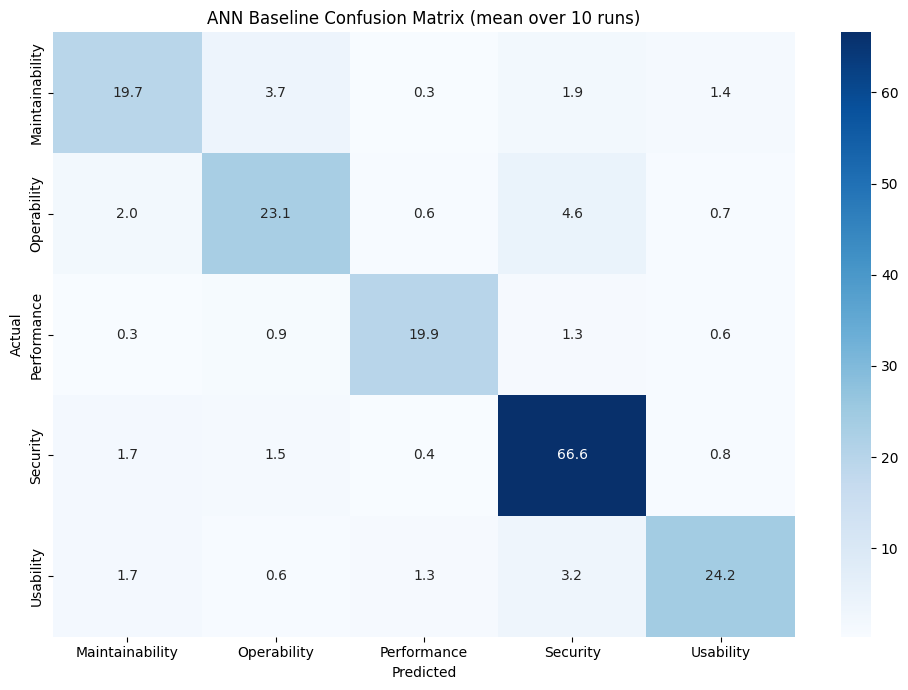

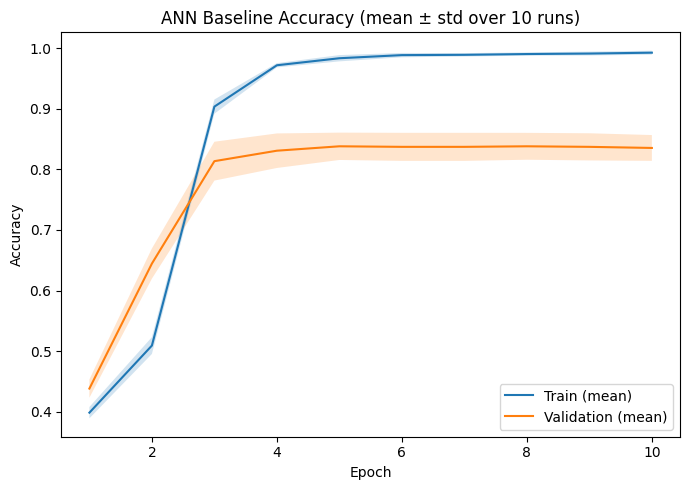

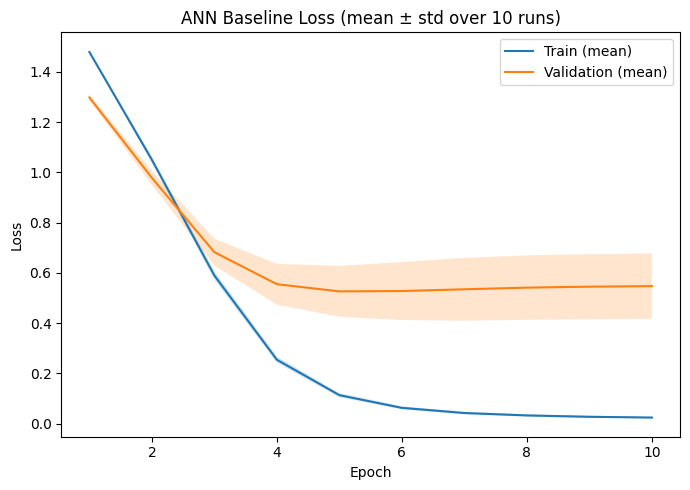


=== Top-20 words by avg positive LIME weight, aggregated over 10 runs ===
         word  avg_positive_lime_weight  avg_tfidf
  independent                    0.4948     0.0000
        space                    0.4177     0.0000
        loinc                    0.3794     0.0000
      viruses                    0.3783     0.0032
      element                    0.3691     0.0034
         code                    0.3629     0.0028
          let                    0.3189     0.0014
        above                    0.3078     0.0000
automatically                    0.3073     0.0000
          000                    0.3054     0.0082
     discrete                    0.3038     0.0019
     problems                    0.3036     0.0028
      objects                    0.2903     0.0000
        codes                    0.2832     0.0000
         free                    0.2777     0.0032
      pattern                    0.2763     0.0042
       retain                    0.2758     0.0018
       

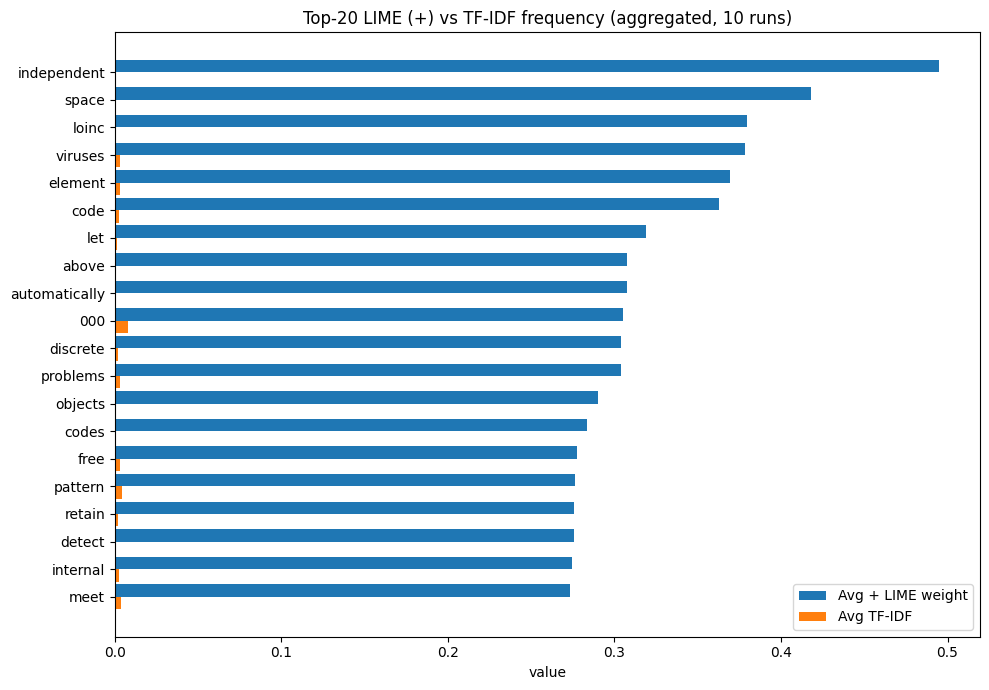

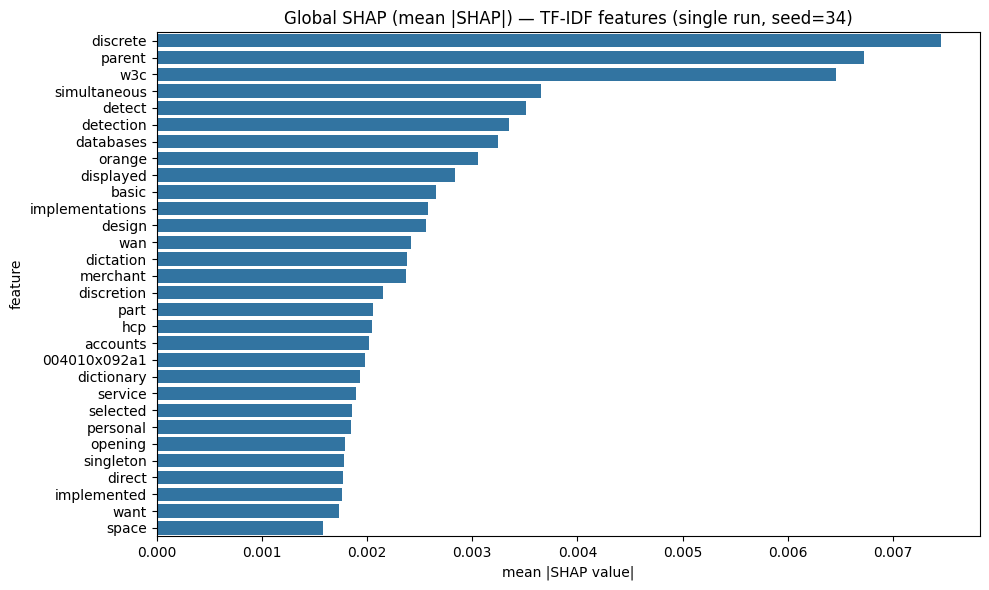


[INFO] All aggregate results, per-run CSVs, and figures saved to: /content/ann_baseline_multirun_results
[INFO] Files written:
   - accuracy_curve_mean.png
   - aggregate_metrics.csv
   - computational_cost.csv
   - confusion_matrix_mean.png
   - faithfulness_results.csv
   - lime_vs_tfidf_top20.csv
   - lime_vs_tfidf_top20.png
   - loss_curve_mean.png
   - per_class_metrics.csv
   - per_run_metrics.csv
   - shap_global_summary.png
   - summary.json

DONE: 10 runs completed.


In [ ]:
# Deps: pip install lime shap scikit-learn tensorflow matplotlib seaborn nltk pandas memory_profiler psutil

import os
import re
import json
import random
import time
import gc
import numpy as np
import pandas as pd
from memory_profiler import memory_usage

# -------- NLTK setup --------
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

# -------- ML / DL --------
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

# -------- Explainability --------
from lime.lime_text import LimeTextExplainer
import shap

# ============== Configuration ==============
CSV_PATH = "/content/NFR_five.csv"

# ---- Multi-run settings ----
N_RUNS = 10                       # how many times to repeat the whole pipeline (5-10 recommended)
BASE_SEED = 34                    # run i uses seed = BASE_SEED + i (different split + init each run)
OUTPUT_DIR = "/content/ann_baseline_multirun_results"
SHAP_RUN_EVERY_ITERATION = False  # False = run SHAP once (run 0 only) -> standard practice, much faster

TEST_SIZE = 0.20
MAX_FEATURES = 5000
EPOCHS = 12
BATCH_SIZE = 32

INFERENCE_TIMING_REPEATS = 5   # repeat full-test-set inference this many times, average

# LIME / Faithfulness parameters
LIME_NUM_SAMPLES = 1000         # perturbations per instance
LIME_NUM_FEATURES = 10          # tokens highlighted per instance
LIME_SUBSET_SIZE = 100          # how many test rows to explain (cap)
FAITHFULNESS_TOPK = [3, 5, 10]  # deletion tests

# SHAP parameters (keep small for speed)
RUN_SHAP = True
SHAP_BACKGROUND_SIZE = 50       # from train set
SHAP_EVAL_SIZE = 100            # from test set
SHAP_NSAMPLES = 200             # Kernel SHAP nsamples

EXPECTED_CATEGORIES = [
    "Maintainability", "Operability", "Performance", "Security", "Usability"
]

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============== Cleaning / Preprocessing ==============
REPLACE_BY_SPACE = re.compile(r'[/(){}|@,;]')
STOPWORDS = set(stopwords.words("english"))

# Preserve negation
for w in ["not", "no", "nor"]:
    STOPWORDS.discard(w)

lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = REPLACE_BY_SPACE.sub(" ", text)
    text = re.sub(r"\s+", " ", text).strip()

    tokens = text.split()

    tokens = [
        lemmatizer.lemmatize(t)
        for t in tokens
        if t not in STOPWORDS
    ]

    return " ".join(tokens)

# ============== Load & filter data once (shared across all runs) ==============
df = pd.read_csv(CSV_PATH, encoding='latin1')
if 'sentence' not in df.columns or 'class_name' not in df.columns:
    raise ValueError("CSV must contain columns: 'sentence' and 'class_name'")

df['sentence'] = df['sentence'].fillna('')
df['class_name'] = df['class_name'].fillna('')

# *** Critical fix preserved: keep ONLY rows within EXPECTED_CATEGORIES ***
df = df[df['class_name'].isin(EXPECTED_CATEGORIES)].reset_index(drop=True)
if df.empty:
    raise ValueError("No rows left after filtering by EXPECTED_CATEGORIES. Check your CSV or categories.")

df['text_clean'] = df['sentence'].apply(clean_text)

Y_df = pd.get_dummies(df['class_name'], dtype=int)
Y_df = Y_df.reindex(columns=EXPECTED_CATEGORIES, fill_value=0)
Y_all = Y_df.values
y_idx_all = Y_all.argmax(axis=1)
sentences_all = df['sentence'].tolist()
text_clean_all = df['text_clean'].tolist()

# ============== Model builder (BASIC ANN BASELINE) ==============
def create_model(input_dim: int, num_classes: int) -> tf.keras.Model:
    # Baseline: single hidden layer + dropout, matching NFReqANN-TFIDF's first block
    model = Sequential([
        Dense(2048, activation="relu", input_dim=input_dim),
        Dropout(0.3),
        Dense(num_classes, activation="softmax"),
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

def remove_tokens(raw_text: str, tokens_to_remove: list) -> str:
    words = raw_text.split()
    rem = set([t.lower() for t in tokens_to_remove])
    kept = [w for w in words if w.lower() not in rem]
    return " ".join(kept)

_GPU_AVAILABLE = len(tf.config.list_physical_devices('GPU')) > 0

def _reset_gpu_peak():
    if _GPU_AVAILABLE:
        try:
            tf.config.experimental.reset_memory_stats('GPU:0')
        except Exception:
            pass

def _get_gpu_peak_mb():
    if _GPU_AVAILABLE:
        try:
            info = tf.config.experimental.get_memory_info('GPU:0')
            return info['peak'] / (1024 ** 2)
        except Exception:
            return None
    return None

# ============================================================
# ===================== SINGLE RUN ===========================
# ============================================================
def run_once(seed: int, run_idx: int, run_shap_this_run: bool):
    print(f"\n{'='*70}\nRUN {run_idx+1}/{N_RUNS}  (seed={seed})\n{'='*70}")

    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)
    rng = np.random.default_rng(seed)          # <-- was missing, used below

    # ---- Split indices first (avoids TF-IDF leakage) ----
    train_idx_outer, test_idx = train_test_split(
        np.arange(len(text_clean_all)),
        test_size=TEST_SIZE,
        random_state=seed,
        stratify=y_idx_all
    )

    # ---- Split train partition further into train/validation ----
    y_train_outer_idx = y_idx_all[train_idx_outer]
    train_idx, val_idx = train_test_split(
        train_idx_outer,
        test_size=0.15,
        random_state=seed,
        stratify=y_train_outer_idx
    )

    train_texts_clean = [text_clean_all[i] for i in train_idx]
    val_texts_clean = [text_clean_all[i] for i in val_idx]
    test_texts_clean = [text_clean_all[i] for i in test_idx]
    test_texts = [sentences_all[i] for i in test_idx]   # raw text for LIME

    Y_train = Y_all[train_idx]
    Y_val = Y_all[val_idx]
    Y_test = Y_all[test_idx]
    y_train_idx = y_idx_all[train_idx]
    y_val_idx = y_idx_all[val_idx]
    y_test_idx = y_idx_all[test_idx]

    # ---- TF-IDF fit on TRAIN ONLY, transform val and test ----
    tfidf = TfidfVectorizer(max_features=MAX_FEATURES, min_df=1, smooth_idf=True, norm='l2')
    X_train = tfidf.fit_transform(train_texts_clean).toarray()
    X_val = tfidf.transform(val_texts_clean).toarray()
    X_test = tfidf.transform(test_texts_clean).toarray()

    model = create_model(X_train.shape[1], num_classes=Y_train.shape[1])
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6, verbose=0)
    early_stop = EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)

    trainable_params = int(np.sum([tf.keras.backend.count_params(w) for w in model.trainable_weights]))

    gc.collect()
    _reset_gpu_peak()

    def _fit_call():
        return model.fit(
            X_train, Y_train,
            epochs=EPOCHS, batch_size=BATCH_SIZE,
            validation_data=(X_val, Y_val),
            callbacks=[reduce_lr, early_stop], verbose=0
        )

    t0 = time.time()
    mem_during_train = memory_usage((_fit_call, (), {}), interval=0.2, max_usage=True, retval=True)
    train_time_sec = time.time() - t0
    peak_mem_train_mb, history = mem_during_train
    gpu_peak_train_mb = _get_gpu_peak_mb()

    # ---- classification metrics ----
    y_proba = model.predict(X_test, verbose=0)  # warm-up call, excluded from timing

    gc.collect()
    _reset_gpu_peak()

    def _predict_call():
        return model.predict(X_test, verbose=0)

    inf_times = []
    peak_mem_inf_mb = 0.0
    for _ in range(INFERENCE_TIMING_REPEATS):
        t0 = time.time()
        mem_usage_val, _ = memory_usage((_predict_call, (), {}), interval=0.2, max_usage=True, retval=True)
        inf_times.append(time.time() - t0)
        peak_mem_inf_mb = max(peak_mem_inf_mb, mem_usage_val)

    n_test_items = X_test.shape[0]
    inference_time_per_item_sec = float(np.mean(inf_times)) / n_test_items
    gpu_peak_inf_mb = _get_gpu_peak_mb()

    peak_memory_mb = max(peak_mem_train_mb, peak_mem_inf_mb)
    gpu_peak_mb = None
    if gpu_peak_train_mb is not None or gpu_peak_inf_mb is not None:
        gpu_peak_mb = max(x for x in [gpu_peak_train_mb, gpu_peak_inf_mb] if x is not None)

    y_pred_idx = np.argmax(y_proba, axis=1)
    y_true_idx = y_test_idx

    cm = confusion_matrix(y_true_idx, y_pred_idx, labels=np.arange(len(EXPECTED_CATEGORIES)))
    acc = accuracy_score(y_true_idx, y_pred_idx)
    prec_macro = precision_score(y_true_idx, y_pred_idx, average='macro', zero_division=0)
    rec_macro = recall_score(y_true_idx, y_pred_idx, average='macro', zero_division=0)
    f1_macro = f1_score(y_true_idx, y_pred_idx, average='macro', zero_division=0)
    prec_weighted = precision_score(y_true_idx, y_pred_idx, average='weighted', zero_division=0)
    rec_weighted = recall_score(y_true_idx, y_pred_idx, average='weighted', zero_division=0)
    f1_weighted = f1_score(y_true_idx, y_pred_idx, average='weighted', zero_division=0)

    per_class_report = classification_report(
        y_true_idx, y_pred_idx, labels=np.arange(len(EXPECTED_CATEGORIES)),
        target_names=EXPECTED_CATEGORIES, digits=4, zero_division=0, output_dict=True
    )

    train_loss, train_acc = model.evaluate(X_train, Y_train, verbose=0)
    test_loss, test_acc = model.evaluate(X_test, Y_test, verbose=0)

    print(f"  Acc={acc:.4f}  F1(macro)={f1_macro:.4f}  F1(weighted)={f1_weighted:.4f}")

    # ---- LIME on test subset ----
    def predict_proba_texts(texts):
        cleaned = [clean_text(t) for t in texts]
        X_ = tfidf.transform(cleaned).toarray()
        return model.predict(X_, verbose=0)

    explainer = LimeTextExplainer(class_names=EXPECTED_CATEGORIES, bow=True)
    test_indices = np.arange(len(test_texts))
    rng.shuffle(test_indices)
    subset_idx = test_indices[:min(LIME_SUBSET_SIZE, len(test_texts))]
    subset_texts = [test_texts[i] for i in subset_idx]

    lime_fidelities, lime_sparsities = [], []
    lime_token_weights_per_word = {}
    faithfulness_results = {k: [] for k in FAITHFULNESS_TOPK}

    for t in subset_texts:
        proba = predict_proba_texts([t])[0]
        pred_label = int(np.argmax(proba))
        exp = explainer.explain_instance(
            t, predict_proba_texts,
            num_features=LIME_NUM_FEATURES, num_samples=LIME_NUM_SAMPLES,
            labels=[pred_label]
        )
        lime_fidelities.append(exp.score)
        items = exp.as_list(label=pred_label)
        lime_sparsities.append(len(items))
        for tok, w in items:
            if w > 0:
                lime_token_weights_per_word.setdefault(tok.lower(), []).append(w)

        top_tokens = [tok for tok, w in sorted(items, key=lambda x: -x[1]) if w > 0]
        p_full = proba
        for k in FAITHFULNESS_TOPK:
            picked = top_tokens[:min(k, len(top_tokens))]
            t_del = remove_tokens(t, picked)
            p_del = predict_proba_texts([t_del])[0]
            drop = p_full[pred_label] - p_del[pred_label]
            faithfulness_results[k].append(max(0.0, drop))

    lime_summary = {
        "fidelity_mean": float(np.mean(lime_fidelities)),
        "fidelity_std": float(np.std(lime_fidelities)),
        "sparsity_mean": float(np.mean(lime_sparsities)),
        "n_explained": len(subset_texts),
    }
    faithfulness_summary = {
        k: {"mean": float(np.mean(v)), "std": float(np.std(v))}
        for k, v in faithfulness_results.items()
    }

    print(f"  LIME fidelity={lime_summary['fidelity_mean']:.3f}±{lime_summary['fidelity_std']:.3f}  "
          f"Faithfulness@5={faithfulness_summary[5]['mean']:.4f}")

    # ---- SHAP (optional, expensive) ----
    shap_top_features = None
    if RUN_SHAP and run_shap_this_run:
        try:
            print("  Running SHAP (KernelExplainer)...")
            bg_idx = rng.choice(len(X_train), size=min(SHAP_BACKGROUND_SIZE, len(X_train)), replace=False)
            ev_idx = rng.choice(len(X_test), size=min(SHAP_EVAL_SIZE, len(X_test)), replace=False)
            X_bg = X_train[bg_idx]
            X_ev = X_test[ev_idx]

            def predict_proba_dense(x):
                return model.predict(np.asarray(x), verbose=0)

            explainer_shap = shap.KernelExplainer(predict_proba_dense, X_bg, link="identity")
            shap_values = explainer_shap.shap_values(X_ev, nsamples=SHAP_NSAMPLES)

            if isinstance(shap_values, list):
                mean_abs_per_class = [np.mean(np.abs(sv), axis=0) for sv in shap_values]
                mean_abs_global = np.mean(np.stack(mean_abs_per_class, axis=0), axis=0)
            else:
                mean_abs_global = np.mean(np.abs(shap_values), axis=0)

            vocab_items = sorted(tfidf.vocabulary_.items(), key=lambda kv: kv[1])
            feature_names = np.array([w for w, idx in vocab_items])
            mag = np.asarray(mean_abs_global, dtype=float).reshape(-1)
            V2 = min(feature_names.shape[0], mag.shape[0])
            mag = mag[:V2]
            feature_names = feature_names[:V2]
            order = np.argsort(mag)[::-1][:min(30, V2)]
            shap_top_features = list(zip(feature_names[order].tolist(), mag[order].tolist()))
        except Exception as e:
            print(f"  [SHAP skipped] {e}")

    return {
        "seed": seed,
        "history": history.history,
        "confusion_matrix": cm,
        "metrics": {
            "accuracy": acc, "precision_macro": prec_macro, "recall_macro": rec_macro,
            "f1_macro": f1_macro, "precision_weighted": prec_weighted,
            "recall_weighted": rec_weighted, "f1_weighted": f1_weighted,
            "train_acc": float(train_acc), "test_acc": float(test_acc),
            "train_loss": float(train_loss), "test_loss": float(test_loss),
        },
        "per_class_report": per_class_report,
        "lime_summary": lime_summary,
        "faithfulness_summary": faithfulness_summary,
        "lime_token_weights": lime_token_weights_per_word,
        "shap_top_features": shap_top_features,
        "tfidf_test_matrix": X_test,
        "tfidf_vocab": dict(tfidf.vocabulary_),
        "computational_cost": {
            "trainable_params": trainable_params,
            "train_time_sec": float(train_time_sec),
            "inference_time_per_item_sec": float(inference_time_per_item_sec),
            "peak_memory_mb": float(peak_memory_mb),
            "gpu_peak_memory_mb": gpu_peak_mb,
        },
    }

# ============================================================
# ===================== DRIVER LOOP ===========================
# ============================================================
all_results = []
for i in range(N_RUNS):
    seed_i = BASE_SEED + i
    shap_this_run = (i == 0) if not SHAP_RUN_EVERY_ITERATION else True
    res = run_once(seed_i, i, run_shap_this_run=shap_this_run)
    all_results.append(res)

# ============================================================
# ================= AGGREGATION / REPORTING ===================
# ============================================================
def agg_mean_std(values):
    arr = np.array(values, dtype=float)
    return float(np.mean(arr)), float(np.std(arr))

metric_keys = list(all_results[0]["metrics"].keys())
agg_metrics = {}
for mk in metric_keys:
    vals = [r["metrics"][mk] for r in all_results]
    mean_v, std_v = agg_mean_std(vals)
    agg_metrics[mk] = {"mean": mean_v, "std": std_v, "values": vals}

print(f"\n{'='*70}\nAGGREGATE RESULTS OVER {N_RUNS} RUNS (seeds {BASE_SEED}..{BASE_SEED+N_RUNS-1})\n{'='*70}")
metrics_table = pd.DataFrame({
    "metric": metric_keys,
    "mean": [agg_metrics[m]["mean"] for m in metric_keys],
    "std": [agg_metrics[m]["std"] for m in metric_keys],
})
print(metrics_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

per_class_rows = []
for cat in EXPECTED_CATEGORIES:
    p_vals = [r["per_class_report"][cat]["precision"] for r in all_results]
    r_vals = [r["per_class_report"][cat]["recall"] for r in all_results]
    f_vals = [r["per_class_report"][cat]["f1-score"] for r in all_results]
    s_vals = [r["per_class_report"][cat]["support"] for r in all_results]
    p_m, p_s = agg_mean_std(p_vals)
    r_m, r_s = agg_mean_std(r_vals)
    f_m, f_s = agg_mean_std(f_vals)
    per_class_rows.append({
        "class": cat,
        "precision_mean": p_m, "precision_std": p_s,
        "recall_mean": r_m, "recall_std": r_s,
        "f1_mean": f_m, "f1_std": f_s,
        "support_mean": float(np.mean(s_vals)),
    })
per_class_df = pd.DataFrame(per_class_rows)
print("\n=== Per-class metrics (mean ± std across runs) ===")
print(per_class_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# ---- Computational cost aggregation ----
cost_keys = ["trainable_params", "train_time_sec", "inference_time_per_item_sec", "peak_memory_mb"]
cost_rows = []
for ck in cost_keys:
    vals = [r["computational_cost"][ck] for r in all_results]
    m, s = agg_mean_std(vals)
    cost_rows.append({"metric": ck, "mean": m, "std": s})

gpu_vals = [r["computational_cost"]["gpu_peak_memory_mb"] for r in all_results
            if r["computational_cost"]["gpu_peak_memory_mb"] is not None]
if gpu_vals:
    gm, gs = agg_mean_std(gpu_vals)
    cost_rows.append({"metric": "gpu_peak_memory_mb", "mean": gm, "std": gs})

cost_df = pd.DataFrame(cost_rows)
print(f"\n=== Computational cost (mean ± std over {N_RUNS} runs) ===")
print(cost_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
cost_df.to_csv(os.path.join(OUTPUT_DIR, "computational_cost.csv"), index=False)

lime_fid_vals = [r["lime_summary"]["fidelity_mean"] for r in all_results]
lime_sparsity_vals = [r["lime_summary"]["sparsity_mean"] for r in all_results]
fid_m, fid_s = agg_mean_std(lime_fid_vals)
spar_m, spar_s = agg_mean_std(lime_sparsity_vals)
print(f"\n=== LIME (aggregated over {N_RUNS} runs, {LIME_SUBSET_SIZE} instances/run) ===")
print(f"Fidelity:  {fid_m:.4f} ± {fid_s:.4f}")
print(f"Sparsity:  {spar_m:.4f} ± {spar_s:.4f}")

print(f"\n=== Faithfulness (Deletion Test), aggregated over {N_RUNS} runs ===")
faith_rows = []
for k in FAITHFULNESS_TOPK:
    vals = [r["faithfulness_summary"][k]["mean"] for r in all_results]
    m, s = agg_mean_std(vals)
    faith_rows.append({"top_k": k, "mean_prob_drop": m, "std_prob_drop": s})
    print(f"Top-{k} removal -> Avg prob drop: {m:.4f} ± {s:.4f}")
faith_df = pd.DataFrame(faith_rows)

# ---- averaged confusion matrix ----
cm_stack = np.stack([r["confusion_matrix"] for r in all_results], axis=0)
cm_mean = cm_stack.mean(axis=0)

plt.figure(figsize=(10,7))
sns.heatmap(cm_mean, annot=True, fmt='.1f', cmap='Blues',
            xticklabels=EXPECTED_CATEGORIES, yticklabels=EXPECTED_CATEGORIES)
plt.title(f'ANN Baseline Confusion Matrix (mean over {N_RUNS} runs)')
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix_mean.png"), dpi=150)
plt.show()

# ---- averaged training curves ----
min_epochs = min(len(r["history"]["accuracy"]) for r in all_results)
train_acc_mat = np.stack([r["history"]["accuracy"][:min_epochs] for r in all_results])
val_acc_mat = np.stack([r["history"]["val_accuracy"][:min_epochs] for r in all_results])
train_loss_mat = np.stack([r["history"]["loss"][:min_epochs] for r in all_results])
val_loss_mat = np.stack([r["history"]["val_loss"][:min_epochs] for r in all_results])
epochs_axis = np.arange(1, min_epochs + 1)

plt.figure(figsize=(7,5))
plt.plot(epochs_axis, train_acc_mat.mean(axis=0), label='Train (mean)')
plt.fill_between(epochs_axis, train_acc_mat.mean(0)-train_acc_mat.std(0),
                  train_acc_mat.mean(0)+train_acc_mat.std(0), alpha=0.2)
plt.plot(epochs_axis, val_acc_mat.mean(axis=0), label='Validation (mean)')
plt.fill_between(epochs_axis, val_acc_mat.mean(0)-val_acc_mat.std(0),
                  val_acc_mat.mean(0)+val_acc_mat.std(0), alpha=0.2)
plt.title(f'ANN Baseline Accuracy (mean ± std over {N_RUNS} runs)')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "accuracy_curve_mean.png"), dpi=150)
plt.show()

plt.figure(figsize=(7,5))
plt.plot(epochs_axis, train_loss_mat.mean(axis=0), label='Train (mean)')
plt.fill_between(epochs_axis, train_loss_mat.mean(0)-train_loss_mat.std(0),
                  train_loss_mat.mean(0)+train_loss_mat.std(0), alpha=0.2)
plt.plot(epochs_axis, val_loss_mat.mean(axis=0), label='Validation (mean)')
plt.fill_between(epochs_axis, val_loss_mat.mean(0)-val_loss_mat.std(0),
                  val_loss_mat.mean(0)+val_loss_mat.std(0), alpha=0.2)
plt.title(f'ANN Baseline Loss (mean ± std over {N_RUNS} runs)')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "loss_curve_mean.png"), dpi=150)
plt.show()

# ---- LIME vs TF-IDF top-20 words, aggregated across all runs ----
combined_lime_weights = {}
for r in all_results:
    for w, ws in r["lime_token_weights"].items():
        combined_lime_weights.setdefault(w, []).extend(ws)
lime_avg_pos = {w: np.mean(ws) for w, ws in combined_lime_weights.items() if len(ws) > 0}

last_run = all_results[-1]
vocab_ref = last_run["tfidf_vocab"]
X_ref = last_run["tfidf_test_matrix"]

def avg_tfidf_for_word(w):
    idx = vocab_ref.get(w, None)
    if idx is None or idx >= X_ref.shape[1]:
        return 0.0
    return float(np.mean(X_ref[:, idx]))

pairs = [(w, avg_w, avg_tfidf_for_word(w)) for w, avg_w in lime_avg_pos.items()]
comp_df = pd.DataFrame(pairs, columns=["word", "avg_positive_lime_weight", "avg_tfidf"])
comp_top20 = comp_df.sort_values("avg_positive_lime_weight", ascending=False).head(20).reset_index(drop=True)

print(f"\n=== Top-20 words by avg positive LIME weight, aggregated over {N_RUNS} runs ===")
print(comp_top20.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

plt.figure(figsize=(10,7))
indices = np.arange(len(comp_top20))
barw = 0.45
plt.barh(indices + 0.0, comp_top20["avg_positive_lime_weight"].values, height=barw, label="Avg + LIME weight")
plt.barh(indices + barw, comp_top20["avg_tfidf"].values, height=barw, label="Avg TF-IDF")
plt.yticks(indices + barw/2, comp_top20["word"].values)
plt.gca().invert_yaxis()
plt.title(f"Top-20 LIME (+) vs TF-IDF frequency (aggregated, {N_RUNS} runs)")
plt.xlabel("value"); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "lime_vs_tfidf_top20.png"), dpi=150)
plt.show()

# ---- SHAP (from whichever run computed it) ----
shap_run = next((r for r in all_results if r["shap_top_features"] is not None), None)
if shap_run is not None:
    feats, vals = zip(*shap_run["shap_top_features"])
    plt.figure(figsize=(10,6))
    sns.barplot(x=list(vals), y=list(feats), orient='h')
    note = "single run" if not SHAP_RUN_EVERY_ITERATION else "averaged"
    plt.title(f"Global SHAP (mean |SHAP|) — TF-IDF features ({note}, seed={shap_run['seed']})")
    plt.xlabel("mean |SHAP value|"); plt.ylabel("feature")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "shap_global_summary.png"), dpi=150)
    plt.show()

# ============================================================
# ===================== SAVE ARTIFACTS =========================
# ============================================================
metrics_table.to_csv(os.path.join(OUTPUT_DIR, "aggregate_metrics.csv"), index=False)
per_class_df.to_csv(os.path.join(OUTPUT_DIR, "per_class_metrics.csv"), index=False)
faith_df.to_csv(os.path.join(OUTPUT_DIR, "faithfulness_results.csv"), index=False)
comp_top20.to_csv(os.path.join(OUTPUT_DIR, "lime_vs_tfidf_top20.csv"), index=False)

run_level_rows = []
for r in all_results:
    row = {"seed": r["seed"], **r["metrics"], **r["computational_cost"],
           "lime_fidelity": r["lime_summary"]["fidelity_mean"],
           "lime_sparsity": r["lime_summary"]["sparsity_mean"]}
    for k in FAITHFULNESS_TOPK:
        row[f"faithfulness_top{k}"] = r["faithfulness_summary"][k]["mean"]
    run_level_rows.append(row)
run_level_df = pd.DataFrame(run_level_rows)
run_level_df.to_csv(os.path.join(OUTPUT_DIR, "per_run_metrics.csv"), index=False)

summary_json = {
    "n_runs": N_RUNS,
    "seeds": [r["seed"] for r in all_results],
    "metrics_mean_std": {m: {"mean": agg_metrics[m]["mean"], "std": agg_metrics[m]["std"]} for m in metric_keys},
    "lime_fidelity_mean_std": {"mean": fid_m, "std": fid_s},
    "lime_sparsity_mean_std": {"mean": spar_m, "std": spar_s},
    "faithfulness_mean_std": {str(k): {"mean": float(np.mean([r["faithfulness_summary"][k]["mean"] for r in all_results])),
                                        "std": float(np.std([r["faithfulness_summary"][k]["mean"] for r in all_results]))}
                               for k in FAITHFULNESS_TOPK},
}
with open(os.path.join(OUTPUT_DIR, "summary.json"), "w") as f:
    json.dump(summary_json, f, indent=2)

print(f"\n[INFO] All aggregate results, per-run CSVs, and figures saved to: {OUTPUT_DIR}")
print("[INFO] Files written:")
for fn in sorted(os.listdir(OUTPUT_DIR)):
    print(f"   - {fn}")

print(f"\n{'='*70}\nDONE: {N_RUNS} runs completed.\n{'='*70}")

# Baseline BiLSTM (multiseed)

In [ ]:
pip install lime shap scikit-learn tensorflow matplotlib seaborn nltk pandas


RUN 1/10  (seed=34)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


  Acc=0.7486  F1(macro)=0.7086  F1(weighted)=0.7448
  LIME fidelity=0.847±0.160  Faithfulness@5=0.3539
  Fitting TF-IDF Ridge surrogate + computing SHAP...


/tmp/ipykernel_46727/341944852.py:371: RuntimeWarning: invalid value encountered in log
  (y_soft_test_bilstm + eps) * (np.log((y_soft_test_bilstm + eps) / (y_soft_test_surr + eps))),
/usr/local/lib/python3.13/dist-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


  [Surrogate vs BiLSTM] mean KL-like divergence on test: nan

RUN 2/10  (seed=35)
  Acc=0.7486  F1(macro)=0.7107  F1(weighted)=0.7459
  LIME fidelity=0.823±0.201  Faithfulness@5=0.4185

RUN 3/10  (seed=36)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


... (11 outputs left out)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


  Acc=0.8415  F1(macro)=0.8326  F1(weighted)=0.8448
  LIME fidelity=0.728±0.231  Faithfulness@5=0.4575

RUN 10/10  (seed=43)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


  Acc=0.8033  F1(macro)=0.7726  F1(weighted)=0.8035
  LIME fidelity=0.765±0.199  Faithfulness@5=0.4845

AGGREGATE RESULTS OVER 10 RUNS (seeds 34..43)
            metric   mean    std
          accuracy 0.7869 0.0330
   precision_macro 0.7722 0.0335
      recall_macro 0.7583 0.0468
          f1_macro 0.7597 0.0414
precision_weighted 0.7926 0.0332
   recall_weighted 0.7869 0.0330
       f1_weighted 0.7856 0.0341
         train_acc 0.9787 0.0123
          test_acc 0.7869 0.0330
        train_loss 0.1247 0.0883
         test_loss 0.6875 0.0827

=== Per-class metrics (mean ± std across runs) ===
          class  precision_mean  precision_std  recall_mean  recall_std  f1_mean  f1_std  support_mean
Maintainability          0.7236         0.0803       0.6704      0.1027   0.6885  0.0577       27.0000
    Operability          0.6614         0.0696       0.7065      0.1112   0.6809  0.0837       31.0000
    Performance          0.8229         0.0727       0.7652      0.1364   0.7835  0.0793     

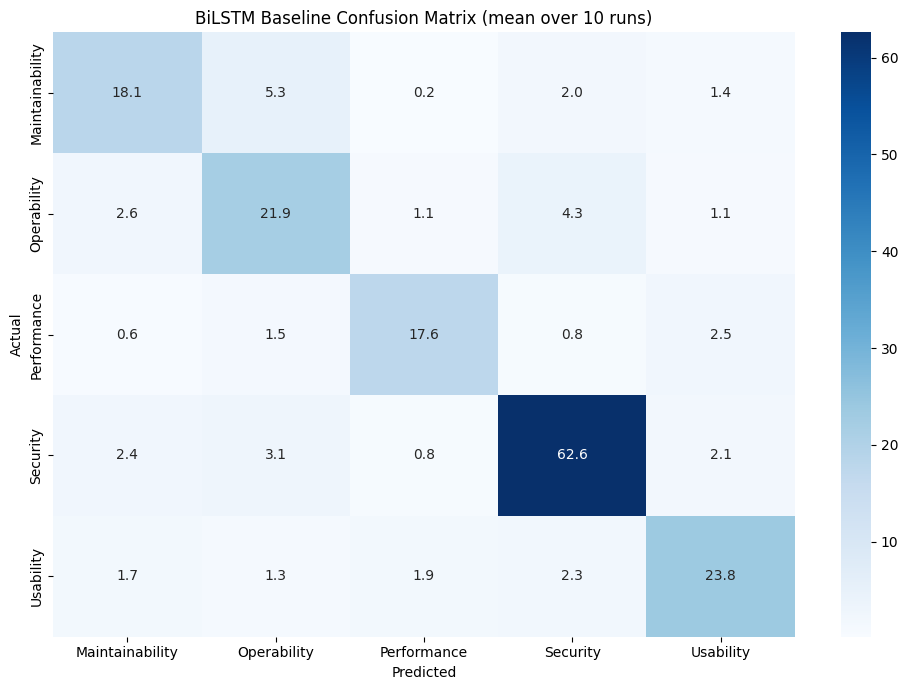

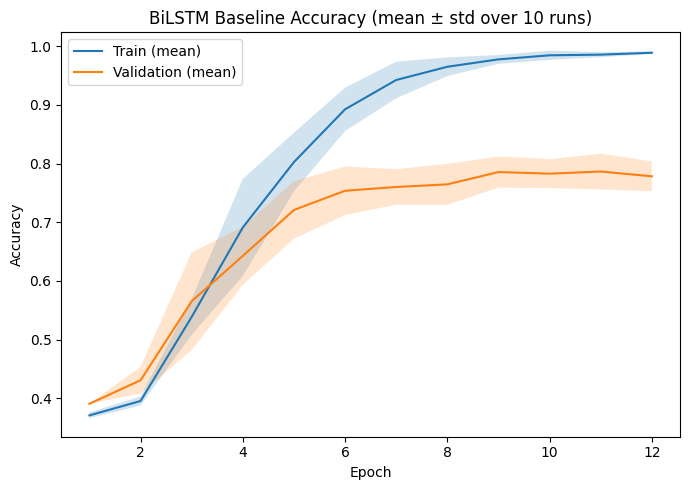

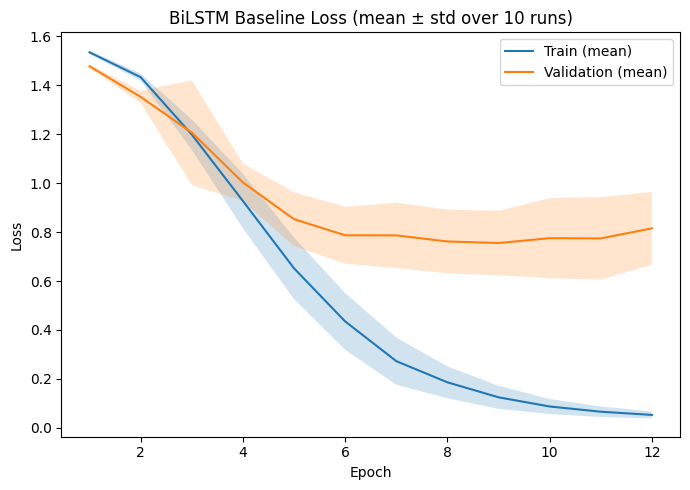


=== Top-20 words by avg positive LIME weight, aggregated over 10 runs ===
        word  avg_positive_lime_weight  avg_tfidf
     element                    0.7552     0.0034
     disease                    0.5901     0.0038
     viruses                    0.4038     0.0032
     pattern                    0.3928     0.0042
applications                    0.3558     0.0000
       https                    0.3151     0.0000
    discrete                    0.3053     0.0019
    security                    0.2866     0.0114
        1000                    0.2857     0.0000
    password                    0.2853     0.0157
   passwords                    0.2763     0.0000
    external                    0.2698     0.0041
    accesses                    0.2648     0.0000
   malicious                    0.2639     0.0061
        free                    0.2468     0.0032
      fields                    0.2363     0.0000
     queries                    0.2336     0.0000
   intuitive             

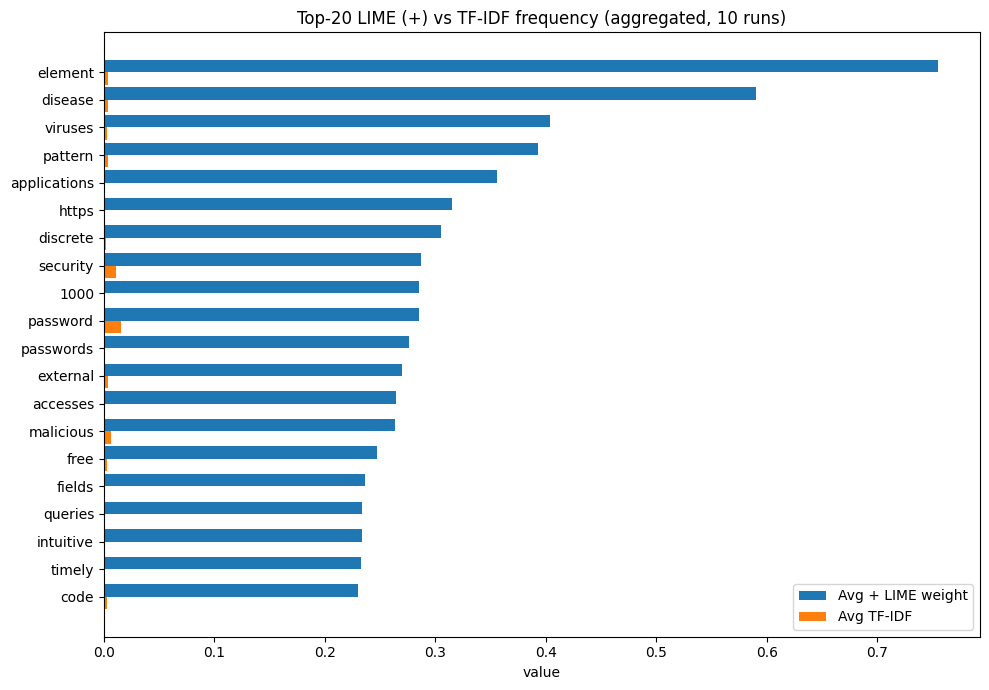

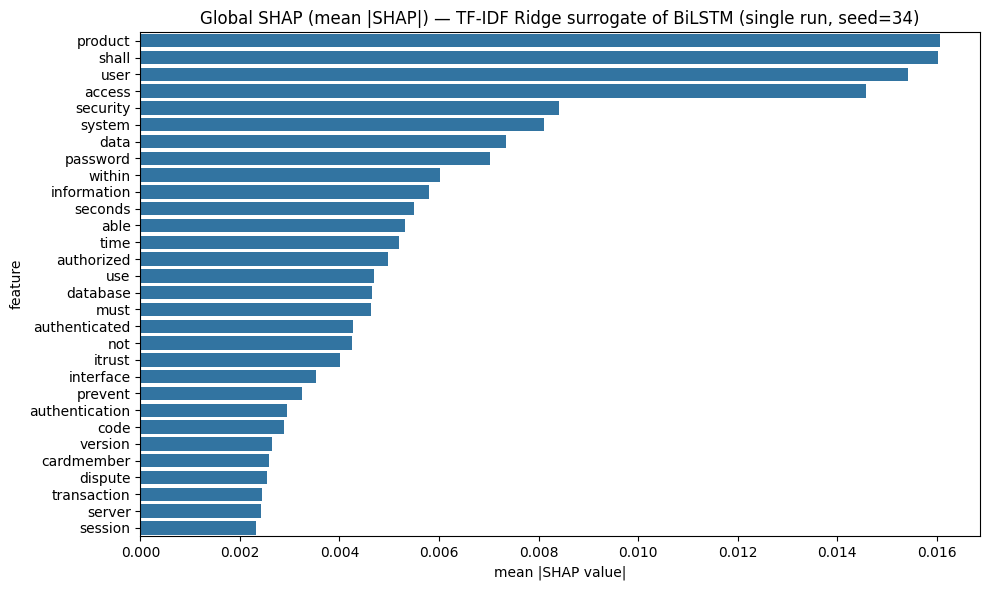


[INFO] All aggregate results, per-run CSVs, and figures saved to: /content/bilstm_baseline_multirun_results
[INFO] Files written:
   - accuracy_curve_mean.png
   - aggregate_metrics.csv
   - computational_cost.csv
   - confusion_matrix_mean.png
   - faithfulness_results.csv
   - lime_vs_tfidf_top20.csv
   - lime_vs_tfidf_top20.png
   - loss_curve_mean.png
   - per_class_metrics.csv
   - per_run_metrics.csv
   - shap_global_summary.png
   - summary.json

DONE: 10 runs completed.


In [ ]:
# Deps: pip install lime shap scikit-learn tensorflow matplotlib seaborn nltk pandas memory_profiler psutil

import os
import re
import json
import random
import time
import gc
import numpy as np
import pandas as pd
from memory_profiler import memory_usage

# -------- NLTK setup --------
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

# -------- ML / DL --------
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix
)
from sklearn.multioutput import MultiOutputRegressor
from sklearn.linear_model import Ridge

import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import (Input, Embedding, Bidirectional, LSTM,
                                     Dense, Dropout)
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# -------- Explainability --------
from lime.lime_text import LimeTextExplainer
import shap

# ============== Configuration ==============
CSV_PATH = "/content/NFR_five.csv"

# ---- Multi-run settings ----
N_RUNS = 10                       # how many times to repeat the whole pipeline (5-10 recommended)
BASE_SEED = 34                    # run i uses seed = BASE_SEED + i (different split + init each run)
OUTPUT_DIR = "/content/bilstm_baseline_multirun_results"
SHAP_RUN_EVERY_ITERATION = False  # False = run SHAP once (run 0 only) -> standard practice, much faster

TEST_SIZE = 0.20

# Tokenizer / Sequence params (for BiLSTM)
MAX_NUM_WORDS = 30000
MAX_LEN = 120
EMBED_DIM = 128
LSTM_UNITS = 64  # baseline: smaller units

# Classic TF-IDF space (for SHAP surrogate + comparison charts)
MAX_FEATURES_TFIDF = 5000

EPOCHS = 12
BATCH_SIZE = 32

INFERENCE_TIMING_REPEATS = 5   # repeat full-test-set inference this many times, average

# LIME / Faithfulness parameters
LIME_NUM_SAMPLES = 1000         # perturbations per instance
LIME_NUM_FEATURES = 10          # tokens highlighted per instance
LIME_SUBSET_SIZE = 100          # how many test rows to explain (cap)
FAITHFULNESS_TOPK = [3, 5, 10]  # deletion tests

# SHAP parameters (fast via LinearExplainer on the surrogate)
RUN_SHAP = True
SHAP_EVAL_SIZE = 100            # from test set

EXPECTED_CATEGORIES = [
    "Maintainability", "Operability", "Performance", "Security", "Usability"
]

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============== Cleaning / Preprocessing ==============
REPLACE_BY_SPACE = re.compile(r'[/(){}|@,;]')
STOPWORDS = set(stopwords.words("english"))

# Preserve negation
for w in ["not", "no", "nor"]:
    STOPWORDS.discard(w)

lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = REPLACE_BY_SPACE.sub(" ", text)
    text = re.sub(r"\s+", " ", text).strip()

    tokens = text.split()

    tokens = [
        lemmatizer.lemmatize(t)
        for t in tokens
        if t not in STOPWORDS
    ]

    return " ".join(tokens)

# ============== Load & filter data once (shared across all runs) ==============
df = pd.read_csv(CSV_PATH, encoding='latin1')
if 'sentence' not in df.columns or 'class_name' not in df.columns:
    raise ValueError("CSV must contain columns: 'sentence' and 'class_name'")

df['sentence'] = df['sentence'].fillna('')
df['class_name'] = df['class_name'].fillna('')
df = df[df['class_name'].isin(EXPECTED_CATEGORIES)].reset_index(drop=True)
if df.empty:
    raise ValueError("No rows left after filtering by EXPECTED_CATEGORIES. Check your CSV or categories.")

df['text_clean'] = df['sentence'].apply(clean_text)

Y_df = pd.get_dummies(df['class_name'], dtype=int)
Y_df = Y_df.reindex(columns=EXPECTED_CATEGORIES, fill_value=0)
Y_all = Y_df.values
y_idx_all = Y_all.argmax(axis=1)
sentences_all = df['sentence'].tolist()
text_clean_all = df['text_clean'].tolist()

# ============== Baseline BiLSTM Model (simple) ==============
def create_bilstm_baseline(vocab_size, embed_dim, max_len, num_classes):
    inp = Input(shape=(max_len,), name="tokens")
    x = Embedding(input_dim=vocab_size, output_dim=embed_dim, input_length=max_len, name="embed")(inp)
    # Single BiLSTM layer, no return_sequences (use last hidden state)
    x = Bidirectional(LSTM(LSTM_UNITS))(x)
    x = Dropout(0.4)(x)
    out = Dense(num_classes, activation="softmax")(x)
    model = Model(inp, out)
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

def remove_tokens(raw_text, tokens_to_remove):
    words = raw_text.split()
    rem = set([t.lower() for t in tokens_to_remove])
    kept = [w for w in words if w.lower() not in rem]
    return " ".join(kept)

_GPU_AVAILABLE = len(tf.config.list_physical_devices('GPU')) > 0

def _reset_gpu_peak():
    if _GPU_AVAILABLE:
        try:
            tf.config.experimental.reset_memory_stats('GPU:0')
        except Exception:
            pass

def _get_gpu_peak_mb():
    if _GPU_AVAILABLE:
        try:
            info = tf.config.experimental.get_memory_info('GPU:0')
            return info['peak'] / (1024 ** 2)
        except Exception:
            return None
    return None

# ============================================================
# ===================== SINGLE RUN ===========================
# ============================================================
def run_once(seed: int, run_idx: int, run_shap_this_run: bool):
    print(f"\n{'='*70}\nRUN {run_idx+1}/{N_RUNS}  (seed={seed})\n{'='*70}")

    random.seed(seed)
    np.random.seed(seed)
    tf.keras.utils.set_random_seed(seed)
    rng = np.random.default_rng(seed)          # <-- was missing, needed by rng.shuffle/rng.choice below

    # ---- Split indices first (avoids both TF-IDF and tokenizer leakage) ----
    train_idx_outer, test_idx = train_test_split(
        np.arange(len(text_clean_all)),
        test_size=TEST_SIZE,
        random_state=seed,
        stratify=y_idx_all
    )

    # ---- Split train partition further into train/validation ----
    y_train_outer_idx = y_idx_all[train_idx_outer]
    train_idx, val_idx = train_test_split(
        train_idx_outer,
        test_size=0.15,
        random_state=seed,
        stratify=y_train_outer_idx
    )

    train_texts_clean = [text_clean_all[i] for i in train_idx]
    val_texts_clean = [text_clean_all[i] for i in val_idx]
    test_texts_clean = [text_clean_all[i] for i in test_idx]
    test_texts = [sentences_all[i] for i in test_idx]   # raw text for LIME

    Y_train = Y_all[train_idx]
    Y_val = Y_all[val_idx]
    Y_test = Y_all[test_idx]
    y_train_idx = y_idx_all[train_idx]
    y_val_idx = y_idx_all[val_idx]
    y_test_idx = y_idx_all[test_idx]

    # ---- Tokenizer + Sequences (fit on TRAIN ONLY) ----
    tokenizer = Tokenizer(num_words=MAX_NUM_WORDS, oov_token="<OOV>")
    tokenizer.fit_on_texts(train_texts_clean)
    seqs_train = tokenizer.texts_to_sequences(train_texts_clean)
    seqs_val = tokenizer.texts_to_sequences(val_texts_clean)
    seqs_test = tokenizer.texts_to_sequences(test_texts_clean)
    X_seq_train = pad_sequences(seqs_train, maxlen=MAX_LEN, padding='post', truncating='post')
    X_seq_val = pad_sequences(seqs_val, maxlen=MAX_LEN, padding='post', truncating='post')
    X_seq_test = pad_sequences(seqs_test, maxlen=MAX_LEN, padding='post', truncating='post')

    # ---- TF-IDF fit on TRAIN ONLY (for SHAP surrogate + comparison) ----
    tfidf = TfidfVectorizer(max_features=MAX_FEATURES_TFIDF, min_df=1, smooth_idf=True, norm='l2')
    X_tfidf_train = tfidf.fit_transform(train_texts_clean).toarray()
    X_tfidf_test = tfidf.transform(test_texts_clean).toarray()

    vocab_size = min(MAX_NUM_WORDS, len(tokenizer.word_index) + 1)
    num_classes = Y_train.shape[1]
    model = create_bilstm_baseline(vocab_size, EMBED_DIM, MAX_LEN, num_classes)

    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6, verbose=0)
    early_stop = EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)

    trainable_params = int(np.sum([tf.keras.backend.count_params(w) for w in model.trainable_weights]))

    gc.collect()
    _reset_gpu_peak()

    def _fit_call():
        return model.fit(
            X_seq_train, Y_train,
            epochs=EPOCHS, batch_size=BATCH_SIZE,
            validation_data=(X_seq_val, Y_val),
            callbacks=[reduce_lr, early_stop], verbose=0
        )

    t0 = time.time()
    mem_during_train = memory_usage((_fit_call, (), {}), interval=0.2, max_usage=True, retval=True)
    train_time_sec = time.time() - t0
    peak_mem_train_mb, history = mem_during_train
    gpu_peak_train_mb = _get_gpu_peak_mb()

    # ---- classification metrics ----
    y_proba = model.predict(X_seq_test, verbose=0)  # warm-up call, excluded from timing

    gc.collect()
    _reset_gpu_peak()

    def _predict_call():
        return model.predict(X_seq_test, verbose=0)

    inf_times = []
    peak_mem_inf_mb = 0.0
    for _ in range(INFERENCE_TIMING_REPEATS):
        t0 = time.time()
        mem_usage_val, _ = memory_usage((_predict_call, (), {}), interval=0.2, max_usage=True, retval=True)
        inf_times.append(time.time() - t0)
        peak_mem_inf_mb = max(peak_mem_inf_mb, mem_usage_val)

    n_test_items = X_seq_test.shape[0]
    inference_time_per_item_sec = float(np.mean(inf_times)) / n_test_items
    gpu_peak_inf_mb = _get_gpu_peak_mb()

    peak_memory_mb = max(peak_mem_train_mb, peak_mem_inf_mb)
    gpu_peak_mb = None
    if gpu_peak_train_mb is not None or gpu_peak_inf_mb is not None:
        gpu_peak_mb = max(x for x in [gpu_peak_train_mb, gpu_peak_inf_mb] if x is not None)

    y_pred_idx = np.argmax(y_proba, axis=1)
    y_true_idx = y_test_idx

    cm = confusion_matrix(y_true_idx, y_pred_idx, labels=np.arange(len(EXPECTED_CATEGORIES)))
    acc = accuracy_score(y_true_idx, y_pred_idx)
    prec_macro = precision_score(y_true_idx, y_pred_idx, average='macro', zero_division=0)
    rec_macro = recall_score(y_true_idx, y_pred_idx, average='macro', zero_division=0)
    f1_macro = f1_score(y_true_idx, y_pred_idx, average='macro', zero_division=0)
    prec_weighted = precision_score(y_true_idx, y_pred_idx, average='weighted', zero_division=0)
    rec_weighted = recall_score(y_true_idx, y_pred_idx, average='weighted', zero_division=0)
    f1_weighted = f1_score(y_true_idx, y_pred_idx, average='weighted', zero_division=0)

    per_class_report = classification_report(
        y_true_idx, y_pred_idx, labels=np.arange(len(EXPECTED_CATEGORIES)),
        target_names=EXPECTED_CATEGORIES, digits=4, zero_division=0, output_dict=True
    )

    train_loss, train_acc = model.evaluate(X_seq_train, Y_train, verbose=0)
    test_loss, test_acc = model.evaluate(X_seq_test, Y_test, verbose=0)

    print(f"  Acc={acc:.4f}  F1(macro)={f1_macro:.4f}  F1(weighted)={f1_weighted:.4f}")

    # ---- LIME on test subset ----
    def _texts_to_seq(texts):
        cleaned = [clean_text(t) for t in texts]
        sq = tokenizer.texts_to_sequences(cleaned)
        return pad_sequences(sq, maxlen=MAX_LEN, padding='post', truncating='post')

    def predict_proba_texts(texts):
        X_ = _texts_to_seq(texts)
        return model.predict(X_, verbose=0)

    explainer = LimeTextExplainer(class_names=EXPECTED_CATEGORIES, bow=True)
    test_indices = np.arange(len(test_texts))
    rng.shuffle(test_indices)
    subset_idx = test_indices[:min(LIME_SUBSET_SIZE, len(test_texts))]
    subset_texts = [test_texts[i] for i in subset_idx]

    lime_fidelities, lime_sparsities = [], []
    lime_token_weights_per_word = {}
    faithfulness_results = {k: [] for k in FAITHFULNESS_TOPK}

    for t in subset_texts:
        proba = predict_proba_texts([t])[0]
        pred_label = int(np.argmax(proba))
        exp = explainer.explain_instance(
            t, predict_proba_texts,
            num_features=LIME_NUM_FEATURES, num_samples=LIME_NUM_SAMPLES,
            labels=[pred_label]
        )
        lime_fidelities.append(exp.score)
        items = exp.as_list(label=pred_label)
        lime_sparsities.append(len(items))
        for tok, w in items:
            if w > 0:
                lime_token_weights_per_word.setdefault(tok.lower(), []).append(w)

        top_tokens = [tok for tok, w in sorted(items, key=lambda x: -x[1]) if w > 0]
        p_full = proba
        for k in FAITHFULNESS_TOPK:
            picked = top_tokens[:min(k, len(top_tokens))]
            t_del = remove_tokens(t, picked)
            p_del = predict_proba_texts([t_del])[0]
            drop = p_full[pred_label] - p_del[pred_label]
            faithfulness_results[k].append(max(0.0, drop))

    lime_summary = {
        "fidelity_mean": float(np.mean(lime_fidelities)),
        "fidelity_std": float(np.std(lime_fidelities)),
        "sparsity_mean": float(np.mean(lime_sparsities)),
        "n_explained": len(subset_texts),
    }
    faithfulness_summary = {
        k: {"mean": float(np.mean(v)), "std": float(np.std(v))}
        for k, v in faithfulness_results.items()
    }

    print(f"  LIME fidelity={lime_summary['fidelity_mean']:.3f}±{lime_summary['fidelity_std']:.3f}  "
          f"Faithfulness@5={faithfulness_summary[5]['mean']:.4f}")

    # ---- SHAP via TF-IDF Ridge surrogate (optional, run 0 by default) ----
    shap_top_features = None
    surrogate_kl = None
    if RUN_SHAP and run_shap_this_run:
        try:
            print("  Fitting TF-IDF Ridge surrogate + computing SHAP...")
            y_soft_train = model.predict(X_seq_train, verbose=0)
            surrogate = MultiOutputRegressor(Ridge(alpha=1.0, random_state=seed))
            surrogate.fit(X_tfidf_train, y_soft_train)

            y_soft_test_bilstm = model.predict(X_seq_test, verbose=0)
            y_soft_test_surr = surrogate.predict(X_tfidf_test)
            eps = 1e-9
            surrogate_kl = float(np.mean(np.sum(
                (y_soft_test_bilstm + eps) * (np.log((y_soft_test_bilstm + eps) / (y_soft_test_surr + eps))),
                axis=1
            )))
            print(f"  [Surrogate vs BiLSTM] mean KL-like divergence on test: {surrogate_kl:.4f}")

            ev_idx = rng.choice(len(X_tfidf_test), size=min(SHAP_EVAL_SIZE, len(X_tfidf_test)), replace=False)
            X_ev = X_tfidf_test[ev_idx]

            vocab_items = sorted(tfidf.vocabulary_.items(), key=lambda kv: kv[1])
            feature_names = np.array([w for w, idx in vocab_items])
            C = Y_train.shape[1]

            mean_abs_list = []
            for k in range(C):
                estimator_k = surrogate.estimators_[k]
                explainer_k = shap.LinearExplainer(estimator_k, X_tfidf_train, feature_perturbation="interventional")
                sv_k = explainer_k.shap_values(X_ev)
                mean_abs_list.append(np.mean(np.abs(sv_k), axis=0))
            mean_abs_global = np.mean(np.stack(mean_abs_list, axis=0), axis=0)

            mag = np.asarray(mean_abs_global, dtype=float).reshape(-1)
            V2 = min(feature_names.shape[0], mag.shape[0])
            mag = mag[:V2]
            feature_names = feature_names[:V2]
            order = np.argsort(mag)[::-1][:min(30, V2)]
            shap_top_features = list(zip(feature_names[order].tolist(), mag[order].tolist()))
        except Exception as e:
            print(f"  [SHAP skipped] {e}")

    return {
        "seed": seed,
        "history": history.history,
        "confusion_matrix": cm,
        "metrics": {
            "accuracy": acc, "precision_macro": prec_macro, "recall_macro": rec_macro,
            "f1_macro": f1_macro, "precision_weighted": prec_weighted,
            "recall_weighted": rec_weighted, "f1_weighted": f1_weighted,
            "train_acc": float(train_acc), "test_acc": float(test_acc),
            "train_loss": float(train_loss), "test_loss": float(test_loss),
        },
        "per_class_report": per_class_report,
        "lime_summary": lime_summary,
        "faithfulness_summary": faithfulness_summary,
        "lime_token_weights": lime_token_weights_per_word,
        "shap_top_features": shap_top_features,
        "surrogate_kl": surrogate_kl,
        "tfidf_test_matrix": X_tfidf_test,
        "tfidf_vocab": dict(tfidf.vocabulary_),
        "computational_cost": {
            "trainable_params": trainable_params,
            "train_time_sec": float(train_time_sec),
            "inference_time_per_item_sec": float(inference_time_per_item_sec),
            "peak_memory_mb": float(peak_memory_mb),
            "gpu_peak_memory_mb": gpu_peak_mb,
        },
    }

# ============================================================
# ===================== DRIVER LOOP ===========================
# ============================================================
all_results = []
for i in range(N_RUNS):
    seed_i = BASE_SEED + i
    shap_this_run = (i == 0) if not SHAP_RUN_EVERY_ITERATION else True
    res = run_once(seed_i, i, run_shap_this_run=shap_this_run)
    all_results.append(res)

# ============================================================
# ================= AGGREGATION / REPORTING ===================
# ============================================================
def agg_mean_std(values):
    arr = np.array(values, dtype=float)
    return float(np.mean(arr)), float(np.std(arr))

metric_keys = list(all_results[0]["metrics"].keys())
agg_metrics = {}
for mk in metric_keys:
    vals = [r["metrics"][mk] for r in all_results]
    mean_v, std_v = agg_mean_std(vals)
    agg_metrics[mk] = {"mean": mean_v, "std": std_v, "values": vals}

print(f"\n{'='*70}\nAGGREGATE RESULTS OVER {N_RUNS} RUNS (seeds {BASE_SEED}..{BASE_SEED+N_RUNS-1})\n{'='*70}")
metrics_table = pd.DataFrame({
    "metric": metric_keys,
    "mean": [agg_metrics[m]["mean"] for m in metric_keys],
    "std": [agg_metrics[m]["std"] for m in metric_keys],
})
print(metrics_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

per_class_rows = []
for cat in EXPECTED_CATEGORIES:
    p_vals = [r["per_class_report"][cat]["precision"] for r in all_results]
    r_vals = [r["per_class_report"][cat]["recall"] for r in all_results]
    f_vals = [r["per_class_report"][cat]["f1-score"] for r in all_results]
    s_vals = [r["per_class_report"][cat]["support"] for r in all_results]
    p_m, p_s = agg_mean_std(p_vals)
    r_m, r_s = agg_mean_std(r_vals)
    f_m, f_s = agg_mean_std(f_vals)
    per_class_rows.append({
        "class": cat,
        "precision_mean": p_m, "precision_std": p_s,
        "recall_mean": r_m, "recall_std": r_s,
        "f1_mean": f_m, "f1_std": f_s,
        "support_mean": float(np.mean(s_vals)),
    })
per_class_df = pd.DataFrame(per_class_rows)
print("\n=== Per-class metrics (mean ± std across runs) ===")
print(per_class_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# ---- Computational cost aggregation ----
cost_keys = ["trainable_params", "train_time_sec", "inference_time_per_item_sec", "peak_memory_mb"]
cost_rows = []
for ck in cost_keys:
    vals = [r["computational_cost"][ck] for r in all_results]
    m, s = agg_mean_std(vals)
    cost_rows.append({"metric": ck, "mean": m, "std": s})

gpu_vals = [r["computational_cost"]["gpu_peak_memory_mb"] for r in all_results
            if r["computational_cost"]["gpu_peak_memory_mb"] is not None]
if gpu_vals:
    gm, gs = agg_mean_std(gpu_vals)
    cost_rows.append({"metric": "gpu_peak_memory_mb", "mean": gm, "std": gs})

cost_df = pd.DataFrame(cost_rows)
print(f"\n=== Computational cost (mean ± std over {N_RUNS} runs) ===")
print(cost_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
cost_df.to_csv(os.path.join(OUTPUT_DIR, "computational_cost.csv"), index=False)

lime_fid_vals = [r["lime_summary"]["fidelity_mean"] for r in all_results]
lime_sparsity_vals = [r["lime_summary"]["sparsity_mean"] for r in all_results]
fid_m, fid_s = agg_mean_std(lime_fid_vals)
spar_m, spar_s = agg_mean_std(lime_sparsity_vals)
print(f"\n=== LIME (aggregated over {N_RUNS} runs, {LIME_SUBSET_SIZE} instances/run) ===")
print(f"Fidelity:  {fid_m:.4f} ± {fid_s:.4f}")
print(f"Sparsity:  {spar_m:.4f} ± {spar_s:.4f}")

print(f"\n=== Faithfulness (Deletion Test), aggregated over {N_RUNS} runs ===")
faith_rows = []
for k in FAITHFULNESS_TOPK:
    vals = [r["faithfulness_summary"][k]["mean"] for r in all_results]
    m, s = agg_mean_std(vals)
    faith_rows.append({"top_k": k, "mean_prob_drop": m, "std_prob_drop": s})
    print(f"Top-{k} removal -> Avg prob drop: {m:.4f} ± {s:.4f}")
faith_df = pd.DataFrame(faith_rows)

kl_vals = [r["surrogate_kl"] for r in all_results if r["surrogate_kl"] is not None]
if kl_vals:
    kl_m, kl_s = agg_mean_std(kl_vals)
    print(f"\n=== TF-IDF Ridge Surrogate Fidelity (KL-like divergence vs BiLSTM) ===")
    print(f"Mean KL-like divergence: {kl_m:.4f} ± {kl_s:.4f}  (n={len(kl_vals)} run(s))")

# ---- averaged confusion matrix ----
cm_stack = np.stack([r["confusion_matrix"] for r in all_results], axis=0)
cm_mean = cm_stack.mean(axis=0)

plt.figure(figsize=(10,7))
sns.heatmap(cm_mean, annot=True, fmt='.1f', cmap='Blues',
            xticklabels=EXPECTED_CATEGORIES, yticklabels=EXPECTED_CATEGORIES)
plt.title(f'BiLSTM Baseline Confusion Matrix (mean over {N_RUNS} runs)')
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix_mean.png"), dpi=150)
plt.show()

# ---- averaged training curves ----
min_epochs = min(len(r["history"]["accuracy"]) for r in all_results)
train_acc_mat = np.stack([r["history"]["accuracy"][:min_epochs] for r in all_results])
val_acc_mat = np.stack([r["history"]["val_accuracy"][:min_epochs] for r in all_results])
train_loss_mat = np.stack([r["history"]["loss"][:min_epochs] for r in all_results])
val_loss_mat = np.stack([r["history"]["val_loss"][:min_epochs] for r in all_results])
epochs_axis = np.arange(1, min_epochs + 1)

plt.figure(figsize=(7,5))
plt.plot(epochs_axis, train_acc_mat.mean(axis=0), label='Train (mean)')
plt.fill_between(epochs_axis, train_acc_mat.mean(0)-train_acc_mat.std(0),
                  train_acc_mat.mean(0)+train_acc_mat.std(0), alpha=0.2)
plt.plot(epochs_axis, val_acc_mat.mean(axis=0), label='Validation (mean)')
plt.fill_between(epochs_axis, val_acc_mat.mean(0)-val_acc_mat.std(0),
                  val_acc_mat.mean(0)+val_acc_mat.std(0), alpha=0.2)
plt.title(f'BiLSTM Baseline Accuracy (mean ± std over {N_RUNS} runs)')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "accuracy_curve_mean.png"), dpi=150)
plt.show()

plt.figure(figsize=(7,5))
plt.plot(epochs_axis, train_loss_mat.mean(axis=0), label='Train (mean)')
plt.fill_between(epochs_axis, train_loss_mat.mean(0)-train_loss_mat.std(0),
                  train_loss_mat.mean(0)+train_loss_mat.std(0), alpha=0.2)
plt.plot(epochs_axis, val_loss_mat.mean(axis=0), label='Validation (mean)')
plt.fill_between(epochs_axis, val_loss_mat.mean(0)-val_loss_mat.std(0),
                  val_loss_mat.mean(0)+val_loss_mat.std(0), alpha=0.2)
plt.title(f'BiLSTM Baseline Loss (mean ± std over {N_RUNS} runs)')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "loss_curve_mean.png"), dpi=150)
plt.show()

# ---- LIME vs TF-IDF top-20 words, aggregated across all runs ----
combined_lime_weights = {}
for r in all_results:
    for w, ws in r["lime_token_weights"].items():
        combined_lime_weights.setdefault(w, []).extend(ws)
lime_avg_pos = {w: np.mean(ws) for w, ws in combined_lime_weights.items() if len(ws) > 0}

last_run = all_results[-1]
vocab_ref = last_run["tfidf_vocab"]
X_ref = last_run["tfidf_test_matrix"]

def avg_tfidf_for_word(w):
    idx = vocab_ref.get(w, None)
    if idx is None or idx >= X_ref.shape[1]:
        return 0.0
    return float(np.mean(X_ref[:, idx]))

pairs = [(w, avg_w, avg_tfidf_for_word(w)) for w, avg_w in lime_avg_pos.items()]
comp_df = pd.DataFrame(pairs, columns=["word", "avg_positive_lime_weight", "avg_tfidf"])
comp_top20 = comp_df.sort_values("avg_positive_lime_weight", ascending=False).head(20).reset_index(drop=True)

print(f"\n=== Top-20 words by avg positive LIME weight, aggregated over {N_RUNS} runs ===")
print(comp_top20.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

plt.figure(figsize=(10,7))
indices = np.arange(len(comp_top20))
barw = 0.45
plt.barh(indices + 0.0, comp_top20["avg_positive_lime_weight"].values, height=barw, label="Avg + LIME weight")
plt.barh(indices + barw, comp_top20["avg_tfidf"].values, height=barw, label="Avg TF-IDF")
plt.yticks(indices + barw/2, comp_top20["word"].values)
plt.gca().invert_yaxis()
plt.title(f"Top-20 LIME (+) vs TF-IDF frequency (aggregated, {N_RUNS} runs)")
plt.xlabel("value"); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "lime_vs_tfidf_top20.png"), dpi=150)
plt.show()

# ---- SHAP (from whichever run computed it) ----
shap_run = next((r for r in all_results if r["shap_top_features"] is not None), None)
if shap_run is not None:
    feats, vals = zip(*shap_run["shap_top_features"])
    plt.figure(figsize=(10,6))
    sns.barplot(x=list(vals), y=list(feats), orient='h')
    note = "single run" if not SHAP_RUN_EVERY_ITERATION else "averaged"
    plt.title(f"Global SHAP (mean |SHAP|) — TF-IDF Ridge surrogate of BiLSTM ({note}, seed={shap_run['seed']})")
    plt.xlabel("mean |SHAP value|"); plt.ylabel("feature")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "shap_global_summary.png"), dpi=150)
    plt.show()

# ============================================================
# ===================== SAVE ARTIFACTS =========================
# ============================================================
metrics_table.to_csv(os.path.join(OUTPUT_DIR, "aggregate_metrics.csv"), index=False)
per_class_df.to_csv(os.path.join(OUTPUT_DIR, "per_class_metrics.csv"), index=False)
faith_df.to_csv(os.path.join(OUTPUT_DIR, "faithfulness_results.csv"), index=False)
comp_top20.to_csv(os.path.join(OUTPUT_DIR, "lime_vs_tfidf_top20.csv"), index=False)

run_level_rows = []
for r in all_results:
    row = {"seed": r["seed"], **r["metrics"], **r["computational_cost"],
           "lime_fidelity": r["lime_summary"]["fidelity_mean"],
           "lime_sparsity": r["lime_summary"]["sparsity_mean"],
           "surrogate_kl": r["surrogate_kl"]}
    for k in FAITHFULNESS_TOPK:
        row[f"faithfulness_top{k}"] = r["faithfulness_summary"][k]["mean"]
    run_level_rows.append(row)
run_level_df = pd.DataFrame(run_level_rows)
run_level_df.to_csv(os.path.join(OUTPUT_DIR, "per_run_metrics.csv"), index=False)

summary_json = {
    "n_runs": N_RUNS,
    "seeds": [r["seed"] for r in all_results],
    "metrics_mean_std": {m: {"mean": agg_metrics[m]["mean"], "std": agg_metrics[m]["std"]} for m in metric_keys},
    "lime_fidelity_mean_std": {"mean": fid_m, "std": fid_s},
    "lime_sparsity_mean_std": {"mean": spar_m, "std": spar_s},
    "faithfulness_mean_std": {str(k): {"mean": float(np.mean([r["faithfulness_summary"][k]["mean"] for r in all_results])),
                                        "std": float(np.std([r["faithfulness_summary"][k]["mean"] for r in all_results]))}
                               for k in FAITHFULNESS_TOPK},
    "surrogate_kl_mean_std": {"mean": kl_m, "std": kl_s} if kl_vals else None,
}
with open(os.path.join(OUTPUT_DIR, "summary.json"), "w") as f:
    json.dump(summary_json, f, indent=2)

print(f"\n[INFO] All aggregate results, per-run CSVs, and figures saved to: {OUTPUT_DIR}")
print("[INFO] Files written:")
for fn in sorted(os.listdir(OUTPUT_DIR)):
    print(f"   - {fn}")

print(f"\n{'='*70}\nDONE: {N_RUNS} runs completed.\n{'='*70}")

# Baseline SVM/LogReg (multiseed)

In [ ]:
pip install scikit-learn nltk pandas

In [ ]:
# Deps: pip install scikit-learn nltk pandas memory_profiler psutil

import os
import re
import json
import random
import time
import gc
import numpy as np
import pandas as pd
from memory_profiler import memory_usage

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix
)

# ============== Configuration (mirrors the existing scripts exactly) ==============
CSV_PATH = "/content/NFR_five.csv"

N_RUNS = 10
BASE_SEED = 34
TEST_SIZE = 0.20
MAX_FEATURES_TFIDF = 5000
OUTPUT_DIR = "/content/svm_logreg_baseline_results"

INFERENCE_TIMING_REPEATS = 5   # repeat full-test-set inference this many times, average

EXPECTED_CATEGORIES = [
    "Maintainability", "Operability", "Performance", "Security", "Usability"
]

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============== Preprocessing (identical to the other scripts) ==============
REPLACE_BY_SPACE = re.compile(r'[/(){}|@,;]')
STOPWORDS = set(stopwords.words("english"))
for w in ["not", "no", "nor"]:
    STOPWORDS.discard(w)
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = REPLACE_BY_SPACE.sub(" ", text)
    text = re.sub(r"\s+", " ", text).strip()
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t not in STOPWORDS]
    return " ".join(tokens)

# ============== Load data once ==============
df = pd.read_csv(CSV_PATH, encoding='latin1')
if 'sentence' not in df.columns or 'class_name' not in df.columns:
    raise ValueError("CSV must contain columns: 'sentence' and 'class_name'")

df['sentence'] = df['sentence'].fillna('')
df['class_name'] = df['class_name'].fillna('')
df = df[df['class_name'].isin(EXPECTED_CATEGORIES)].reset_index(drop=True)
if df.empty:
    raise ValueError("No rows left after filtering by EXPECTED_CATEGORIES.")

df['text_clean'] = df['sentence'].apply(clean_text)

cat_to_idx = {c: i for i, c in enumerate(EXPECTED_CATEGORIES)}
y_idx_all = df['class_name'].map(cat_to_idx).values
text_clean_all = df['text_clean'].tolist()

# ============== Model builders ==============
def make_models(seed):
    """
    LinearSVC has no native predict_proba; wrap it so downstream code
    (and any future LIME/SHAP extension) has a consistent .predict_proba
    interface. Uses Platt-style calibration via CalibratedClassifierCV
    only if probabilities are ever needed -- omitted here since Table 5
    only needs point predictions (accuracy/precision/recall/F1).
    """
    svm = LinearSVC(C=1.0, class_weight=None, random_state=seed, max_iter=5000)
    logreg = LogisticRegression(
        C=1.0, class_weight=None, random_state=seed, max_iter=2000,
        multi_class="auto", solver="lbfgs"
    )
    return {"SVM_TFIDF": svm, "LogReg_TFIDF": logreg}

# ============================================================
# ===================== SINGLE RUN ===========================
# ============================================================
def run_once(seed: int, run_idx: int):
    print(f"\n{'='*70}\nRUN {run_idx+1}/{N_RUNS}  (seed={seed})\n{'='*70}")

    random.seed(seed)
    np.random.seed(seed)

    train_idx, test_idx = train_test_split(
        np.arange(len(text_clean_all)),
        test_size=TEST_SIZE,
        random_state=seed,
        stratify=y_idx_all
    )

    train_texts = [text_clean_all[i] for i in train_idx]
    test_texts = [text_clean_all[i] for i in test_idx]
    y_train = y_idx_all[train_idx]
    y_test = y_idx_all[test_idx]

    # TF-IDF fit on TRAIN ONLY -- identical convention to the other scripts
    tfidf = TfidfVectorizer(max_features=MAX_FEATURES_TFIDF, min_df=1, smooth_idf=True, norm='l2')
    X_train = tfidf.fit_transform(train_texts)
    X_test = tfidf.transform(test_texts)

    run_results = {}
    for model_name, model in make_models(seed).items():
        gc.collect()

        def _fit_call():
            model.fit(X_train, y_train)
            return model

        t0 = time.time()
        peak_mem_train_mb, model = memory_usage((_fit_call, (), {}), interval=0.2, max_usage=True, retval=True)
        train_time_sec = time.time() - t0

        trainable_params = int(model.coef_.size + model.intercept_.size)

        y_pred = model.predict(X_test)  # warm-up call, excluded from timing

        gc.collect()

        def _predict_call():
            return model.predict(X_test)

        inf_times = []
        peak_mem_inf_mb = 0.0
        for _ in range(INFERENCE_TIMING_REPEATS):
            t0 = time.time()
            mem_usage_val, _ = memory_usage((_predict_call, (), {}), interval=0.2, max_usage=True, retval=True)
            inf_times.append(time.time() - t0)
            peak_mem_inf_mb = max(peak_mem_inf_mb, mem_usage_val)

        n_test_items = X_test.shape[0]
        inference_time_per_item_sec = float(np.mean(inf_times)) / n_test_items
        peak_memory_mb = max(peak_mem_train_mb, peak_mem_inf_mb)

        acc = accuracy_score(y_test, y_pred)
        prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
        rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
        f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)
        prec_weighted = precision_score(y_test, y_pred, average='weighted', zero_division=0)
        rec_weighted = recall_score(y_test, y_pred, average='weighted', zero_division=0)
        f1_weighted = f1_score(y_test, y_pred, average='weighted', zero_division=0)

        per_class_report = classification_report(
            y_test, y_pred, labels=np.arange(len(EXPECTED_CATEGORIES)),
            target_names=EXPECTED_CATEGORIES, digits=4, zero_division=0, output_dict=True
        )
        cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(EXPECTED_CATEGORIES)))

        print(f"  [{model_name}] Acc={acc:.4f}  F1(macro)={f1_macro:.4f}")

        run_results[model_name] = {
            "seed": seed,
            "metrics": {
                "accuracy": acc, "precision_macro": prec_macro, "recall_macro": rec_macro,
                "f1_macro": f1_macro, "precision_weighted": prec_weighted,
                "recall_weighted": rec_weighted, "f1_weighted": f1_weighted,
            },
            "per_class_report": per_class_report,
            "confusion_matrix": cm,
            "computational_cost": {
                "trainable_params": trainable_params,
                "train_time_sec": float(train_time_sec),
                "inference_time_per_item_sec": float(inference_time_per_item_sec),
                "peak_memory_mb": float(peak_memory_mb),
            },
        }

    return run_results

# ============================================================
# ===================== DRIVER LOOP ===========================
# ============================================================
all_results = {name: [] for name in ["SVM_TFIDF", "LogReg_TFIDF"]}
for i in range(N_RUNS):
    seed_i = BASE_SEED + i
    res = run_once(seed_i, i)
    for name in all_results:
        all_results[name].append(res[name])

# ============================================================
# ================= AGGREGATION / REPORTING ===================
# ============================================================
def agg_mean_std(values):
    arr = np.array(values, dtype=float)
    return float(np.mean(arr)), float(np.std(arr))

for model_name, runs in all_results.items():
    print(f"\n{'='*70}\nAGGREGATE RESULTS: {model_name} OVER {N_RUNS} RUNS "
          f"(seeds {BASE_SEED}..{BASE_SEED+N_RUNS-1})\n{'='*70}")

    metric_keys = list(runs[0]["metrics"].keys())
    agg_metrics = {}
    for mk in metric_keys:
        vals = [r["metrics"][mk] for r in runs]
        mean_v, std_v = agg_mean_std(vals)
        agg_metrics[mk] = {"mean": mean_v, "std": std_v}

    metrics_table = pd.DataFrame({
        "metric": metric_keys,
        "mean": [agg_metrics[m]["mean"] for m in metric_keys],
        "std": [agg_metrics[m]["std"] for m in metric_keys],
    })
    print(metrics_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    metrics_table.to_csv(os.path.join(OUTPUT_DIR, f"aggregate_metrics_{model_name}.csv"), index=False)

    # per-class
    per_class_rows = []
    for cat in EXPECTED_CATEGORIES:
        p_vals = [r["per_class_report"][cat]["precision"] for r in runs]
        r_vals = [r["per_class_report"][cat]["recall"] for r in runs]
        f_vals = [r["per_class_report"][cat]["f1-score"] for r in runs]
        s_vals = [r["per_class_report"][cat]["support"] for r in runs]
        p_m, p_s = agg_mean_std(p_vals)
        r_m, r_s = agg_mean_std(r_vals)
        f_m, f_s = agg_mean_std(f_vals)
        per_class_rows.append({
            "class": cat, "precision_mean": p_m, "precision_std": p_s,
            "recall_mean": r_m, "recall_std": r_s, "f1_mean": f_m, "f1_std": f_s,
            "support_mean": float(np.mean(s_vals)),
        })
    per_class_df = pd.DataFrame(per_class_rows)
    per_class_df.to_csv(os.path.join(OUTPUT_DIR, f"per_class_metrics_{model_name}.csv"), index=False)

    # ---- Computational cost aggregation ----
    cost_keys = ["trainable_params", "train_time_sec", "inference_time_per_item_sec", "peak_memory_mb"]
    cost_rows = []
    for ck in cost_keys:
        vals = [r["computational_cost"][ck] for r in runs]
        m, s = agg_mean_std(vals)
        cost_rows.append({"metric": ck, "mean": m, "std": s})
    cost_df = pd.DataFrame(cost_rows)
    print(f"\n=== Computational cost for {model_name} (mean ± std over {N_RUNS} runs) ===")
    print(cost_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
    cost_df.to_csv(os.path.join(OUTPUT_DIR, f"computational_cost_{model_name}.csv"), index=False)

    # per-run (for paired stats against NFReqANN-Hybrid, same seeds)
    run_level_rows = [{"seed": r["seed"], **r["metrics"], **r["computational_cost"]} for r in runs]
    pd.DataFrame(run_level_rows).to_csv(
        os.path.join(OUTPUT_DIR, f"per_run_metrics_{model_name}.csv"), index=False
    )

print(f"\n[INFO] All results saved to: {OUTPUT_DIR}")
print("[INFO] Files written:")
for fn in sorted(os.listdir(OUTPUT_DIR)):
    print(f"   - {fn}")


RUN 1/10  (seed=34)
  [SVM_TFIDF] Acc=0.8361  F1(macro)=0.8180


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


  [LogReg_TFIDF] Acc=0.8033  F1(macro)=0.7814

RUN 2/10  (seed=35)
  [SVM_TFIDF] Acc=0.8197  F1(macro)=0.8014


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


  [LogReg_TFIDF] Acc=0.7760  F1(macro)=0.7521

RUN 3/10  (seed=36)
  [SVM_TFIDF] Acc=0.8087  F1(macro)=0.7992


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


... (11 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


  [LogReg_TFIDF] Acc=0.8306  F1(macro)=0.8179

RUN 10/10  (seed=43)
  [SVM_TFIDF] Acc=0.8197  F1(macro)=0.7894


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


  [LogReg_TFIDF] Acc=0.8087  F1(macro)=0.7818

AGGREGATE RESULTS: SVM_TFIDF OVER 10 RUNS (seeds 34..43)
            metric   mean    std
          accuracy 0.8399 0.0260
   precision_macro 0.8395 0.0273
      recall_macro 0.8157 0.0329
          f1_macro 0.8238 0.0307
precision_weighted 0.8425 0.0257
   recall_weighted 0.8399 0.0260
       f1_weighted 0.8378 0.0270

=== Computational cost for SVM_TFIDF (mean ± std over 10 runs) ===
                     metric      mean     std
           trainable_params 8961.5000 64.1112
             train_time_sec    0.4784  0.2141
inference_time_per_item_sec    0.0034  0.0007
             peak_memory_mb 2179.6309  0.0756

AGGREGATE RESULTS: LogReg_TFIDF OVER 10 RUNS (seeds 34..43)
            metric   mean    std
          accuracy 0.7956 0.0217
   precision_macro 0.8471 0.0204
      recall_macro 0.7386 0.0264
          f1_macro 0.7720 0.0255
precision_weighted 0.8182 0.0198
   recall_weighted 0.7956 0.0217
       f1_weighted 0.7868 0.0236

=== Comp

# **NFReqANN (TF-IDF) (multiseed)**

In [ ]:
pip install lime shap transformers torch accelerate memory_profiler psutil


RUN 1/10  (seed=34)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


  Acc=0.8306  F1(macro)=0.8011  F1(weighted)=0.8267
  LIME fidelity=0.683±0.264  Faithfulness@5=0.3954
  Running SHAP (KernelExplainer)...


  0%|          | 0/100 [00:00<?, ?it/s]


RUN 2/10  (seed=35)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


... (13 outputs left out)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


  Acc=0.8525  F1(macro)=0.8368  F1(weighted)=0.8510
  LIME fidelity=0.531±0.314  Faithfulness@5=0.4158

RUN 10/10  (seed=43)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


  Acc=0.8087  F1(macro)=0.7732  F1(weighted)=0.8023
  LIME fidelity=0.632±0.296  Faithfulness@5=0.3548

AGGREGATE RESULTS OVER 10 RUNS (seeds 34..43)
            metric   mean    std
          accuracy 0.8279 0.0259
   precision_macro 0.8290 0.0274
      recall_macro 0.7973 0.0340
          f1_macro 0.8071 0.0310
precision_weighted 0.8334 0.0240
   recall_weighted 0.8279 0.0259
       f1_weighted 0.8254 0.0260
         train_acc 0.9884 0.0068
          test_acc 0.8279 0.0259
        train_loss 0.0854 0.0958
         test_loss 0.6210 0.0980

=== Per-class metrics (mean ± std across runs) ===
          class  precision_mean  precision_std  recall_mean  recall_std  f1_mean  f1_std  support_mean
Maintainability          0.7840         0.0876       0.7222      0.0955   0.7448  0.0610       27.0000
    Operability          0.8009         0.0943       0.7290      0.0680   0.7557  0.0364       31.0000
    Performance          0.8841         0.0634       0.8174      0.1043   0.8445  0.0604     

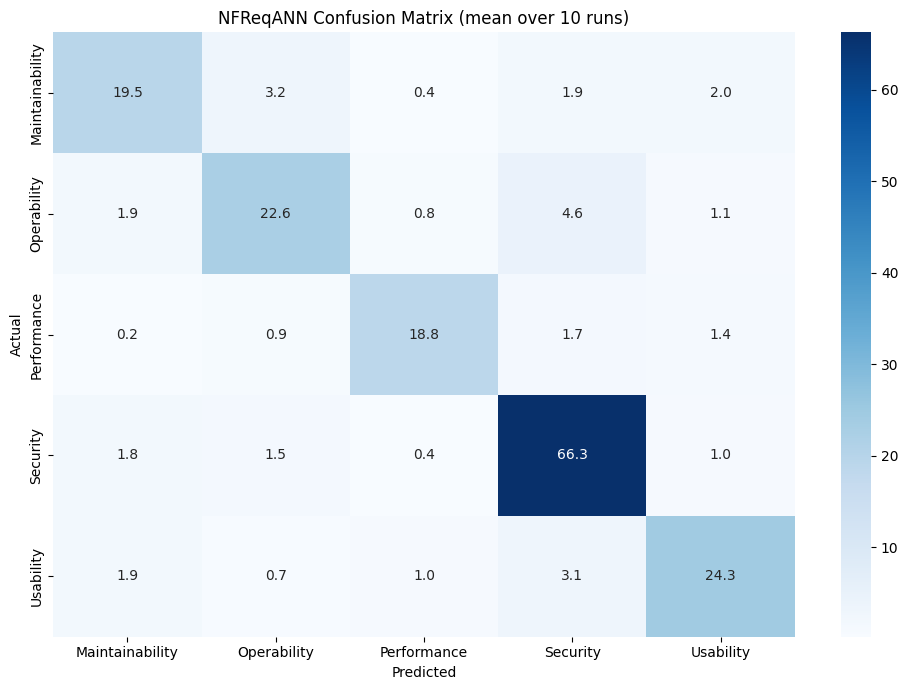

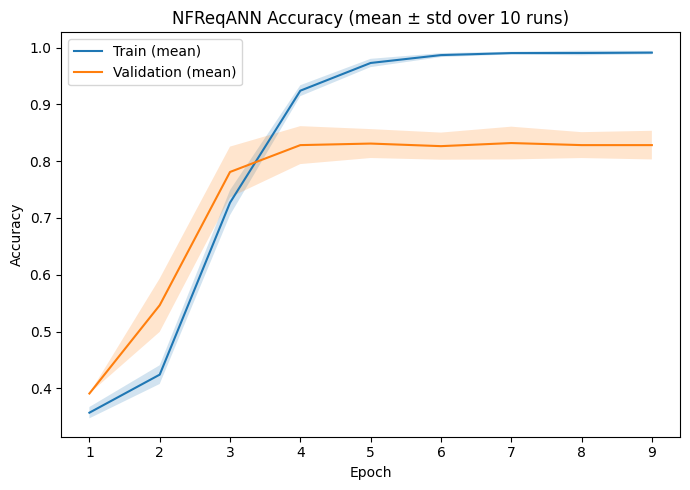

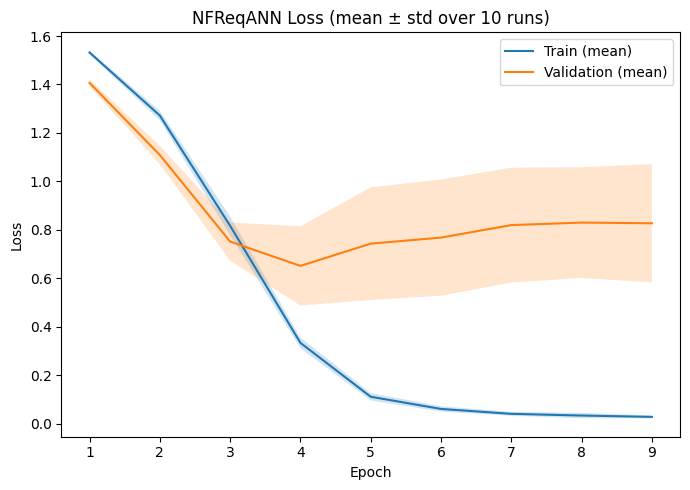


=== Top-20 words by avg positive LIME weight, aggregated over 10 runs ===
         word  avg_positive_lime_weight  avg_tfidf
        loinc                    0.4862     0.0016
         code                    0.4135     0.0061
        space                    0.4128     0.0007
         meet                    0.4051     0.0015
automatically                    0.4030     0.0012
      objects                    0.3881     0.0000
      disease                    0.3731     0.0013
       visual                    0.3607     0.0008
      viruses                    0.3571     0.0021
      element                    0.3416     0.0025
      letters                    0.3249     0.0000
          let                    0.3229     0.0034
 reservations                    0.3222     0.0000
      pattern                    0.3172     0.0013
      queries                    0.3154     0.0005
      actions                    0.2988     0.0009
   identified                    0.2865     0.0016
   capa

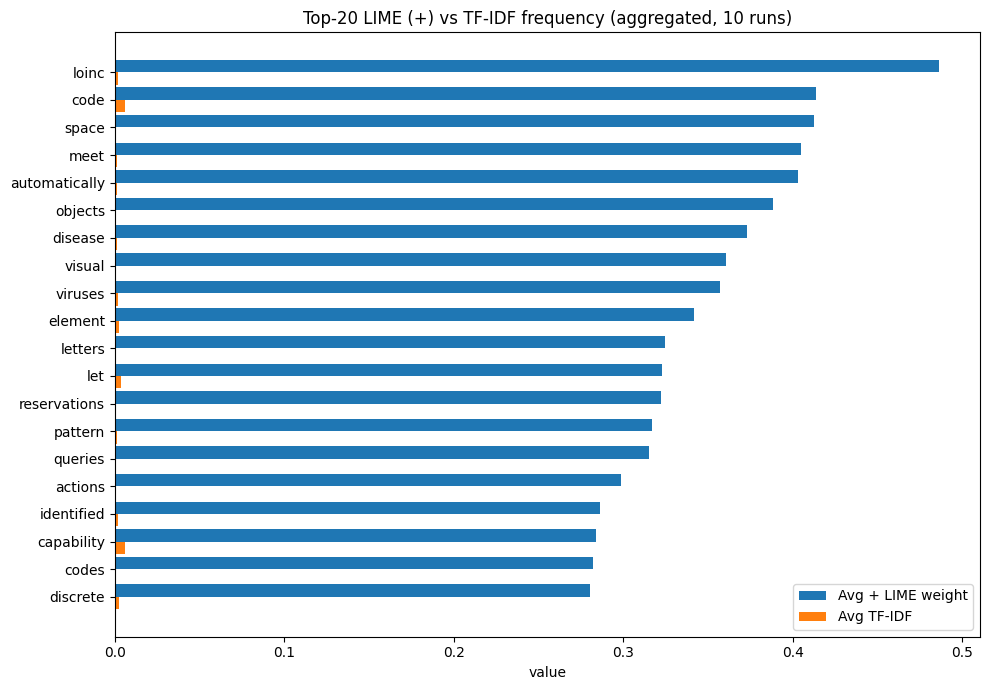

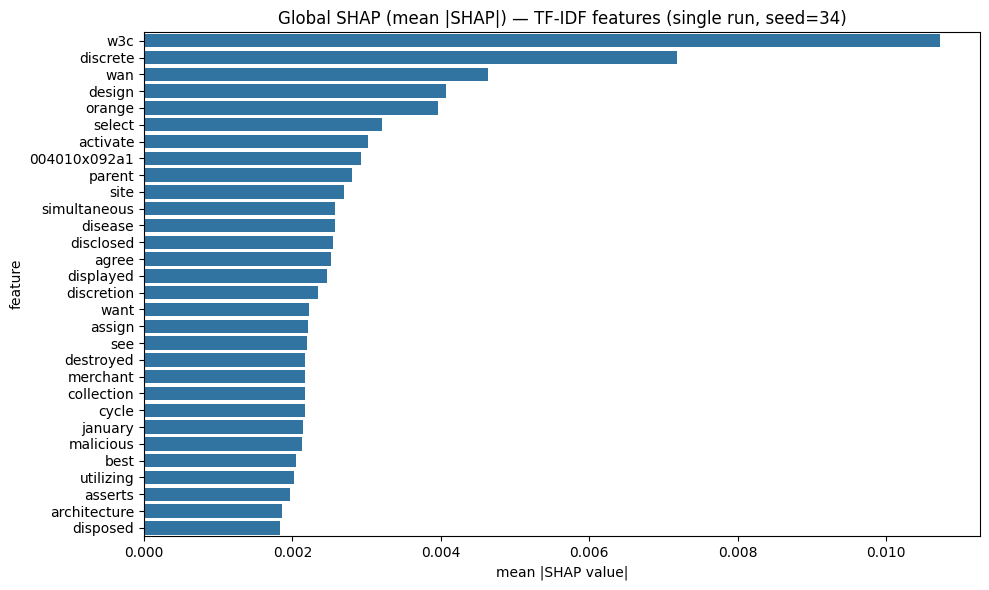


[INFO] All aggregate results, per-run CSVs, and figures saved to: /content/nfreqann_tfidf_multirun_results
[INFO] Files written:
   - accuracy_curve_mean.png
   - aggregate_metrics.csv
   - computational_cost.csv
   - confusion_matrix_mean.png
   - faithfulness_results.csv
   - lime_vs_tfidf_top20.csv
   - lime_vs_tfidf_top20.png
   - loss_curve_mean.png
   - per_class_metrics.csv
   - per_run_metrics.csv
   - shap_global_summary.png
   - summary.json

DONE: 10 runs completed.


In [ ]:
 # Deps: pip install lime shap transformers torch accelerate memory_profiler psutil

import os
import re
import json
import random
import time
import gc
import numpy as np
import pandas as pd
from memory_profiler import memory_usage

# -------- NLTK setup --------
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

# -------- ML / DL --------
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix
)
from sklearn.preprocessing import normalize
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

# -------- Explainability --------
from lime.lime_text import LimeTextExplainer
import shap

# -------- Transformers --------
try:
    import torch
    from transformers import AutoTokenizer, AutoModel
    _TRANSFORMERS_OK = True
except Exception as _e:
    _TRANSFORMERS_OK = False
    print("[INFO] transformers/torch not available yet. "
          "Install with: pip install transformers torch accelerate")

# ============== Configuration ==============
CSV_PATH = "/content/NFR_five.csv"

# ---- Multi-run settings ----
N_RUNS = 10                      # how many times to repeat the whole pipeline (5-10 recommended)
BASE_SEED = 34                   # run i uses seed = BASE_SEED + i  (different split + init each run)
OUTPUT_DIR = "/content/nfreqann_tfidf_multirun_results"
SHAP_RUN_EVERY_ITERATION = False  # False = run SHAP once (run 0 only) -> standard practice, much faster
                                   # True  = run SHAP every iteration -> rigorous but very slow

TEST_SIZE = 0.20
MAX_FEATURES = 5000
EPOCHS = 12
BATCH_SIZE = 32
INFERENCE_TIMING_REPEATS = 5   # repeat full-test-set inference this many times, average

# LIME / Faithfulness parameters
LIME_NUM_SAMPLES = 1000         # perturbations per instance
LIME_NUM_FEATURES = 10          # tokens highlighted per instance
LIME_SUBSET_SIZE = 100          # how many test rows to explain (cap)
FAITHFULNESS_TOPK = [3, 5, 10]  # deletion tests

# SHAP parameters (keep tiny for speed; raise gradually if needed)
RUN_SHAP = True
SHAP_BACKGROUND_SIZE = 50       # from train set
SHAP_EVAL_SIZE = 100            # from test set
SHAP_NSAMPLES = 200             # Kernel SHAP nsamples heuristic ~ O(features)

# Expected categories (order defines columns)
EXPECTED_CATEGORIES = [
    'Maintainability', 'Operability', 'Performance', 'Security', 'Usability'
]
# EXPECTED_CATEGORIES = [
#     'Maintainability', 'Operability', 'Performance', 'Security', 'Usability',
#     'functional', 'other nonfunctional', 'not applicable'
# ]

# ============== DistilBERT feature settings ==============
USE_DISTILBERT = False and _TRANSFORMERS_OK   # flip to False to go back to pure TF-IDF
FEAT_COMBINE = "tfidf"                      # "tfidf" | "bert_only" | "concat"
DISTILBERT_MODEL = "distilbert-base-uncased"
BERT_MAX_LEN = 192
BERT_BATCH_SIZE = 32
BERT_POOLING = "mean"                         # "cls" | "mean"
LIME_USE_BERT = False                        # speed guard: use const-bert during LIME

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============== Cleaning / Preprocessing ==============
REPLACE_BY_SPACE = re.compile(r'[/(){}|@,;]')
STOPWORDS = set(stopwords.words("english"))

# Preserve negation
for w in ["not", "no", "nor"]:
    STOPWORDS.discard(w)

lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = REPLACE_BY_SPACE.sub(" ", text)
    text = re.sub(r"\s+", " ", text).strip()

    tokens = text.split()

    tokens = [
        lemmatizer.lemmatize(t)
        for t in tokens
        if t not in STOPWORDS
    ]

    return " ".join(tokens)
# ============== Load data once (shared across all runs) ==============
df = pd.read_csv(CSV_PATH, encoding='latin1')

if 'sentence' not in df.columns or 'class_name' not in df.columns:
    raise ValueError("CSV must contain columns: 'sentence' and 'class_name'")

df['sentence'] = df['sentence'].fillna('')
df['class_name'] = df['class_name'].fillna('not applicable')
df['text_clean'] = df['sentence'].apply(clean_text)

unknown_mask = ~df['class_name'].isin(EXPECTED_CATEGORIES)
df.loc[unknown_mask, 'class_name'] = 'not applicable'

Y_df = pd.get_dummies(df['class_name'], dtype=int)
Y_df = Y_df.reindex(columns=EXPECTED_CATEGORIES, fill_value=0)
Y_all = Y_df.values
y_idx_all = Y_all.argmax(axis=1)
sentences_all = df['sentence'].tolist()
text_clean_all = df['text_clean'].tolist()

# ============== DistilBERT embedding helpers ==============
def _mean_pool(last_hidden_state, attention_mask):
    mask = attention_mask.unsqueeze(-1).expand(last_hidden_state.size()).float()
    masked = last_hidden_state * mask
    summed = torch.sum(masked, dim=1)
    counts = torch.clamp(mask.sum(dim=1), min=1e-9)
    return summed / counts

def _cls_pool(last_hidden_state):
    return last_hidden_state[:, 0, :]

_bert_tokenizer = None
_bert_model = None
_bert_device = None

def _get_bert():
    """Lazy-load DistilBERT once and reuse across all runs (weights don't change)."""
    global _bert_tokenizer, _bert_model, _bert_device
    if _bert_model is None:
        _bert_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        _bert_tokenizer = AutoTokenizer.from_pretrained(DISTILBERT_MODEL)
        _bert_model = AutoModel.from_pretrained(DISTILBERT_MODEL).to(_bert_device)
        _bert_model.eval()
    return _bert_tokenizer, _bert_model, _bert_device

def build_bert_embeddings(texts):
    tokenizer, model, device = _get_bert()
    outs = []
    with torch.no_grad():
        for i in range(0, len(texts), BERT_BATCH_SIZE):
            batch = texts[i:i+BERT_BATCH_SIZE]
            enc = tokenizer(
                batch, return_tensors="pt", padding=True, truncation=True,
                max_length=BERT_MAX_LEN
            ).to(device)
            out = model(**enc)
            if BERT_POOLING == "mean":
                pooled = _mean_pool(out.last_hidden_state, enc["attention_mask"])
            else:
                pooled = _cls_pool(out.last_hidden_state)
            outs.append(pooled.detach().cpu().numpy())
    return np.vstack(outs).astype(np.float32)

all_bert_embeddings = None
if USE_DISTILBERT:
    print("[INFO] Building DistilBERT sentence embeddings for the full dataset (once)...")
    all_bert_embeddings = build_bert_embeddings(sentences_all)
    all_bert_embeddings = normalize(all_bert_embeddings, norm='l2')
    bert_dim = all_bert_embeddings.shape[1]
    print(f"[INFO] DistilBERT dims: {bert_dim}")


# ============== Model builder ==============
def create_model(input_dim: int, num_classes: int) -> tf.keras.Model:
    model = Sequential([
        Dense(2048, activation="relu", input_dim=input_dim),
        Dropout(0.3),
        Dense(256, activation="relu"),
        Dropout(0.5),
        Dense(128, activation="relu"),
        Dropout(0.5),
        Dense(num_classes, activation="softmax"),
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

def remove_tokens(raw_text: str, tokens_to_remove: list) -> str:
    words = raw_text.split()
    rem = set([t.lower() for t in tokens_to_remove])
    kept = [w for w in words if w.lower() not in rem]
    return " ".join(kept)

    _GPU_AVAILABLE = len(tf.config.list_physical_devices('GPU')) > 0

def _reset_gpu_peak():
    if _GPU_AVAILABLE:
        try:
            tf.config.experimental.reset_memory_stats('GPU:0')
        except Exception:
            pass

def _get_gpu_peak_mb():
    if _GPU_AVAILABLE:
        try:
            info = tf.config.experimental.get_memory_info('GPU:0')
            return info['peak'] / (1024 ** 2)
        except Exception:
            return None
    return None


# ============================================================
# ===================== SINGLE RUN ===========================
# ============================================================
def run_once(seed: int, run_idx: int, run_shap_this_run: bool):
    """
    Executes the full pipeline (split -> TF-IDF -> model -> eval ->
    LIME -> faithfulness -> optional SHAP) for one random seed.
    Returns a dict of scalar/array results for later aggregation.
    """
    print(f"\n{'='*70}\nRUN {run_idx+1}/{N_RUNS}  (seed={seed})\n{'='*70}")

    random.seed(seed)
    np.random.seed(seed)

    tf.keras.utils.set_random_seed(seed)

    if _TRANSFORMERS_OK:
        torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # ---- split ----
    train_pos_outer, test_pos = train_test_split(
        np.arange(len(sentences_all)),
        test_size=TEST_SIZE,
        random_state=seed,
        stratify=y_idx_all
    )

    # ---- Split train partition further into train/validation ----
    y_train_outer_idx = y_idx_all[train_pos_outer]
    train_pos, val_pos = train_test_split(
        train_pos_outer,
        test_size=0.15,
        random_state=seed,
        stratify=y_train_outer_idx
    )

    train_texts = [text_clean_all[i] for i in train_pos]
    val_texts_clean = [text_clean_all[i] for i in val_pos]
    test_texts_clean = [text_clean_all[i] for i in test_pos]

    Y_train = Y_all[train_pos]
    Y_val = Y_all[val_pos]
    Y_test = Y_all[test_pos]

    y_train_idx = y_idx_all[train_pos]
    y_val_idx = y_idx_all[val_pos]
    y_test_idx = y_idx_all[test_pos]

    test_texts = [sentences_all[i] for i in test_pos]

    tfidf = TfidfVectorizer(
        max_features=MAX_FEATURES,
        min_df=1,
        smooth_idf=True,
        norm="l2"
    )

    X_train = tfidf.fit_transform(train_texts).toarray().astype(np.float32)
    X_val = tfidf.transform(val_texts_clean).toarray().astype(np.float32)
    X_test = tfidf.transform(test_texts_clean).toarray().astype(np.float32)

    Xb_train = Xb_val = Xb_test = None

    BERT_CONST = None
    if USE_DISTILBERT:
        Xb_train = all_bert_embeddings[train_pos]
        Xb_val = all_bert_embeddings[val_pos]
        Xb_test = all_bert_embeddings[test_pos]
        BERT_CONST = np.mean(Xb_train, axis=0, keepdims=True).astype(np.float32)
        BERT_CONST = normalize(BERT_CONST, norm='l2').astype(np.float32)


    X_train_model, X_val_model, X_test_model = X_train, X_val, X_test
    if USE_DISTILBERT:
        if FEAT_COMBINE == "bert_only":
            X_train_model, X_val_model, X_test_model = Xb_train, Xb_val, Xb_test
        elif FEAT_COMBINE == "concat":
            X_train_model = np.concatenate([X_train, Xb_train], axis=1).astype(np.float32)
            X_val_model = np.concatenate([X_val, Xb_val], axis=1).astype(np.float32)
            X_test_model = np.concatenate([X_test, Xb_test], axis=1).astype(np.float32)

    model = create_model(X_train_model.shape[1], num_classes=Y_train.shape[1])
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6, verbose=0)
    early_stop = EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)

    trainable_params = int(np.sum([tf.keras.backend.count_params(w) for w in model.trainable_weights]))

    gc.collect()
    _reset_gpu_peak()

    def _fit_call():
        return model.fit(
            X_train_model, Y_train,
            epochs=EPOCHS, batch_size=BATCH_SIZE,
            validation_data=(X_val_model, Y_val),
            callbacks=[reduce_lr, early_stop], verbose=0
        )

    t0 = time.time()
    mem_during_train = memory_usage(
        (_fit_call, (), {}),
        interval=0.2,
        max_usage=True,
        retval=True
    )
    train_time_sec = time.time() - t0
    peak_mem_train_mb, history = mem_during_train
    gpu_peak_train_mb = _get_gpu_peak_mb()


    # ---- classification metrics ----
    y_proba = model.predict(X_test_model, verbose=0)

    gc.collect()
    _reset_gpu_peak()

    def _predict_call():
        return model.predict(X_test_model, verbose=0)

    inf_times = []
    peak_mem_inf_mb = 0.0

    for _ in range(INFERENCE_TIMING_REPEATS):
        t0 = time.time()

        mem_usage_val, _ = memory_usage(
            (_predict_call, (), {}),
            interval=0.2,
            max_usage=True,
            retval=True
        )

        inf_times.append(time.time() - t0)
        peak_mem_inf_mb = max(peak_mem_inf_mb, mem_usage_val)

    n_test_items = X_test_model.shape[0]
    inference_time_per_item_sec = float(np.mean(inf_times)) / n_test_items
    gpu_peak_inf_mb = _get_gpu_peak_mb()

    peak_memory_mb = max(peak_mem_train_mb, peak_mem_inf_mb)

    gpu_peak_mb = None
    if gpu_peak_train_mb is not None or gpu_peak_inf_mb is not None:
        gpu_peak_mb = max(
            x for x in [gpu_peak_train_mb, gpu_peak_inf_mb]
            if x is not None
        )

    y_pred_idx = np.argmax(y_proba, axis=1)
    y_true_idx = y_test_idx

    cm = confusion_matrix(y_true_idx, y_pred_idx, labels=np.arange(len(EXPECTED_CATEGORIES)))
    acc = accuracy_score(y_true_idx, y_pred_idx)
    prec_macro = precision_score(y_true_idx, y_pred_idx, average='macro', zero_division=0)
    rec_macro = recall_score(y_true_idx, y_pred_idx, average='macro', zero_division=0)
    f1_macro = f1_score(y_true_idx, y_pred_idx, average='macro', zero_division=0)
    prec_weighted = precision_score(y_true_idx, y_pred_idx, average='weighted', zero_division=0)
    rec_weighted = recall_score(y_true_idx, y_pred_idx, average='weighted', zero_division=0)
    f1_weighted = f1_score(y_true_idx, y_pred_idx, average='weighted', zero_division=0)

    per_class_report = classification_report(
        y_true_idx, y_pred_idx, labels=np.arange(len(EXPECTED_CATEGORIES)),
        target_names=EXPECTED_CATEGORIES, digits=4, zero_division=0, output_dict=True
    )

    train_loss, train_acc = model.evaluate(X_train_model, Y_train, verbose=0)
    test_loss, test_acc = model.evaluate(X_test_model, Y_test, verbose=0)

    print(f"  Acc={acc:.4f}  F1(macro)={f1_macro:.4f}  F1(weighted)={f1_weighted:.4f}")

    # ---- feature builder for LIME / SHAP within this run's fitted tfidf/model ----
    def _build_features_for_texts(texts):
      cleaned = [clean_text(t) for t in texts]
      X_tfidf = tfidf.transform(cleaned).toarray().astype(np.float32)
      if USE_DISTILBERT:
          if LIME_USE_BERT or len(texts) <= 64:
              X_bert = build_bert_embeddings(texts).astype(np.float32)
              X_bert = normalize(X_bert, norm='l2').astype(np.float32)
          else:
              X_bert = np.repeat(BERT_CONST, repeats=len(texts), axis=0).astype(np.float32)
          if FEAT_COMBINE == "bert_only":
              return X_bert
          elif FEAT_COMBINE == "concat":
              return np.concatenate([X_tfidf, X_bert], axis=1).astype(np.float32)
          else:
              return X_tfidf
      else:
          return X_tfidf

    def predict_proba_texts(texts: list) -> np.ndarray:
        X_ = _build_features_for_texts(texts)
        return model.predict(X_, verbose=0)

    # ---- LIME on test subset ----
    explainer = LimeTextExplainer(class_names=EXPECTED_CATEGORIES, bow=True)
    test_indices = np.arange(len(test_texts))
    rng = np.random.default_rng(seed)
    rng.shuffle(test_indices)
    subset_idx = test_indices[:min(LIME_SUBSET_SIZE, len(test_texts))]
    subset_texts = [test_texts[i] for i in subset_idx]

    lime_fidelities, lime_sparsities, lime_highlight_counts = [], [], []
    lime_token_weights_per_word = {}
    faithfulness_results = {k: [] for k in FAITHFULNESS_TOPK}

    for t in subset_texts:
        proba = predict_proba_texts([t])[0]
        pred_label = int(np.argmax(proba))
        exp = explainer.explain_instance(
            t, predict_proba_texts,
            num_features=LIME_NUM_FEATURES, num_samples=LIME_NUM_SAMPLES,
            labels=[pred_label]
        )
        lime_fidelities.append(exp.score)
        items = exp.as_list(label=pred_label)
        lime_sparsities.append(len(items))
        lime_highlight_counts.append(len(items))
        for tok, w in items:
            if w > 0:
                lime_token_weights_per_word.setdefault(tok.lower(), []).append(w)

        # faithfulness deletion test reuses this same explanation
        top_tokens = [tok for tok, w in sorted(items, key=lambda x: -x[1]) if w > 0]
        p_full = proba
        for k in FAITHFULNESS_TOPK:
            picked = top_tokens[:min(k, len(top_tokens))]
            t_del = remove_tokens(t, picked)
            p_del = predict_proba_texts([t_del])[0]
            drop = p_full[pred_label] - p_del[pred_label]
            faithfulness_results[k].append(max(0.0, drop))

    lime_summary = {
        "fidelity_mean": float(np.mean(lime_fidelities)),
        "fidelity_std": float(np.std(lime_fidelities)),
        "sparsity_mean": float(np.mean(lime_sparsities)),
        "n_explained": len(subset_texts),
    }
    faithfulness_summary = {
        k: {"mean": float(np.mean(v)), "std": float(np.std(v))}
        for k, v in faithfulness_results.items()
    }

    print(f"  LIME fidelity={lime_summary['fidelity_mean']:.3f}±{lime_summary['fidelity_std']:.3f}  "
          f"Faithfulness@5={faithfulness_summary[5]['mean']:.4f}")

    # ---- SHAP (optional, expensive) ----
    shap_top_features = None
    if RUN_SHAP and run_shap_this_run:
        print("  Running SHAP (KernelExplainer)...")
        rng2 = np.random.default_rng(seed)
        bg_idx = rng2.choice(len(X_train), size=min(SHAP_BACKGROUND_SIZE, len(X_train)), replace=False)
        ev_idx = rng2.choice(len(X_test), size=min(SHAP_EVAL_SIZE, len(X_test)), replace=False)
        X_bg = X_train[bg_idx]
        X_ev = X_test[ev_idx]

        def predict_proba_dense(x):
            x = np.asarray(x, dtype=np.float32)
            if USE_DISTILBERT:
                if FEAT_COMBINE == "bert_only":
                    full_x = np.repeat(BERT_CONST, repeats=x.shape[0], axis=0).astype(np.float32)
                elif FEAT_COMBINE == "concat":
                    bert_part = np.repeat(BERT_CONST, repeats=x.shape[0], axis=0).astype(np.float32)
                    full_x = np.concatenate([x, bert_part], axis=1).astype(np.float32)
                else:
                    full_x = x
            else:
                full_x = x
            return model.predict(full_x, verbose=0)

        explainer_shap = shap.KernelExplainer(predict_proba_dense, X_bg, link="identity")
        shap_values = explainer_shap.shap_values(X_ev, nsamples=SHAP_NSAMPLES)

        if isinstance(shap_values, list):
            mean_abs_per_class = [np.mean(np.abs(sv), axis=0) for sv in shap_values]
            mean_abs_global = np.mean(np.stack(mean_abs_per_class, axis=0), axis=0)
        else:
            mean_abs_global = np.mean(np.abs(shap_values), axis=0)

        vocab_items = sorted(tfidf.vocabulary_.items(), key=lambda kv: kv[1])
        feature_names = np.array([w for w, idx in vocab_items])
        mag = np.asarray(mean_abs_global, dtype=float).reshape(-1)[:feature_names.shape[0]]
        order = np.argsort(mag)[::-1][:min(30, len(mag))]
        shap_top_features = list(zip(feature_names[order].tolist(), mag[order].tolist()))

    return {
        "seed": seed,
        "history": history.history,
        "confusion_matrix": cm,
        "metrics": {
            "accuracy": acc, "precision_macro": prec_macro, "recall_macro": rec_macro,
            "f1_macro": f1_macro, "precision_weighted": prec_weighted,
            "recall_weighted": rec_weighted, "f1_weighted": f1_weighted,
            "train_acc": float(train_acc), "test_acc": float(test_acc),
            "train_loss": float(train_loss), "test_loss": float(test_loss),
        },
        "per_class_report": per_class_report,
        "lime_summary": lime_summary,
        "faithfulness_summary": faithfulness_summary,
        "lime_token_weights": lime_token_weights_per_word,
        "shap_top_features": shap_top_features,
        "tfidf_test_matrix": X_test if shap_top_features is not None else None,
        "tfidf_vocab": dict(tfidf.vocabulary_) if shap_top_features is not None else None,
        "computational_cost": {
            "trainable_params": trainable_params,
            "train_time_sec": float(train_time_sec),
            "inference_time_per_item_sec": float(inference_time_per_item_sec),
            "peak_memory_mb": float(peak_memory_mb),
            "gpu_peak_memory_mb": gpu_peak_mb,
        },
    }

# ============================================================
# ===================== DRIVER LOOP ===========================
# ============================================================
all_results = []
for i in range(N_RUNS):
    seed_i = BASE_SEED + i
    shap_this_run = (i == 0) if not SHAP_RUN_EVERY_ITERATION else True
    res = run_once(seed_i, i, run_shap_this_run=shap_this_run)
    all_results.append(res)

# ============================================================
# ================= AGGREGATION / REPORTING ===================
# ============================================================
def agg_mean_std(values):
    arr = np.array(values, dtype=float)
    return float(np.mean(arr)), float(np.std(arr))

metric_keys = list(all_results[0]["metrics"].keys())
agg_metrics = {}
for mk in metric_keys:
    vals = [r["metrics"][mk] for r in all_results]
    mean_v, std_v = agg_mean_std(vals)
    agg_metrics[mk] = {"mean": mean_v, "std": std_v, "values": vals}

print(f"\n{'='*70}\nAGGREGATE RESULTS OVER {N_RUNS} RUNS (seeds {BASE_SEED}..{BASE_SEED+N_RUNS-1})\n{'='*70}")
metrics_table = pd.DataFrame({
    "metric": metric_keys,
    "mean": [agg_metrics[m]["mean"] for m in metric_keys],
    "std": [agg_metrics[m]["std"] for m in metric_keys],
})
print(metrics_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# ---- per-class metrics aggregation (precision/recall/f1 per category) ----
per_class_rows = []
for cat in EXPECTED_CATEGORIES:
    p_vals = [r["per_class_report"][cat]["precision"] for r in all_results]
    r_vals = [r["per_class_report"][cat]["recall"] for r in all_results]
    f_vals = [r["per_class_report"][cat]["f1-score"] for r in all_results]
    s_vals = [r["per_class_report"][cat]["support"] for r in all_results]
    p_m, p_s = agg_mean_std(p_vals)
    r_m, r_s = agg_mean_std(r_vals)
    f_m, f_s = agg_mean_std(f_vals)
    per_class_rows.append({
        "class": cat,
        "precision_mean": p_m, "precision_std": p_s,
        "recall_mean": r_m, "recall_std": r_s,
        "f1_mean": f_m, "f1_std": f_s,
        "support_mean": float(np.mean(s_vals)),
    })
per_class_df = pd.DataFrame(per_class_rows)
print("\n=== Per-class metrics (mean ± std across runs) ===")
print(per_class_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# ---- Computational cost aggregation ----
cost_keys = [
    "trainable_params",
    "train_time_sec",
    "inference_time_per_item_sec",
    "peak_memory_mb"
]

cost_rows = []

for ck in cost_keys:
    vals = [r["computational_cost"][ck] for r in all_results]
    m, s = agg_mean_std(vals)
    cost_rows.append({
        "metric": ck,
        "mean": m,
        "std": s
    })

gpu_vals = [
    r["computational_cost"]["gpu_peak_memory_mb"]
    for r in all_results
    if r["computational_cost"]["gpu_peak_memory_mb"] is not None
]

if gpu_vals:
    gm, gs = agg_mean_std(gpu_vals)
    cost_rows.append({
        "metric": "gpu_peak_memory_mb",
        "mean": gm,
        "std": gs
    })

cost_df = pd.DataFrame(cost_rows)

print(f"\n=== Computational cost (mean ± std over {N_RUNS} runs) ===")
print(
    cost_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

cost_df.to_csv(
    os.path.join(OUTPUT_DIR, "computational_cost.csv"),
    index=False
)


# ---- LIME aggregation ----
lime_fid_vals = [r["lime_summary"]["fidelity_mean"] for r in all_results]
lime_sparsity_vals = [r["lime_summary"]["sparsity_mean"] for r in all_results]
fid_m, fid_s = agg_mean_std(lime_fid_vals)
spar_m, spar_s = agg_mean_std(lime_sparsity_vals)
print(f"\n=== LIME (aggregated over {N_RUNS} runs, {LIME_SUBSET_SIZE} instances/run) ===")
print(f"Fidelity:  {fid_m:.4f} ± {fid_s:.4f}")
print(f"Sparsity:  {spar_m:.4f} ± {spar_s:.4f}")

# ---- Faithfulness aggregation ----
print(f"\n=== Faithfulness (Deletion Test), aggregated over {N_RUNS} runs ===")
faith_rows = []
for k in FAITHFULNESS_TOPK:
    vals = [r["faithfulness_summary"][k]["mean"] for r in all_results]
    m, s = agg_mean_std(vals)
    faith_rows.append({"top_k": k, "mean_prob_drop": m, "std_prob_drop": s})
    print(f"Top-{k} removal -> Avg prob drop: {m:.4f} ± {s:.4f}")
faith_df = pd.DataFrame(faith_rows)

# ---- averaged confusion matrix ----
cm_stack = np.stack([r["confusion_matrix"] for r in all_results], axis=0)
cm_mean = cm_stack.mean(axis=0)
cm_std = cm_stack.std(axis=0)

plt.figure(figsize=(10,7))
sns.heatmap(cm_mean, annot=True, fmt='.1f', cmap='Blues',
            xticklabels=EXPECTED_CATEGORIES, yticklabels=EXPECTED_CATEGORIES)
plt.title(f'NFReqANN Confusion Matrix (mean over {N_RUNS} runs)')
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix_mean.png"), dpi=150)
plt.show()

# ---- averaged training curves (pad/truncate to shortest run length due to early stopping) ----
min_epochs = min(len(r["history"]["accuracy"]) for r in all_results)
train_acc_mat = np.stack([r["history"]["accuracy"][:min_epochs] for r in all_results])
val_acc_mat = np.stack([r["history"]["val_accuracy"][:min_epochs] for r in all_results])
train_loss_mat = np.stack([r["history"]["loss"][:min_epochs] for r in all_results])
val_loss_mat = np.stack([r["history"]["val_loss"][:min_epochs] for r in all_results])

epochs_axis = np.arange(1, min_epochs + 1)

plt.figure(figsize=(7,5))
plt.plot(epochs_axis, train_acc_mat.mean(axis=0), label='Train (mean)')
plt.fill_between(epochs_axis, train_acc_mat.mean(0)-train_acc_mat.std(0),
                  train_acc_mat.mean(0)+train_acc_mat.std(0), alpha=0.2)
plt.plot(epochs_axis, val_acc_mat.mean(axis=0), label='Validation (mean)')
plt.fill_between(epochs_axis, val_acc_mat.mean(0)-val_acc_mat.std(0),
                  val_acc_mat.mean(0)+val_acc_mat.std(0), alpha=0.2)
plt.title(f'NFReqANN Accuracy (mean ± std over {N_RUNS} runs)')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "accuracy_curve_mean.png"), dpi=150)
plt.show()

plt.figure(figsize=(7,5))
plt.plot(epochs_axis, train_loss_mat.mean(axis=0), label='Train (mean)')
plt.fill_between(epochs_axis, train_loss_mat.mean(0)-train_loss_mat.std(0),
                  train_loss_mat.mean(0)+train_loss_mat.std(0), alpha=0.2)
plt.plot(epochs_axis, val_loss_mat.mean(axis=0), label='Validation (mean)')
plt.fill_between(epochs_axis, val_loss_mat.mean(0)-val_loss_mat.std(0),
                  val_loss_mat.mean(0)+val_loss_mat.std(0), alpha=0.2)
plt.title(f'NFReqANN Loss (mean ± std over {N_RUNS} runs)')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "loss_curve_mean.png"), dpi=150)
plt.show()

# ---- LIME vs TF-IDF top-20 words, aggregated across all runs ----
combined_lime_weights = {}
for r in all_results:
    for w, ws in r["lime_token_weights"].items():
        combined_lime_weights.setdefault(w, []).extend(ws)

lime_avg_pos = {w: np.mean(ws) for w, ws in combined_lime_weights.items() if len(ws) > 0}

last_run = all_results[-1]
last_tfidf_path_vocab = None
tfidf_ref = TfidfVectorizer(max_features=MAX_FEATURES, min_df=1, smooth_idf=True, norm='l2')
X_ref_sparse = tfidf_ref.fit_transform(text_clean_all)
X_ref = X_ref_sparse.toarray().astype(np.float32)
vocab_ref = tfidf_ref.vocabulary_

def avg_tfidf_for_word(w):
    idx = vocab_ref.get(w, None)
    if idx is None:
        return 0.0
    return float(np.mean(X_ref[:, idx]))

pairs = [(w, avg_w, avg_tfidf_for_word(w)) for w, avg_w in lime_avg_pos.items()]
comp_df = pd.DataFrame(pairs, columns=["word", "avg_positive_lime_weight", "avg_tfidf"])
comp_top20 = comp_df.sort_values("avg_positive_lime_weight", ascending=False).head(20).reset_index(drop=True)

print(f"\n=== Top-20 words by avg positive LIME weight, aggregated over {N_RUNS} runs ===")
print(comp_top20.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

plt.figure(figsize=(10,7))
indices = np.arange(len(comp_top20))
barw = 0.45
plt.barh(indices + 0.0, comp_top20["avg_positive_lime_weight"].values, height=barw, label="Avg + LIME weight")
plt.barh(indices + barw, comp_top20["avg_tfidf"].values, height=barw, label="Avg TF-IDF")
plt.yticks(indices + barw/2, comp_top20["word"].values)
plt.gca().invert_yaxis()
plt.title(f"Top-20 LIME (+) vs TF-IDF frequency (aggregated, {N_RUNS} runs)")
plt.xlabel("value"); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "lime_vs_tfidf_top20.png"), dpi=150)
plt.show()

# ---- SHAP (from whichever run computed it) ----
shap_run = next((r for r in all_results if r["shap_top_features"] is not None), None)
if shap_run is not None:
    feats, vals = zip(*shap_run["shap_top_features"])
    plt.figure(figsize=(10,6))
    sns.barplot(x=list(vals), y=list(feats), orient='h')
    note = "single run" if not SHAP_RUN_EVERY_ITERATION else "averaged"
    plt.title(f"Global SHAP (mean |SHAP|) — TF-IDF features ({note}, seed={shap_run['seed']})")
    plt.xlabel("mean |SHAP value|"); plt.ylabel("feature")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "shap_global_summary.png"), dpi=150)
    plt.show()

# ============================================================
# ===================== SAVE ARTIFACTS =========================
# ============================================================
metrics_table.to_csv(os.path.join(OUTPUT_DIR, "aggregate_metrics.csv"), index=False)
per_class_df.to_csv(os.path.join(OUTPUT_DIR, "per_class_metrics.csv"), index=False)
faith_df.to_csv(os.path.join(OUTPUT_DIR, "faithfulness_results.csv"), index=False)
comp_top20.to_csv(os.path.join(OUTPUT_DIR, "lime_vs_tfidf_top20.csv"), index=False)

run_level_rows = []
for r in all_results:
    row = {
        "seed": r["seed"],
        **r["metrics"],
        **r["computational_cost"],
        "lime_fidelity": r["lime_summary"]["fidelity_mean"],
        "lime_sparsity": r["lime_summary"]["sparsity_mean"]
    }

    for k in FAITHFULNESS_TOPK:
        row[f"faithfulness_top{k}"] = r["faithfulness_summary"][k]["mean"]

    run_level_rows.append(row)

    for k in FAITHFULNESS_TOPK:
        row[f"faithfulness_top{k}"] = r["faithfulness_summary"][k]["mean"]
    run_level_rows.append(row)
run_level_df = pd.DataFrame(run_level_rows)
run_level_df.to_csv(os.path.join(OUTPUT_DIR, "per_run_metrics.csv"), index=False)

summary_json = {
    "n_runs": N_RUNS,
    "seeds": [r["seed"] for r in all_results],
    "metrics_mean_std": {m: {"mean": agg_metrics[m]["mean"], "std": agg_metrics[m]["std"]} for m in metric_keys},
    "lime_fidelity_mean_std": {"mean": fid_m, "std": fid_s},
    "lime_sparsity_mean_std": {"mean": spar_m, "std": spar_s},
    "faithfulness_mean_std": {str(k): {"mean": float(np.mean([r["faithfulness_summary"][k]["mean"] for r in all_results])),
                                        "std": float(np.std([r["faithfulness_summary"][k]["mean"] for r in all_results]))}
                               for k in FAITHFULNESS_TOPK},
}
with open(os.path.join(OUTPUT_DIR, "summary.json"), "w") as f:
    json.dump(summary_json, f, indent=2)

print(f"\n[INFO] All aggregate results, per-run CSVs, and figures saved to: {OUTPUT_DIR}")
print("[INFO] Files written:")
for fn in sorted(os.listdir(OUTPUT_DIR)):
    print(f"   - {fn}")

print(f"\n{'='*70}\nDONE: {N_RUNS} runs completed.\n{'='*70}")

# **NFReqANN (BERT) (multiseed)**

In [ ]:
pip install lime shap transformers torch accelerate memory_profiler psutil

[INFO] Building DistilBERT sentence embeddings for the full dataset (once)...


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

... (22 outputs left out)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


  Acc=0.8634  F1(macro)=0.8344  F1(weighted)=0.8638
  LIME fidelity=0.346±0.470  Faithfulness@5=0.0723

RUN 10/10  (seed=43)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


  Acc=0.7923  F1(macro)=0.7712  F1(weighted)=0.7967
  LIME fidelity=0.288±0.444  Faithfulness@5=0.0899

AGGREGATE RESULTS OVER 10 RUNS (seeds 34..43)
            metric   mean    std
          accuracy 0.8186 0.0389
   precision_macro 0.8051 0.0363
      recall_macro 0.7911 0.0422
          f1_macro 0.7912 0.0401
precision_weighted 0.8264 0.0365
   recall_weighted 0.8186 0.0389
       f1_weighted 0.8169 0.0391
         train_acc 0.9052 0.0233
          test_acc 0.8186 0.0389
        train_loss 0.3026 0.0597
         test_loss 0.5570 0.0993

=== Per-class metrics (mean ± std across runs) ===
          class  precision_mean  precision_std  recall_mean  recall_std  f1_mean  f1_std  support_mean
Maintainability          0.7618         0.0906       0.6667      0.0663   0.7068  0.0561       27.0000
    Operability          0.7623         0.1061       0.7258      0.1201   0.7328  0.0836       31.0000
    Performance          0.8068         0.0682       0.8043      0.1218   0.7960  0.0528     

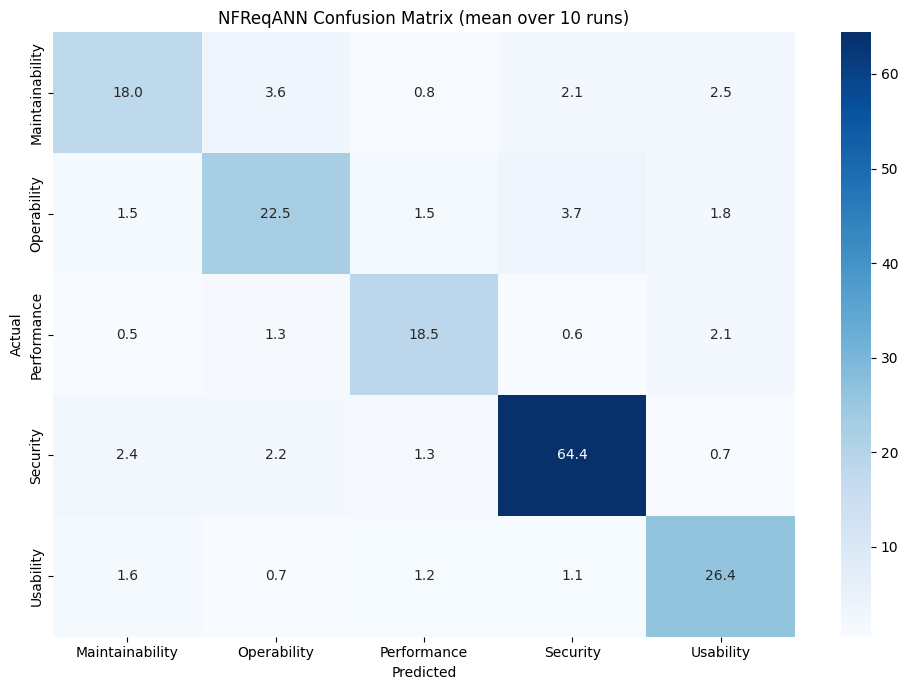

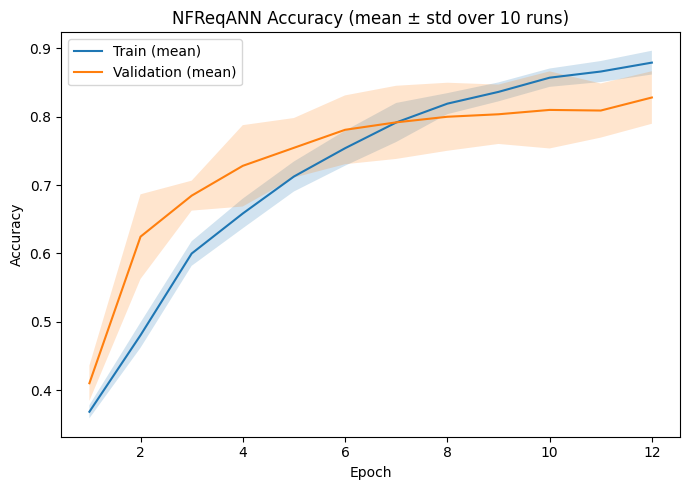

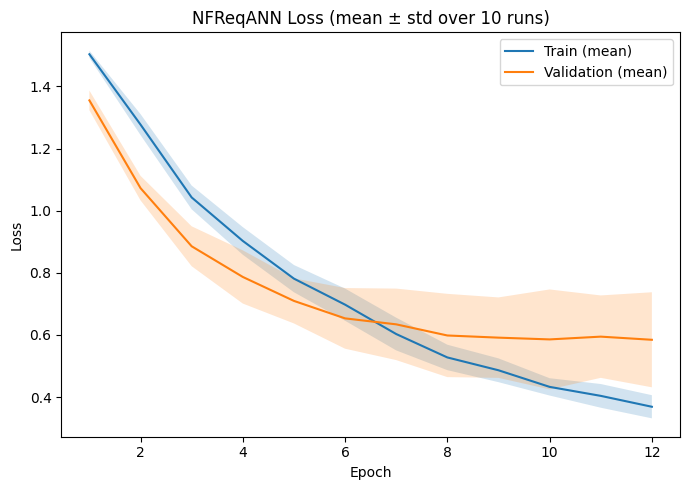


=== Top-20 words by avg positive LIME weight, aggregated over 10 runs ===
        word  avg_positive_lime_weight  avg_tfidf
       built                    0.0000     0.0011
      policy                    0.0000     0.0045
   protected                    0.0000     0.0077
    stronger                    0.0000     0.0004
    encrypts                    0.0000     0.0009
instantiated                    0.0000     0.0011
  regulation                    0.0000     0.0005
    incident                    0.0000     0.0010
          45                    0.0000     0.0005
    clinical                    0.0000     0.0034
       major                    0.0000     0.0008
         mid                    0.0000     0.0005
       layer                    0.0000     0.0008
     viruses                    0.0000     0.0021
 terminating                    0.0000     0.0005
       right                    0.0000     0.0029
     storage                    0.0000     0.0006
  parameters             

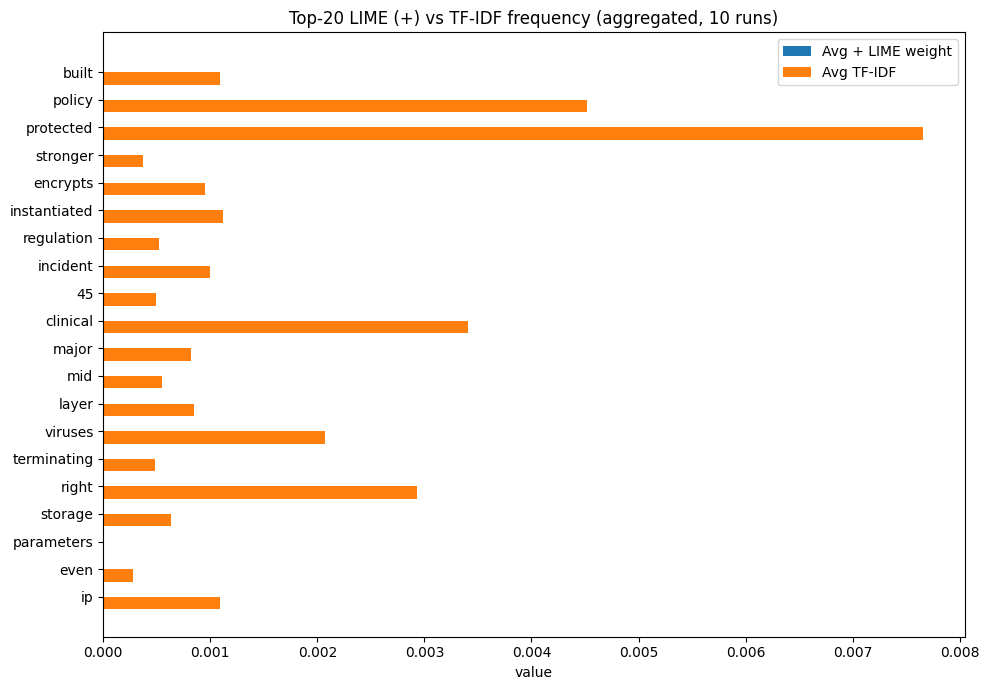

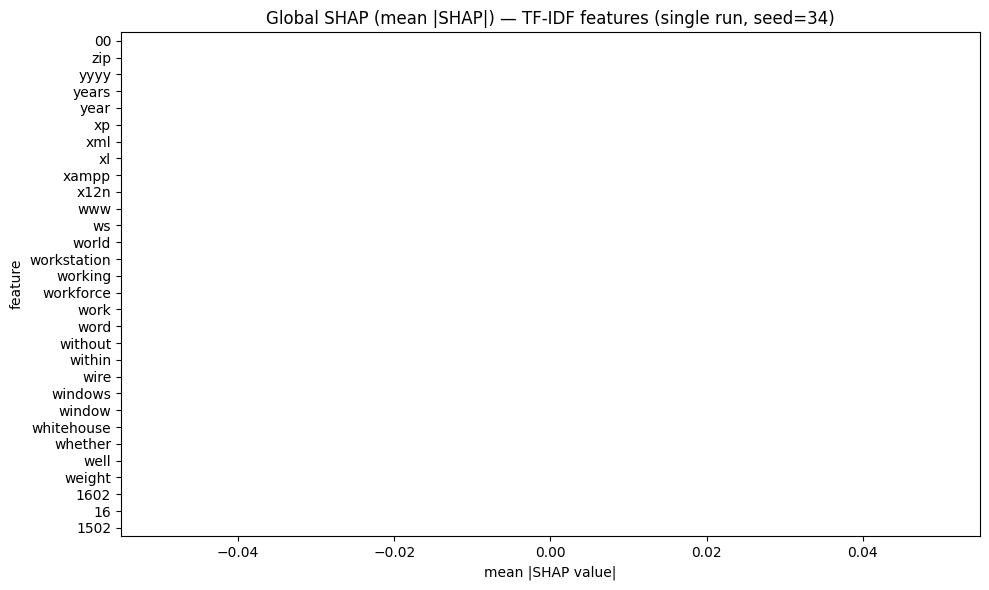


[INFO] All aggregate results, per-run CSVs, and figures saved to: /content/nfreqann_bert_multirun_results
[INFO] Files written:
   - accuracy_curve_mean.png
   - aggregate_metrics.csv
   - computational_cost.csv
   - confusion_matrix_mean.png
   - faithfulness_results.csv
   - lime_vs_tfidf_top20.csv
   - lime_vs_tfidf_top20.png
   - loss_curve_mean.png
   - per_class_metrics.csv
   - per_run_metrics.csv
   - shap_global_summary.png
   - summary.json

DONE: 10 runs completed.


In [ ]:
# Deps: pip install lime shap transformers torch accelerate memory_profiler psutil

import os
import re
import json
import random
import time
import gc
import numpy as np
import pandas as pd
from memory_profiler import memory_usage

# -------- NLTK setup --------
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

# -------- ML / DL --------
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix
)
from sklearn.preprocessing import normalize
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

# -------- Explainability --------
from lime.lime_text import LimeTextExplainer
import shap

# -------- Transformers --------
try:
    import torch
    from transformers import AutoTokenizer, AutoModel
    _TRANSFORMERS_OK = True
except Exception as _e:
    _TRANSFORMERS_OK = False
    print("[INFO] transformers/torch not available yet. "
          "Install with: pip install transformers torch accelerate")

# ============== Configuration ==============
CSV_PATH = "/content/NFR_five.csv"

# ---- Multi-run settings ----
N_RUNS = 10                      # how many times to repeat the whole pipeline (5-10 recommended)
BASE_SEED = 34                   # run i uses seed = BASE_SEED + i  (different split + init each run)
OUTPUT_DIR = "/content/nfreqann_bert_multirun_results"
SHAP_RUN_EVERY_ITERATION = False  # False = run SHAP once (run 0 only) -> standard practice, much faster
                                   # True  = run SHAP every iteration -> rigorous but very slow

TEST_SIZE = 0.20
MAX_FEATURES = 5000
EPOCHS = 12
BATCH_SIZE = 32

INFERENCE_TIMING_REPEATS = 5   # repeat full-test-set inference this many times, average

# LIME / Faithfulness parameters
LIME_NUM_SAMPLES = 1000         # perturbations per instance
LIME_NUM_FEATURES = 10          # tokens highlighted per instance
LIME_SUBSET_SIZE = 100          # how many test rows to explain (cap)
FAITHFULNESS_TOPK = [3, 5, 10]  # deletion tests

# SHAP parameters (keep tiny for speed; raise gradually if needed)
RUN_SHAP = True
SHAP_BACKGROUND_SIZE = 50       # from train set
SHAP_EVAL_SIZE = 100            # from test set
SHAP_NSAMPLES = 200             # Kernel SHAP nsamples heuristic ~ O(features)

# Expected categories (order defines columns)
EXPECTED_CATEGORIES = [
    'Maintainability', 'Operability', 'Performance', 'Security', 'Usability'
]

# ============== DistilBERT feature settings ==============
USE_DISTILBERT = True and _TRANSFORMERS_OK   # flip to False to go back to pure TF-IDF
FEAT_COMBINE = "bert_only"                      # "tfidf" | "bert_only" | "concat"
DISTILBERT_MODEL = "distilbert-base-uncased"
BERT_MAX_LEN = 192
BERT_BATCH_SIZE = 32
BERT_POOLING = "mean"                         # "cls" | "mean"
LIME_USE_BERT = False                        # speed guard: use const-bert during LIME

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============== Cleaning / Preprocessing ==============
REPLACE_BY_SPACE = re.compile(r'[/(){}|@,;]')
STOPWORDS = set(stopwords.words("english"))

# Preserve negation
for w in ["not", "no", "nor"]:
    STOPWORDS.discard(w)

lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = REPLACE_BY_SPACE.sub(" ", text)
    text = re.sub(r"\s+", " ", text).strip()

    tokens = text.split()

    tokens = [
        lemmatizer.lemmatize(t)
        for t in tokens
        if t not in STOPWORDS
    ]

    return " ".join(tokens)

# ============== Load data once (shared across all runs) ==============
df = pd.read_csv(CSV_PATH, encoding='latin1')

if 'sentence' not in df.columns or 'class_name' not in df.columns:
    raise ValueError("CSV must contain columns: 'sentence' and 'class_name'")

df['sentence'] = df['sentence'].fillna('')
df['class_name'] = df['class_name'].fillna('not applicable')
df['text_clean'] = df['sentence'].apply(clean_text)

unknown_mask = ~df['class_name'].isin(EXPECTED_CATEGORIES)
df.loc[unknown_mask, 'class_name'] = 'not applicable'

Y_df = pd.get_dummies(df['class_name'], dtype=int)
Y_df = Y_df.reindex(columns=EXPECTED_CATEGORIES, fill_value=0)
Y_all = Y_df.values
y_idx_all = Y_all.argmax(axis=1)
sentences_all = df['sentence'].tolist()
text_clean_all = df['text_clean'].tolist()

# ============== DistilBERT embedding helpers ==============
def _mean_pool(last_hidden_state, attention_mask):
    mask = attention_mask.unsqueeze(-1).expand(last_hidden_state.size()).float()
    masked = last_hidden_state * mask
    summed = torch.sum(masked, dim=1)
    counts = torch.clamp(mask.sum(dim=1), min=1e-9)
    return summed / counts

def _cls_pool(last_hidden_state):
    return last_hidden_state[:, 0, :]

_bert_tokenizer = None
_bert_model = None
_bert_device = None

def _get_bert():
    """Lazy-load DistilBERT once and reuse across all runs (weights don't change)."""
    global _bert_tokenizer, _bert_model, _bert_device
    if _bert_model is None:
        _bert_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        _bert_tokenizer = AutoTokenizer.from_pretrained(DISTILBERT_MODEL)
        _bert_model = AutoModel.from_pretrained(DISTILBERT_MODEL).to(_bert_device)
        _bert_model.eval()
    return _bert_tokenizer, _bert_model, _bert_device

def build_bert_embeddings(texts):
    tokenizer, model, device = _get_bert()
    outs = []
    with torch.no_grad():
        for i in range(0, len(texts), BERT_BATCH_SIZE):
            batch = texts[i:i+BERT_BATCH_SIZE]
            enc = tokenizer(
                batch, return_tensors="pt", padding=True, truncation=True,
                max_length=BERT_MAX_LEN
            ).to(device)
            out = model(**enc)
            if BERT_POOLING == "mean":
                pooled = _mean_pool(out.last_hidden_state, enc["attention_mask"])
            else:
                pooled = _cls_pool(out.last_hidden_state)
            outs.append(pooled.detach().cpu().numpy())
    return np.vstack(outs).astype(np.float32)


all_bert_embeddings = None
if USE_DISTILBERT:
    print("[INFO] Building DistilBERT sentence embeddings for the full dataset (once)...")
    all_bert_embeddings = build_bert_embeddings(sentences_all)
    all_bert_embeddings = normalize(all_bert_embeddings, norm='l2')
    bert_dim = all_bert_embeddings.shape[1]
    print(f"[INFO] DistilBERT dims: {bert_dim}")


# ============== Model builder ==============
def create_model(input_dim: int, num_classes: int) -> tf.keras.Model:
    model = Sequential([
        Dense(2048, activation="relu", input_dim=input_dim),
        Dropout(0.3),
        Dense(256, activation="relu"),
        Dropout(0.5),
        Dense(128, activation="relu"),
        Dropout(0.5),
        Dense(num_classes, activation="softmax"),
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

def remove_tokens(raw_text: str, tokens_to_remove: list) -> str:
    words = raw_text.split()
    rem = set([t.lower() for t in tokens_to_remove])
    kept = [w for w in words if w.lower() not in rem]
    return " ".join(kept)

_GPU_AVAILABLE = len(tf.config.list_physical_devices('GPU')) > 0

def _reset_gpu_peak():
    if _GPU_AVAILABLE:
        try:
            tf.config.experimental.reset_memory_stats('GPU:0')
        except Exception:
            pass

def _get_gpu_peak_mb():
    if _GPU_AVAILABLE:
        try:
            info = tf.config.experimental.get_memory_info('GPU:0')
            return info['peak'] / (1024 ** 2)
        except Exception:
            return None
    return None

# ============================================================
# ===================== SINGLE RUN ===========================
# ============================================================
def run_once(seed: int, run_idx: int, run_shap_this_run: bool):
    """
    Executes the full pipeline (split -> TF-IDF -> model -> eval ->
    LIME -> faithfulness -> optional SHAP) for one random seed.
    Returns a dict of scalar/array results for later aggregation.
    """
    print(f"\n{'='*70}\nRUN {run_idx+1}/{N_RUNS}  (seed={seed})\n{'='*70}")

    random.seed(seed)
    np.random.seed(seed)

    tf.keras.utils.set_random_seed(seed)

    if _TRANSFORMERS_OK:
        torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # ---- split----
    train_pos_outer, test_pos = train_test_split(
        np.arange(len(sentences_all)),
        test_size=TEST_SIZE,
        random_state=seed,
        stratify=y_idx_all
    )

    # ---- Split train partition further into train/validation ----
    y_train_outer_idx = y_idx_all[train_pos_outer]
    train_pos, val_pos = train_test_split(
        train_pos_outer,
        test_size=0.15,
        random_state=seed,
        stratify=y_train_outer_idx
    )

    train_texts = [text_clean_all[i] for i in train_pos]
    val_texts_clean = [text_clean_all[i] for i in val_pos]
    test_texts_clean = [text_clean_all[i] for i in test_pos]

    Y_train = Y_all[train_pos]
    Y_val = Y_all[val_pos]
    Y_test = Y_all[test_pos]

    y_train_idx = y_idx_all[train_pos]
    y_val_idx = y_idx_all[val_pos]
    y_test_idx = y_idx_all[test_pos]

    test_texts = [sentences_all[i] for i in test_pos]

    tfidf = TfidfVectorizer(
        max_features=MAX_FEATURES,
        min_df=1,
        smooth_idf=True,
        norm="l2"
    )

    X_train = tfidf.fit_transform(train_texts).toarray().astype(np.float32)
    X_val = tfidf.transform(val_texts_clean).toarray().astype(np.float32)
    X_test = tfidf.transform(test_texts_clean).toarray().astype(np.float32)
    test_texts = [sentences_all[i] for i in test_pos]


    Xb_train = Xb_val = Xb_test = None
    BERT_CONST = None
    if USE_DISTILBERT:
        Xb_train = all_bert_embeddings[train_pos]
        Xb_val = all_bert_embeddings[val_pos]
        Xb_test = all_bert_embeddings[test_pos]
        BERT_CONST = np.mean(Xb_train, axis=0, keepdims=True).astype(np.float32)
        BERT_CONST = normalize(BERT_CONST, norm='l2').astype(np.float32)

    X_train_model, X_val_model, X_test_model = X_train, X_val, X_test
    if USE_DISTILBERT:
        if FEAT_COMBINE == "bert_only":
            X_train_model, X_val_model, X_test_model = Xb_train, Xb_val, Xb_test
        elif FEAT_COMBINE == "concat":
            X_train_model = np.concatenate([X_train, Xb_train], axis=1).astype(np.float32)
            X_val_model = np.concatenate([X_val, Xb_val], axis=1).astype(np.float32)
            X_test_model = np.concatenate([X_test, Xb_test], axis=1).astype(np.float32)

    model = create_model(X_train_model.shape[1], num_classes=Y_train.shape[1])
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6, verbose=0)
    early_stop = EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)

    trainable_params = int(np.sum([tf.keras.backend.count_params(w) for w in model.trainable_weights]))

    gc.collect()
    _reset_gpu_peak()

    def _fit_call():
        return model.fit(
            X_train_model, Y_train,
            epochs=EPOCHS, batch_size=BATCH_SIZE,
            validation_data=(X_val_model, Y_val),
            callbacks=[reduce_lr, early_stop], verbose=0
        )

    t0 = time.time()
    mem_during_train = memory_usage((_fit_call, (), {}), interval=0.2, max_usage=True, retval=True)
    train_time_sec = time.time() - t0
    peak_mem_train_mb, history = mem_during_train
    gpu_peak_train_mb = _get_gpu_peak_mb()

    # ---- classification metrics ----
    y_proba = model.predict(X_test_model, verbose=0)  # warm-up call, excluded from timing

    gc.collect()
    _reset_gpu_peak()

    def _predict_call():
        return model.predict(X_test_model, verbose=0)

    inf_times = []
    peak_mem_inf_mb = 0.0
    for _ in range(INFERENCE_TIMING_REPEATS):
        t0 = time.time()
        mem_usage_val, _ = memory_usage((_predict_call, (), {}), interval=0.2, max_usage=True, retval=True)
        inf_times.append(time.time() - t0)
        peak_mem_inf_mb = max(peak_mem_inf_mb, mem_usage_val)

    n_test_items = X_test_model.shape[0]
    inference_time_per_item_sec = float(np.mean(inf_times)) / n_test_items
    gpu_peak_inf_mb = _get_gpu_peak_mb()

    peak_memory_mb = max(peak_mem_train_mb, peak_mem_inf_mb)
    gpu_peak_mb = None
    if gpu_peak_train_mb is not None or gpu_peak_inf_mb is not None:
        gpu_peak_mb = max(x for x in [gpu_peak_train_mb, gpu_peak_inf_mb] if x is not None)

    y_pred_idx = np.argmax(y_proba, axis=1)
    y_true_idx = y_test_idx

    cm = confusion_matrix(y_true_idx, y_pred_idx, labels=np.arange(len(EXPECTED_CATEGORIES)))
    acc = accuracy_score(y_true_idx, y_pred_idx)
    prec_macro = precision_score(y_true_idx, y_pred_idx, average='macro', zero_division=0)
    rec_macro = recall_score(y_true_idx, y_pred_idx, average='macro', zero_division=0)
    f1_macro = f1_score(y_true_idx, y_pred_idx, average='macro', zero_division=0)
    prec_weighted = precision_score(y_true_idx, y_pred_idx, average='weighted', zero_division=0)
    rec_weighted = recall_score(y_true_idx, y_pred_idx, average='weighted', zero_division=0)
    f1_weighted = f1_score(y_true_idx, y_pred_idx, average='weighted', zero_division=0)

    per_class_report = classification_report(
        y_true_idx, y_pred_idx, labels=np.arange(len(EXPECTED_CATEGORIES)),
        target_names=EXPECTED_CATEGORIES, digits=4, zero_division=0, output_dict=True
    )

    train_loss, train_acc = model.evaluate(X_train_model, Y_train, verbose=0)
    test_loss, test_acc = model.evaluate(X_test_model, Y_test, verbose=0)

    print(f"  Acc={acc:.4f}  F1(macro)={f1_macro:.4f}  F1(weighted)={f1_weighted:.4f}")

    # ---- feature builder for LIME / SHAP within this run's fitted tfidf/model ----
    def _build_features_for_texts(texts):
        cleaned = [clean_text(t) for t in texts]
        X_tfidf = tfidf.transform(cleaned).toarray().astype(np.float32)
        if USE_DISTILBERT:
            if LIME_USE_BERT or len(texts) <= 64:
                X_bert = build_bert_embeddings(texts).astype(np.float32)
                X_bert = normalize(X_bert, norm='l2').astype(np.float32)
            else:
                X_bert = np.repeat(BERT_CONST, repeats=len(texts), axis=0).astype(np.float32)
            if FEAT_COMBINE == "bert_only":
                return X_bert
            elif FEAT_COMBINE == "concat":
                return np.concatenate([X_tfidf, X_bert], axis=1).astype(np.float32)
            else:
                return X_tfidf
        else:
            return X_tfidf

    def predict_proba_texts(texts: list) -> np.ndarray:
        X_ = _build_features_for_texts(texts)
        return model.predict(X_, verbose=0)

    # ---- LIME on test subset ----
    explainer = LimeTextExplainer(class_names=EXPECTED_CATEGORIES, bow=True)
    test_indices = np.arange(len(test_texts))
    rng = np.random.default_rng(seed)
    rng.shuffle(test_indices)
    subset_idx = test_indices[:min(LIME_SUBSET_SIZE, len(test_texts))]
    subset_texts = [test_texts[i] for i in subset_idx]

    lime_fidelities, lime_sparsities, lime_highlight_counts = [], [], []
    lime_token_weights_per_word = {}
    faithfulness_results = {k: [] for k in FAITHFULNESS_TOPK}

    for t in subset_texts:
        proba = predict_proba_texts([t])[0]
        pred_label = int(np.argmax(proba))
        exp = explainer.explain_instance(
            t, predict_proba_texts,
            num_features=LIME_NUM_FEATURES, num_samples=LIME_NUM_SAMPLES,
            labels=[pred_label]
        )
        lime_fidelities.append(exp.score)
        items = exp.as_list(label=pred_label)
        lime_sparsities.append(len(items))
        lime_highlight_counts.append(len(items))
        for tok, w in items:
            if w > 0:
                lime_token_weights_per_word.setdefault(tok.lower(), []).append(w)

        # faithfulness deletion test reuses this same explanation
        top_tokens = [tok for tok, w in sorted(items, key=lambda x: -x[1]) if w > 0]
        p_full = proba
        for k in FAITHFULNESS_TOPK:
            picked = top_tokens[:min(k, len(top_tokens))]
            t_del = remove_tokens(t, picked)
            p_del = predict_proba_texts([t_del])[0]
            drop = p_full[pred_label] - p_del[pred_label]
            faithfulness_results[k].append(max(0.0, drop))

    lime_summary = {
        "fidelity_mean": float(np.mean(lime_fidelities)),
        "fidelity_std": float(np.std(lime_fidelities)),
        "sparsity_mean": float(np.mean(lime_sparsities)),
        "n_explained": len(subset_texts),
    }
    faithfulness_summary = {
        k: {"mean": float(np.mean(v)), "std": float(np.std(v))}
        for k, v in faithfulness_results.items()
    }

    print(f"  LIME fidelity={lime_summary['fidelity_mean']:.3f}±{lime_summary['fidelity_std']:.3f}  "
          f"Faithfulness@5={faithfulness_summary[5]['mean']:.4f}")

    # ---- SHAP (optional, expensive) ----
    shap_top_features = None
    if RUN_SHAP and run_shap_this_run:
        print("  Running SHAP (KernelExplainer)...")
        rng2 = np.random.default_rng(seed)
        bg_idx = rng2.choice(len(X_train), size=min(SHAP_BACKGROUND_SIZE, len(X_train)), replace=False)
        ev_idx = rng2.choice(len(X_test), size=min(SHAP_EVAL_SIZE, len(X_test)), replace=False)
        X_bg = X_train[bg_idx]
        X_ev = X_test[ev_idx]

        def predict_proba_dense(x):
            x = np.asarray(x, dtype=np.float32)
            if USE_DISTILBERT:
                if FEAT_COMBINE == "bert_only":
                    full_x = np.repeat(BERT_CONST, repeats=x.shape[0], axis=0).astype(np.float32)
                elif FEAT_COMBINE == "concat":
                    bert_part = np.repeat(BERT_CONST, repeats=x.shape[0], axis=0).astype(np.float32)
                    full_x = np.concatenate([x, bert_part], axis=1).astype(np.float32)
                else:
                    full_x = x
            else:
                full_x = x
            return model.predict(full_x, verbose=0)

        explainer_shap = shap.KernelExplainer(predict_proba_dense, X_bg, link="identity")
        shap_values = explainer_shap.shap_values(X_ev, nsamples=SHAP_NSAMPLES)

        if isinstance(shap_values, list):
            mean_abs_per_class = [np.mean(np.abs(sv), axis=0) for sv in shap_values]
            mean_abs_global = np.mean(np.stack(mean_abs_per_class, axis=0), axis=0)
        else:
            mean_abs_global = np.mean(np.abs(shap_values), axis=0)

        vocab_items = sorted(tfidf.vocabulary_.items(), key=lambda kv: kv[1])
        feature_names = np.array([w for w, idx in vocab_items])
        mag = np.asarray(mean_abs_global, dtype=float).reshape(-1)[:feature_names.shape[0]]
        order = np.argsort(mag)[::-1][:min(30, len(mag))]
        shap_top_features = list(zip(feature_names[order].tolist(), mag[order].tolist()))

    return {
        "seed": seed,
        "history": history.history,
        "confusion_matrix": cm,
        "metrics": {
            "accuracy": acc, "precision_macro": prec_macro, "recall_macro": rec_macro,
            "f1_macro": f1_macro, "precision_weighted": prec_weighted,
            "recall_weighted": rec_weighted, "f1_weighted": f1_weighted,
            "train_acc": float(train_acc), "test_acc": float(test_acc),
            "train_loss": float(train_loss), "test_loss": float(test_loss),
        },
        "per_class_report": per_class_report,
        "lime_summary": lime_summary,
        "faithfulness_summary": faithfulness_summary,
        "lime_token_weights": lime_token_weights_per_word,
        "shap_top_features": shap_top_features,
        "tfidf_test_matrix": X_test if shap_top_features is not None else None,
        "tfidf_vocab": dict(tfidf.vocabulary_) if shap_top_features is not None else None,
        "computational_cost": {
            "trainable_params": trainable_params,
            "train_time_sec": float(train_time_sec),
            "inference_time_per_item_sec": float(inference_time_per_item_sec),
            "peak_memory_mb": float(peak_memory_mb),
            "gpu_peak_memory_mb": gpu_peak_mb,
        },
    }

# ============================================================
# ===================== DRIVER LOOP ===========================
# ============================================================
all_results = []
for i in range(N_RUNS):
    seed_i = BASE_SEED + i
    shap_this_run = (i == 0) if not SHAP_RUN_EVERY_ITERATION else True
    res = run_once(seed_i, i, run_shap_this_run=shap_this_run)
    all_results.append(res)

# ============================================================
# ================= AGGREGATION / REPORTING ===================
# ============================================================
def agg_mean_std(values):
    arr = np.array(values, dtype=float)
    return float(np.mean(arr)), float(np.std(arr))

metric_keys = list(all_results[0]["metrics"].keys())
agg_metrics = {}
for mk in metric_keys:
    vals = [r["metrics"][mk] for r in all_results]
    mean_v, std_v = agg_mean_std(vals)
    agg_metrics[mk] = {"mean": mean_v, "std": std_v, "values": vals}

print(f"\n{'='*70}\nAGGREGATE RESULTS OVER {N_RUNS} RUNS (seeds {BASE_SEED}..{BASE_SEED+N_RUNS-1})\n{'='*70}")
metrics_table = pd.DataFrame({
    "metric": metric_keys,
    "mean": [agg_metrics[m]["mean"] for m in metric_keys],
    "std": [agg_metrics[m]["std"] for m in metric_keys],
})
print(metrics_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# ---- per-class metrics aggregation (precision/recall/f1 per category) ----
per_class_rows = []
for cat in EXPECTED_CATEGORIES:
    p_vals = [r["per_class_report"][cat]["precision"] for r in all_results]
    r_vals = [r["per_class_report"][cat]["recall"] for r in all_results]
    f_vals = [r["per_class_report"][cat]["f1-score"] for r in all_results]
    s_vals = [r["per_class_report"][cat]["support"] for r in all_results]
    p_m, p_s = agg_mean_std(p_vals)
    r_m, r_s = agg_mean_std(r_vals)
    f_m, f_s = agg_mean_std(f_vals)
    per_class_rows.append({
        "class": cat,
        "precision_mean": p_m, "precision_std": p_s,
        "recall_mean": r_m, "recall_std": r_s,
        "f1_mean": f_m, "f1_std": f_s,
        "support_mean": float(np.mean(s_vals)),
    })
per_class_df = pd.DataFrame(per_class_rows)
print("\n=== Per-class metrics (mean ± std across runs) ===")
print(per_class_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# ---- Computational cost aggregation ----
cost_keys = ["trainable_params", "train_time_sec", "inference_time_per_item_sec", "peak_memory_mb"]
cost_rows = []
for ck in cost_keys:
    vals = [r["computational_cost"][ck] for r in all_results]
    m, s = agg_mean_std(vals)
    cost_rows.append({"metric": ck, "mean": m, "std": s})

gpu_vals = [r["computational_cost"]["gpu_peak_memory_mb"] for r in all_results
            if r["computational_cost"]["gpu_peak_memory_mb"] is not None]
if gpu_vals:
    gm, gs = agg_mean_std(gpu_vals)
    cost_rows.append({"metric": "gpu_peak_memory_mb", "mean": gm, "std": gs})

cost_df = pd.DataFrame(cost_rows)
print(f"\n=== Computational cost (mean ± std over {N_RUNS} runs) ===")
print(cost_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
cost_df.to_csv(os.path.join(OUTPUT_DIR, "computational_cost.csv"), index=False)

# ---- LIME aggregation ----
lime_fid_vals = [r["lime_summary"]["fidelity_mean"] for r in all_results]
lime_sparsity_vals = [r["lime_summary"]["sparsity_mean"] for r in all_results]
fid_m, fid_s = agg_mean_std(lime_fid_vals)
spar_m, spar_s = agg_mean_std(lime_sparsity_vals)
print(f"\n=== LIME (aggregated over {N_RUNS} runs, {LIME_SUBSET_SIZE} instances/run) ===")
print(f"Fidelity:  {fid_m:.4f} ± {fid_s:.4f}")
print(f"Sparsity:  {spar_m:.4f} ± {spar_s:.4f}")

# ---- Faithfulness aggregation ----
print(f"\n=== Faithfulness (Deletion Test), aggregated over {N_RUNS} runs ===")
faith_rows = []
for k in FAITHFULNESS_TOPK:
    vals = [r["faithfulness_summary"][k]["mean"] for r in all_results]
    m, s = agg_mean_std(vals)
    faith_rows.append({"top_k": k, "mean_prob_drop": m, "std_prob_drop": s})
    print(f"Top-{k} removal -> Avg prob drop: {m:.4f} ± {s:.4f}")
faith_df = pd.DataFrame(faith_rows)

# ---- averaged confusion matrix ----
cm_stack = np.stack([r["confusion_matrix"] for r in all_results], axis=0)
cm_mean = cm_stack.mean(axis=0)
cm_std = cm_stack.std(axis=0)

plt.figure(figsize=(10,7))
sns.heatmap(cm_mean, annot=True, fmt='.1f', cmap='Blues',
            xticklabels=EXPECTED_CATEGORIES, yticklabels=EXPECTED_CATEGORIES)
plt.title(f'NFReqANN Confusion Matrix (mean over {N_RUNS} runs)')
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix_mean.png"), dpi=150)
plt.show()

# ---- averaged training curves (pad/truncate to shortest run length due to early stopping) ----
min_epochs = min(len(r["history"]["accuracy"]) for r in all_results)
train_acc_mat = np.stack([r["history"]["accuracy"][:min_epochs] for r in all_results])
val_acc_mat = np.stack([r["history"]["val_accuracy"][:min_epochs] for r in all_results])
train_loss_mat = np.stack([r["history"]["loss"][:min_epochs] for r in all_results])
val_loss_mat = np.stack([r["history"]["val_loss"][:min_epochs] for r in all_results])

epochs_axis = np.arange(1, min_epochs + 1)

plt.figure(figsize=(7,5))
plt.plot(epochs_axis, train_acc_mat.mean(axis=0), label='Train (mean)')
plt.fill_between(epochs_axis, train_acc_mat.mean(0)-train_acc_mat.std(0),
                  train_acc_mat.mean(0)+train_acc_mat.std(0), alpha=0.2)
plt.plot(epochs_axis, val_acc_mat.mean(axis=0), label='Validation (mean)')
plt.fill_between(epochs_axis, val_acc_mat.mean(0)-val_acc_mat.std(0),
                  val_acc_mat.mean(0)+val_acc_mat.std(0), alpha=0.2)
plt.title(f'NFReqANN Accuracy (mean ± std over {N_RUNS} runs)')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "accuracy_curve_mean.png"), dpi=150)
plt.show()

plt.figure(figsize=(7,5))
plt.plot(epochs_axis, train_loss_mat.mean(axis=0), label='Train (mean)')
plt.fill_between(epochs_axis, train_loss_mat.mean(0)-train_loss_mat.std(0),
                  train_loss_mat.mean(0)+train_loss_mat.std(0), alpha=0.2)
plt.plot(epochs_axis, val_loss_mat.mean(axis=0), label='Validation (mean)')
plt.fill_between(epochs_axis, val_loss_mat.mean(0)-val_loss_mat.std(0),
                  val_loss_mat.mean(0)+val_loss_mat.std(0), alpha=0.2)
plt.title(f'NFReqANN Loss (mean ± std over {N_RUNS} runs)')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "loss_curve_mean.png"), dpi=150)
plt.show()

# ---- LIME vs TF-IDF top-20 words, aggregated across all runs ----
combined_lime_weights = {}
for r in all_results:
    for w, ws in r["lime_token_weights"].items():
        combined_lime_weights.setdefault(w, []).extend(ws)

lime_avg_pos = {w: np.mean(ws) for w, ws in combined_lime_weights.items() if len(ws) > 0}


last_run = all_results[-1]
last_tfidf_path_vocab = None
tfidf_ref = TfidfVectorizer(max_features=MAX_FEATURES, min_df=1, smooth_idf=True, norm='l2')
X_ref_sparse = tfidf_ref.fit_transform(text_clean_all)
X_ref = X_ref_sparse.toarray().astype(np.float32)
vocab_ref = tfidf_ref.vocabulary_

def avg_tfidf_for_word(w):
    idx = vocab_ref.get(w, None)
    if idx is None:
        return 0.0
    return float(np.mean(X_ref[:, idx]))

pairs = [(w, avg_w, avg_tfidf_for_word(w)) for w, avg_w in lime_avg_pos.items()]
comp_df = pd.DataFrame(pairs, columns=["word", "avg_positive_lime_weight", "avg_tfidf"])
comp_top20 = comp_df.sort_values("avg_positive_lime_weight", ascending=False).head(20).reset_index(drop=True)

print(f"\n=== Top-20 words by avg positive LIME weight, aggregated over {N_RUNS} runs ===")
print(comp_top20.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

plt.figure(figsize=(10,7))
indices = np.arange(len(comp_top20))
barw = 0.45
plt.barh(indices + 0.0, comp_top20["avg_positive_lime_weight"].values, height=barw, label="Avg + LIME weight")
plt.barh(indices + barw, comp_top20["avg_tfidf"].values, height=barw, label="Avg TF-IDF")
plt.yticks(indices + barw/2, comp_top20["word"].values)
plt.gca().invert_yaxis()
plt.title(f"Top-20 LIME (+) vs TF-IDF frequency (aggregated, {N_RUNS} runs)")
plt.xlabel("value"); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "lime_vs_tfidf_top20.png"), dpi=150)
plt.show()

# ---- SHAP (from whichever run computed it) ----
shap_run = next((r for r in all_results if r["shap_top_features"] is not None), None)
if shap_run is not None:
    feats, vals = zip(*shap_run["shap_top_features"])
    plt.figure(figsize=(10,6))
    sns.barplot(x=list(vals), y=list(feats), orient='h')
    note = "single run" if not SHAP_RUN_EVERY_ITERATION else "averaged"
    plt.title(f"Global SHAP (mean |SHAP|) — TF-IDF features ({note}, seed={shap_run['seed']})")
    plt.xlabel("mean |SHAP value|"); plt.ylabel("feature")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "shap_global_summary.png"), dpi=150)
    plt.show()

# ============================================================
# ===================== SAVE ARTIFACTS =========================
# ============================================================
metrics_table.to_csv(os.path.join(OUTPUT_DIR, "aggregate_metrics.csv"), index=False)
per_class_df.to_csv(os.path.join(OUTPUT_DIR, "per_class_metrics.csv"), index=False)
faith_df.to_csv(os.path.join(OUTPUT_DIR, "faithfulness_results.csv"), index=False)
comp_top20.to_csv(os.path.join(OUTPUT_DIR, "lime_vs_tfidf_top20.csv"), index=False)

run_level_rows = []
for r in all_results:
    row = {"seed": r["seed"], **r["metrics"], **r["computational_cost"],
           "lime_fidelity": r["lime_summary"]["fidelity_mean"],
           "lime_sparsity": r["lime_summary"]["sparsity_mean"]}
    for k in FAITHFULNESS_TOPK:
        row[f"faithfulness_top{k}"] = r["faithfulness_summary"][k]["mean"]
    run_level_rows.append(row)
run_level_df = pd.DataFrame(run_level_rows)
run_level_df.to_csv(os.path.join(OUTPUT_DIR, "per_run_metrics.csv"), index=False)

summary_json = {
    "n_runs": N_RUNS,
    "seeds": [r["seed"] for r in all_results],
    "metrics_mean_std": {m: {"mean": agg_metrics[m]["mean"], "std": agg_metrics[m]["std"]} for m in metric_keys},
    "lime_fidelity_mean_std": {"mean": fid_m, "std": fid_s},
    "lime_sparsity_mean_std": {"mean": spar_m, "std": spar_s},
    "faithfulness_mean_std": {str(k): {"mean": float(np.mean([r["faithfulness_summary"][k]["mean"] for r in all_results])),
                                        "std": float(np.std([r["faithfulness_summary"][k]["mean"] for r in all_results]))}
                               for k in FAITHFULNESS_TOPK},
}
with open(os.path.join(OUTPUT_DIR, "summary.json"), "w") as f:
    json.dump(summary_json, f, indent=2)

print(f"\n[INFO] All aggregate results, per-run CSVs, and figures saved to: {OUTPUT_DIR}")
print("[INFO] Files written:")
for fn in sorted(os.listdir(OUTPUT_DIR)):
    print(f"   - {fn}")

print(f"\n{'='*70}\nDONE: {N_RUNS} runs completed.\n{'='*70}")

# **NFReqANN (Hybrid) (multiseed)**

In [ ]:
pip install lime shap transformers torch accelerate memory_profiler psutil

[INFO] Building DistilBERT sentence embeddings for the full dataset (once)...


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[INFO] DistilBERT dims: 768

RUN 1/10  (seed=34)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


  Acc=0.8852  F1(macro)=0.8579  F1(weighted)=0.8829
  LIME fidelity=0.837±0.144  Faithfulness@5=0.2594
  Running SHAP (KernelExplainer)...


... (16 outputs left out)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


  Acc=0.8689  F1(macro)=0.8515  F1(weighted)=0.8696
  LIME fidelity=0.696±0.236  Faithfulness@5=0.3125

RUN 10/10  (seed=43)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


  Acc=0.8470  F1(macro)=0.8110  F1(weighted)=0.8473
  LIME fidelity=0.825±0.187  Faithfulness@5=0.2798

AGGREGATE RESULTS OVER 10 RUNS (seeds 34..43)
            metric   mean    std
          accuracy 0.8623 0.0206
   precision_macro 0.8503 0.0209
      recall_macro 0.8399 0.0226
          f1_macro 0.8413 0.0201
precision_weighted 0.8663 0.0183
   recall_weighted 0.8623 0.0206
       f1_weighted 0.8612 0.0195
         train_acc 0.9721 0.0148
          test_acc 0.8623 0.0206
        train_loss 0.1078 0.0587
         test_loss 0.4932 0.0917

=== Per-class metrics (mean ± std across runs) ===
          class  precision_mean  precision_std  recall_mean  recall_std  f1_mean  f1_std  support_mean
Maintainability          0.7740         0.0998       0.7778      0.0497   0.7704  0.0443       27.0000
    Operability          0.8425         0.0651       0.7323      0.0434   0.7817  0.0389       31.0000
    Performance          0.8750         0.0571       0.8696      0.0991   0.8677  0.0544     

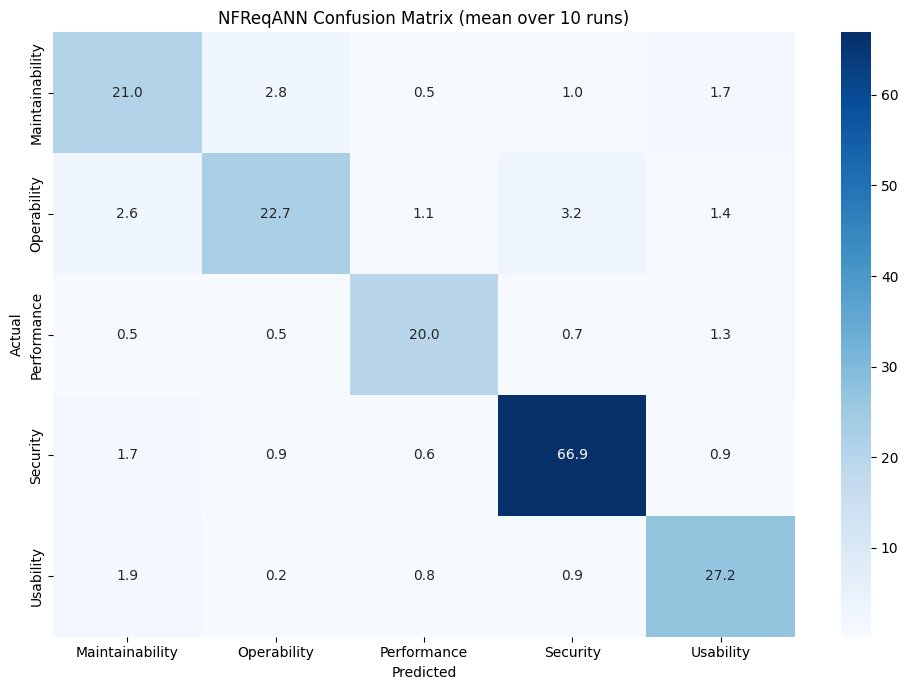

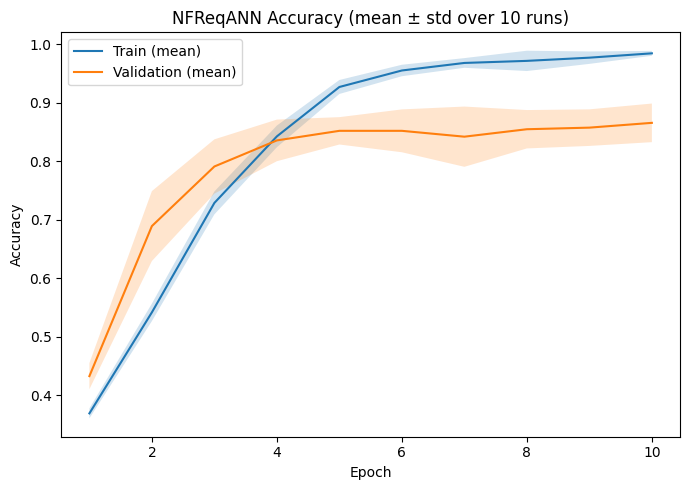

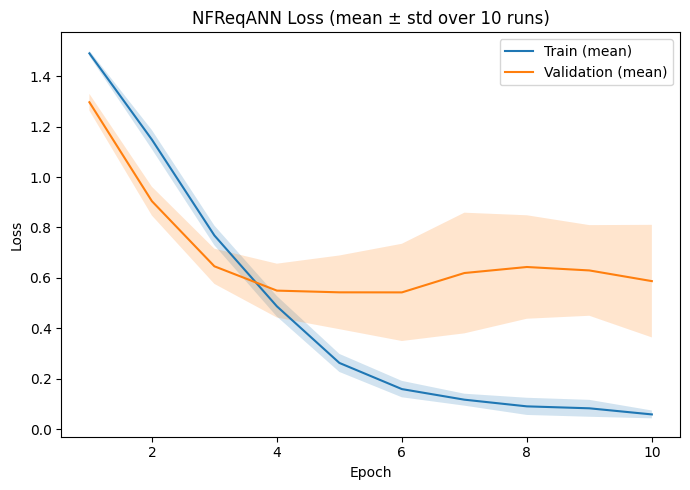


=== Top-20 words by avg positive LIME weight, aggregated over 10 runs ===
         word  avg_positive_lime_weight  avg_tfidf
     internal                    0.4447     0.0010
automatically                    0.3351     0.0012
        codes                    0.2997     0.0004
         code                    0.2826     0.0061
      viruses                    0.2801     0.0021
       rights                    0.2656     0.0000
      letters                    0.2471     0.0000
 reservations                    0.2456     0.0000
      general                    0.2393     0.0012
      element                    0.2304     0.0025
      objects                    0.2263     0.0000
       fields                    0.2263     0.0012
         help                    0.2255     0.0035
        loinc                    0.2255     0.0016
          hl7                    0.2250     0.0006
    operating                    0.2208     0.0038
   identified                    0.2198     0.0016
    dis

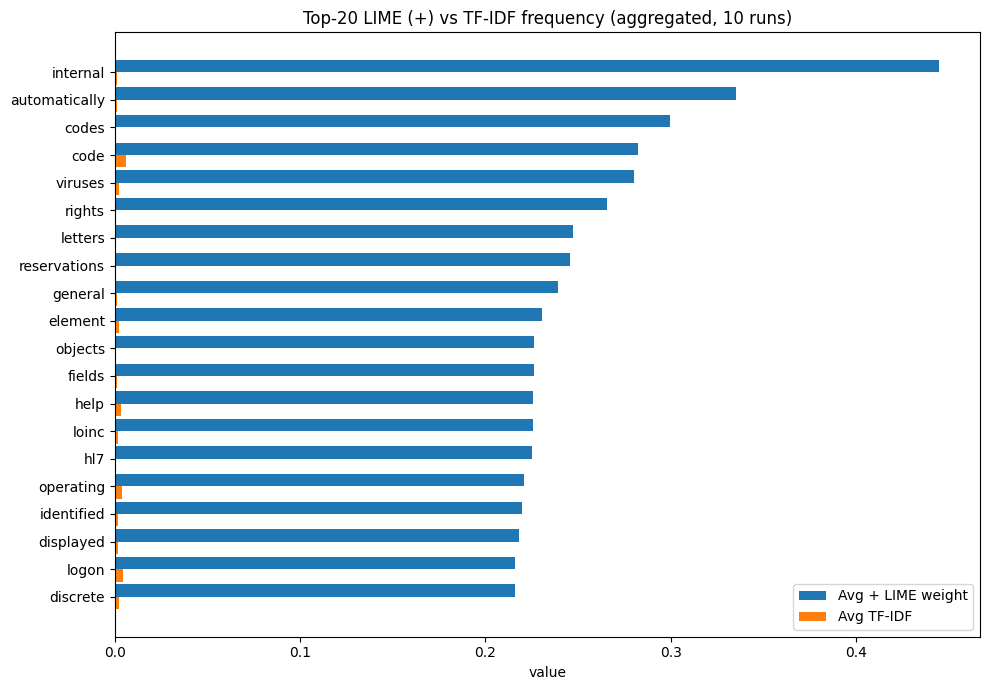

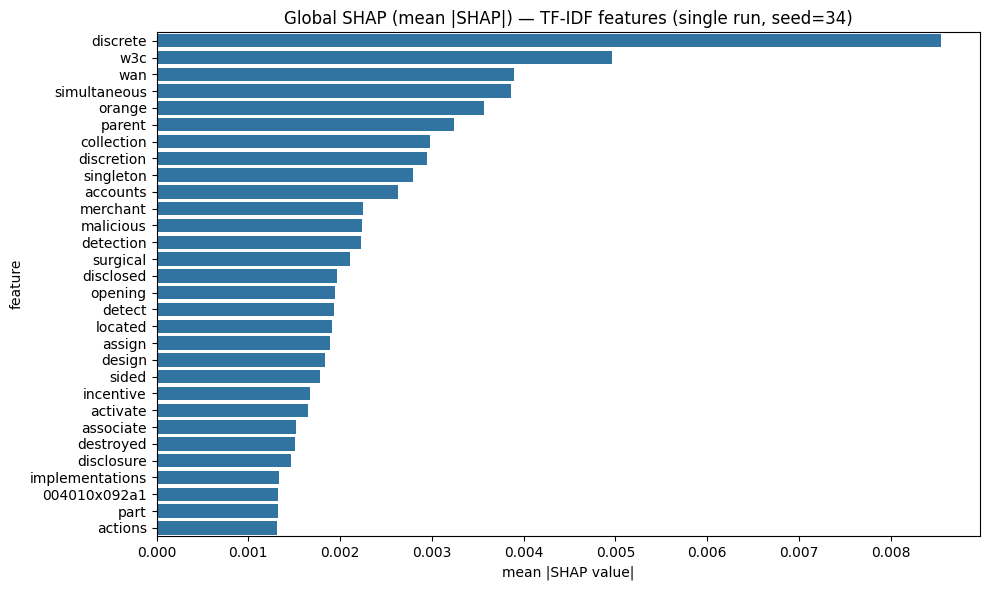


[INFO] All aggregate results, per-run CSVs, and figures saved to: /content/nfreqann_hybrid_multirun_results
[INFO] Files written:
   - accuracy_curve_mean.png
   - aggregate_metrics.csv
   - computational_cost.csv
   - confusion_matrix_mean.png
   - faithfulness_results.csv
   - lime_vs_tfidf_top20.csv
   - lime_vs_tfidf_top20.png
   - local_lime_example.json
   - loss_curve_mean.png
   - per_class_metrics.csv
   - per_run_metrics.csv
   - shap_global_summary.png
   - summary.json

DONE: 10 runs completed.


In [ ]:
# Deps: pip install lime shap transformers torch accelerate memory_profiler psutil

import os
import re
import json
import random
import time
import gc
import numpy as np
import pandas as pd
from memory_profiler import memory_usage

# -------- NLTK setup --------
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

# -------- ML / DL --------
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix
)
from sklearn.preprocessing import normalize
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

# -------- Explainability --------
from lime.lime_text import LimeTextExplainer
import shap

# -------- Transformers --------
try:
    import torch
    from transformers import AutoTokenizer, AutoModel
    _TRANSFORMERS_OK = True
except Exception as _e:
    _TRANSFORMERS_OK = False
    print("[INFO] transformers/torch not available yet. "
          "Install with: pip install transformers torch accelerate")

# ============== Configuration ==============
CSV_PATH = "/content/NFR_five.csv"

# ---- Multi-run settings ----
N_RUNS = 10                      # how many times to repeat the whole pipeline (5-10 recommended)
BASE_SEED = 34                   # run i uses seed = BASE_SEED + i  (different split + init each run)
OUTPUT_DIR = "/content/nfreqann_hybrid_multirun_results"
SHAP_RUN_EVERY_ITERATION = False  # False = run SHAP once (run 0 only) -> standard practice, much faster
                                   # True  = run SHAP every iteration -> rigorous but very slow

TEST_SIZE = 0.20
MAX_FEATURES = 5000
EPOCHS = 12
BATCH_SIZE = 32

INFERENCE_TIMING_REPEATS = 5   # repeat full-test-set inference this many times, average

# LIME / Faithfulness parameters
LIME_NUM_SAMPLES = 1000         # perturbations per instance
LIME_NUM_FEATURES = 10          # tokens highlighted per instance
LIME_SUBSET_SIZE = 100          # how many test rows to explain (cap)
FAITHFULNESS_TOPK = [3, 5, 10]  # deletion tests

# SHAP parameters (keep tiny for speed; raise gradually if needed)
RUN_SHAP = True
SHAP_BACKGROUND_SIZE = 50       # from train set
SHAP_EVAL_SIZE = 100            # from test set
SHAP_NSAMPLES = 200             # Kernel SHAP nsamples heuristic ~ O(features)

# Expected categories (order defines columns)
EXPECTED_CATEGORIES = [
    'Maintainability', 'Operability', 'Performance', 'Security', 'Usability'
]
# EXPECTED_CATEGORIES = [
#     'Maintainability', 'Operability', 'Performance', 'Security', 'Usability',
#     'functional', 'other nonfunctional', 'not applicable'
# ]

# ============== DistilBERT feature settings ==============
USE_DISTILBERT = True and _TRANSFORMERS_OK   # flip to False to go back to pure TF-IDF
FEAT_COMBINE = "concat"                      # "tfidf" | "bert_only" | "concat"
DISTILBERT_MODEL = "distilbert-base-uncased"
BERT_MAX_LEN = 192
BERT_BATCH_SIZE = 32
BERT_POOLING = "mean"                         # "cls" | "mean"
LIME_USE_BERT = False                        # speed guard: use const-bert during LIME

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============== Cleaning / Preprocessing ==============
REPLACE_BY_SPACE = re.compile(r'[/(){}|@,;]')
STOPWORDS = set(stopwords.words("english"))

# Preserve negation
for w in ["not", "no", "nor"]:
    STOPWORDS.discard(w)

lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = REPLACE_BY_SPACE.sub(" ", text)
    text = re.sub(r"\s+", " ", text).strip()

    tokens = text.split()

    tokens = [
        lemmatizer.lemmatize(t)
        for t in tokens
        if t not in STOPWORDS
    ]

    return " ".join(tokens)

# ============== Load data once (shared across all runs) ==============
df = pd.read_csv(CSV_PATH, encoding='latin1')

if 'sentence' not in df.columns or 'class_name' not in df.columns:
    raise ValueError("CSV must contain columns: 'sentence' and 'class_name'")

df['sentence'] = df['sentence'].fillna('')
df['class_name'] = df['class_name'].fillna('not applicable')
df['text_clean'] = df['sentence'].apply(clean_text)

unknown_mask = ~df['class_name'].isin(EXPECTED_CATEGORIES)
df.loc[unknown_mask, 'class_name'] = 'not applicable'

Y_df = pd.get_dummies(df['class_name'], dtype=int)
Y_df = Y_df.reindex(columns=EXPECTED_CATEGORIES, fill_value=0)
Y_all = Y_df.values
y_idx_all = Y_all.argmax(axis=1)
sentences_all = df['sentence'].tolist()
text_clean_all = df['text_clean'].tolist()

# ============== DistilBERT embedding helpers ==============
def _mean_pool(last_hidden_state, attention_mask):
    mask = attention_mask.unsqueeze(-1).expand(last_hidden_state.size()).float()
    masked = last_hidden_state * mask
    summed = torch.sum(masked, dim=1)
    counts = torch.clamp(mask.sum(dim=1), min=1e-9)
    return summed / counts

def _cls_pool(last_hidden_state):
    return last_hidden_state[:, 0, :]

_bert_tokenizer = None
_bert_model = None
_bert_device = None

def _get_bert():
    """Lazy-load DistilBERT once and reuse across all runs (weights don't change)."""
    global _bert_tokenizer, _bert_model, _bert_device
    if _bert_model is None:
        _bert_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        _bert_tokenizer = AutoTokenizer.from_pretrained(DISTILBERT_MODEL)
        _bert_model = AutoModel.from_pretrained(DISTILBERT_MODEL).to(_bert_device)
        _bert_model.eval()
    return _bert_tokenizer, _bert_model, _bert_device

def build_bert_embeddings(texts):
    tokenizer, model, device = _get_bert()
    outs = []
    with torch.no_grad():
        for i in range(0, len(texts), BERT_BATCH_SIZE):
            batch = texts[i:i+BERT_BATCH_SIZE]
            enc = tokenizer(
                batch, return_tensors="pt", padding=True, truncation=True,
                max_length=BERT_MAX_LEN
            ).to(device)
            out = model(**enc)
            if BERT_POOLING == "mean":
                pooled = _mean_pool(out.last_hidden_state, enc["attention_mask"])
            else:
                pooled = _cls_pool(out.last_hidden_state)
            outs.append(pooled.detach().cpu().numpy())
    return np.vstack(outs).astype(np.float32)


all_bert_embeddings = None
if USE_DISTILBERT:
    print("[INFO] Building DistilBERT sentence embeddings for the full dataset (once)...")
    all_bert_embeddings = build_bert_embeddings(sentences_all)
    all_bert_embeddings = normalize(all_bert_embeddings, norm='l2')
    bert_dim = all_bert_embeddings.shape[1]
    print(f"[INFO] DistilBERT dims: {bert_dim}")

# ============== Model builder ==============
def create_model(input_dim: int, num_classes: int) -> tf.keras.Model:
    model = Sequential([
        Dense(2048, activation="relu", input_dim=input_dim),
        Dropout(0.3),
        Dense(256, activation="relu"),
        Dropout(0.5),
        Dense(128, activation="relu"),
        Dropout(0.5),
        Dense(num_classes, activation="softmax"),
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

def remove_tokens(raw_text: str, tokens_to_remove: list) -> str:
    words = raw_text.split()
    rem = set([t.lower() for t in tokens_to_remove])
    kept = [w for w in words if w.lower() not in rem]
    return " ".join(kept)

_GPU_AVAILABLE = len(tf.config.list_physical_devices('GPU')) > 0

def _reset_gpu_peak():
    if _GPU_AVAILABLE:
        try:
            tf.config.experimental.reset_memory_stats('GPU:0')
        except Exception:
            pass

def _get_gpu_peak_mb():
    if _GPU_AVAILABLE:
        try:
            info = tf.config.experimental.get_memory_info('GPU:0')
            return info['peak'] / (1024 ** 2)
        except Exception:
            return None
    return None

# ============================================================
# ===================== SINGLE RUN ===========================
# ============================================================
def run_once(seed: int, run_idx: int, run_shap_this_run: bool):
    """
    Executes the full pipeline (split -> TF-IDF -> model -> eval ->
    LIME -> faithfulness -> optional SHAP) for one random seed.
    Returns a dict of scalar/array results for later aggregation.
    """
    print(f"\n{'='*70}\nRUN {run_idx+1}/{N_RUNS}  (seed={seed})\n{'='*70}")

    random.seed(seed)
    np.random.seed(seed)

    tf.keras.utils.set_random_seed(seed)

    if _TRANSFORMERS_OK:
        torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # ---- split ----

    train_pos_outer, test_pos = train_test_split(
        np.arange(len(sentences_all)),
        test_size=TEST_SIZE,
        random_state=seed,
        stratify=y_idx_all
    )

    # ---- Split train partition further into train/validation ----
    y_train_outer_idx = y_idx_all[train_pos_outer]
    train_pos, val_pos = train_test_split(
        train_pos_outer,
        test_size=0.15,
        random_state=seed,
        stratify=y_train_outer_idx
    )

    train_texts = [text_clean_all[i] for i in train_pos]
    val_texts_clean = [text_clean_all[i] for i in val_pos]
    test_texts_clean = [text_clean_all[i] for i in test_pos]

    Y_train = Y_all[train_pos]
    Y_val = Y_all[val_pos]
    Y_test = Y_all[test_pos]

    y_train_idx = y_idx_all[train_pos]
    y_val_idx = y_idx_all[val_pos]
    y_test_idx = y_idx_all[test_pos]

    test_texts = [sentences_all[i] for i in test_pos]

    tfidf = TfidfVectorizer(
        max_features=MAX_FEATURES,
        min_df=1,
        smooth_idf=True,
        norm="l2"
    )

    X_train = tfidf.fit_transform(train_texts).toarray().astype(np.float32)
    X_val = tfidf.transform(val_texts_clean).toarray().astype(np.float32)
    X_test = tfidf.transform(test_texts_clean).toarray().astype(np.float32)

    test_texts = [sentences_all[i] for i in test_pos]

    Xb_train = Xb_val = Xb_test = None
    BERT_CONST = None
    if USE_DISTILBERT:
        Xb_train = all_bert_embeddings[train_pos]
        Xb_val = all_bert_embeddings[val_pos]
        Xb_test = all_bert_embeddings[test_pos]
        BERT_CONST = np.mean(Xb_train, axis=0, keepdims=True).astype(np.float32)
        BERT_CONST = normalize(BERT_CONST, norm='l2').astype(np.float32)

    X_train_model, X_val_model, X_test_model = X_train, X_val, X_test
    if USE_DISTILBERT:
        if FEAT_COMBINE == "bert_only":
            X_train_model, X_val_model, X_test_model = Xb_train, Xb_val, Xb_test
        elif FEAT_COMBINE == "concat":
            X_train_model = np.concatenate([X_train, Xb_train], axis=1).astype(np.float32)
            X_val_model = np.concatenate([X_val, Xb_val], axis=1).astype(np.float32)
            X_test_model = np.concatenate([X_test, Xb_test], axis=1).astype(np.float32)

    model = create_model(X_train_model.shape[1], num_classes=Y_train.shape[1])
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6, verbose=0)
    early_stop = EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)

    trainable_params = int(np.sum([tf.keras.backend.count_params(w) for w in model.trainable_weights]))

    gc.collect()
    _reset_gpu_peak()

    def _fit_call():
        return model.fit(
            X_train_model, Y_train,
            epochs=EPOCHS, batch_size=BATCH_SIZE,
            validation_data=(X_val_model, Y_val),
            callbacks=[reduce_lr, early_stop], verbose=0
        )

    t0 = time.time()
    mem_during_train = memory_usage((_fit_call, (), {}), interval=0.2, max_usage=True, retval=True)
    train_time_sec = time.time() - t0
    peak_mem_train_mb, history = mem_during_train
    gpu_peak_train_mb = _get_gpu_peak_mb()

    # ---- classification metrics ----
    y_proba = model.predict(X_test_model, verbose=0)  # warm-up call, excluded from timing

    gc.collect()
    _reset_gpu_peak()

    def _predict_call():
        return model.predict(X_test_model, verbose=0)

    inf_times = []
    peak_mem_inf_mb = 0.0
    for _ in range(INFERENCE_TIMING_REPEATS):
        t0 = time.time()
        mem_usage_val, _ = memory_usage((_predict_call, (), {}), interval=0.2, max_usage=True, retval=True)
        inf_times.append(time.time() - t0)
        peak_mem_inf_mb = max(peak_mem_inf_mb, mem_usage_val)

    n_test_items = X_test_model.shape[0]
    inference_time_per_item_sec = float(np.mean(inf_times)) / n_test_items
    gpu_peak_inf_mb = _get_gpu_peak_mb()

    peak_memory_mb = max(peak_mem_train_mb, peak_mem_inf_mb)
    gpu_peak_mb = None
    if gpu_peak_train_mb is not None or gpu_peak_inf_mb is not None:
        gpu_peak_mb = max(x for x in [gpu_peak_train_mb, gpu_peak_inf_mb] if x is not None)

    y_pred_idx = np.argmax(y_proba, axis=1)
    y_true_idx = y_test_idx

    cm = confusion_matrix(y_true_idx, y_pred_idx, labels=np.arange(len(EXPECTED_CATEGORIES)))
    acc = accuracy_score(y_true_idx, y_pred_idx)
    prec_macro = precision_score(y_true_idx, y_pred_idx, average='macro', zero_division=0)
    rec_macro = recall_score(y_true_idx, y_pred_idx, average='macro', zero_division=0)
    f1_macro = f1_score(y_true_idx, y_pred_idx, average='macro', zero_division=0)
    prec_weighted = precision_score(y_true_idx, y_pred_idx, average='weighted', zero_division=0)
    rec_weighted = recall_score(y_true_idx, y_pred_idx, average='weighted', zero_division=0)
    f1_weighted = f1_score(y_true_idx, y_pred_idx, average='weighted', zero_division=0)

    per_class_report = classification_report(
        y_true_idx, y_pred_idx, labels=np.arange(len(EXPECTED_CATEGORIES)),
        target_names=EXPECTED_CATEGORIES, digits=4, zero_division=0, output_dict=True
    )

    train_loss, train_acc = model.evaluate(X_train_model, Y_train, verbose=0)
    test_loss, test_acc = model.evaluate(X_test_model, Y_test, verbose=0)

    print(f"  Acc={acc:.4f}  F1(macro)={f1_macro:.4f}  F1(weighted)={f1_weighted:.4f}")

    # ---- feature builder for LIME / SHAP within this run's fitted tfidf/model ----
    def _build_features_for_texts(texts):
        cleaned = [clean_text(t) for t in texts]
        X_tfidf = tfidf.transform(cleaned).toarray().astype(np.float32)
        if USE_DISTILBERT:
            if LIME_USE_BERT or len(texts) <= 64:
                X_bert = build_bert_embeddings(texts).astype(np.float32)
                X_bert = normalize(X_bert, norm='l2').astype(np.float32)
            else:
                X_bert = np.repeat(BERT_CONST, repeats=len(texts), axis=0).astype(np.float32)
            if FEAT_COMBINE == "bert_only":
                return X_bert
            elif FEAT_COMBINE == "concat":
                return np.concatenate([X_tfidf, X_bert], axis=1).astype(np.float32)
            else:
                return X_tfidf
        else:
            return X_tfidf

    def predict_proba_texts(texts: list) -> np.ndarray:
        X_ = _build_features_for_texts(texts)
        return model.predict(X_, verbose=0)

    # ---- LIME on test subset ----
    explainer = LimeTextExplainer(class_names=EXPECTED_CATEGORIES, bow=True)
    test_indices = np.arange(len(test_texts))
    rng = np.random.default_rng(seed)
    rng.shuffle(test_indices)
    subset_idx = test_indices[:min(LIME_SUBSET_SIZE, len(test_texts))]
    subset_texts = [test_texts[i] for i in subset_idx]

    lime_fidelities, lime_sparsities, lime_highlight_counts = [], [], []
    lime_token_weights_per_word = {}
    faithfulness_results = {k: [] for k in FAITHFULNESS_TOPK}

    for t in subset_texts:
        proba = predict_proba_texts([t])[0]
        pred_label = int(np.argmax(proba))
        exp = explainer.explain_instance(
            t, predict_proba_texts,
            num_features=LIME_NUM_FEATURES, num_samples=LIME_NUM_SAMPLES,
            labels=[pred_label]
        )
        lime_fidelities.append(exp.score)
        if run_idx == 0 and t == subset_texts[0]:
            local_example = {
                "seed": seed,
                "sentence": t,
                "predicted_class": EXPECTED_CATEGORIES[pred_label],
                "predicted_probability": float(proba[pred_label]),
                "word_contributions": exp.as_list(label=pred_label),
            }
            with open(os.path.join(OUTPUT_DIR, "local_lime_example.json"), "w") as f:
                json.dump(local_example, f, indent=2)
        items = exp.as_list(label=pred_label)
        lime_sparsities.append(len(items))
        lime_highlight_counts.append(len(items))
        for tok, w in items:
            if w > 0:
                lime_token_weights_per_word.setdefault(tok.lower(), []).append(w)

        # faithfulness deletion test reuses this same explanation
        top_tokens = [tok for tok, w in sorted(items, key=lambda x: -x[1]) if w > 0]
        p_full = proba
        for k in FAITHFULNESS_TOPK:
            picked = top_tokens[:min(k, len(top_tokens))]
            t_del = remove_tokens(t, picked)
            p_del = predict_proba_texts([t_del])[0]
            drop = p_full[pred_label] - p_del[pred_label]
            faithfulness_results[k].append(max(0.0, drop))

    lime_summary = {
        "fidelity_mean": float(np.mean(lime_fidelities)),
        "fidelity_std": float(np.std(lime_fidelities)),
        "sparsity_mean": float(np.mean(lime_sparsities)),
        "n_explained": len(subset_texts),
    }
    faithfulness_summary = {
        k: {"mean": float(np.mean(v)), "std": float(np.std(v))}
        for k, v in faithfulness_results.items()
    }

    print(f"  LIME fidelity={lime_summary['fidelity_mean']:.3f}±{lime_summary['fidelity_std']:.3f}  "
          f"Faithfulness@5={faithfulness_summary[5]['mean']:.4f}")

    # ---- SHAP (optional, expensive) ----
    shap_top_features = None
    if RUN_SHAP and run_shap_this_run:
        print("  Running SHAP (KernelExplainer)...")
        rng2 = np.random.default_rng(seed)
        bg_idx = rng2.choice(len(X_train), size=min(SHAP_BACKGROUND_SIZE, len(X_train)), replace=False)
        ev_idx = rng2.choice(len(X_test), size=min(SHAP_EVAL_SIZE, len(X_test)), replace=False)
        X_bg = X_train[bg_idx]
        X_ev = X_test[ev_idx]

        def predict_proba_dense(x):
            x = np.asarray(x, dtype=np.float32)
            if USE_DISTILBERT:
                if FEAT_COMBINE == "bert_only":
                    full_x = np.repeat(BERT_CONST, repeats=x.shape[0], axis=0).astype(np.float32)
                elif FEAT_COMBINE == "concat":
                    bert_part = np.repeat(BERT_CONST, repeats=x.shape[0], axis=0).astype(np.float32)
                    full_x = np.concatenate([x, bert_part], axis=1).astype(np.float32)
                else:
                    full_x = x
            else:
                full_x = x
            return model.predict(full_x, verbose=0)

        explainer_shap = shap.KernelExplainer(predict_proba_dense, X_bg, link="identity")
        shap_values = explainer_shap.shap_values(X_ev, nsamples=SHAP_NSAMPLES)

        if isinstance(shap_values, list):
            mean_abs_per_class = [np.mean(np.abs(sv), axis=0) for sv in shap_values]
            mean_abs_global = np.mean(np.stack(mean_abs_per_class, axis=0), axis=0)
        else:
            mean_abs_global = np.mean(np.abs(shap_values), axis=0)

        vocab_items = sorted(tfidf.vocabulary_.items(), key=lambda kv: kv[1])
        feature_names = np.array([w for w, idx in vocab_items])
        mag = np.asarray(mean_abs_global, dtype=float).reshape(-1)[:feature_names.shape[0]]
        order = np.argsort(mag)[::-1][:min(30, len(mag))]
        shap_top_features = list(zip(feature_names[order].tolist(), mag[order].tolist()))

    return {
        "seed": seed,
        "history": history.history,
        "confusion_matrix": cm,
        "metrics": {
            "accuracy": acc, "precision_macro": prec_macro, "recall_macro": rec_macro,
            "f1_macro": f1_macro, "precision_weighted": prec_weighted,
            "recall_weighted": rec_weighted, "f1_weighted": f1_weighted,
            "train_acc": float(train_acc), "test_acc": float(test_acc),
            "train_loss": float(train_loss), "test_loss": float(test_loss),
        },
        "per_class_report": per_class_report,
        "lime_summary": lime_summary,
        "faithfulness_summary": faithfulness_summary,
        "lime_token_weights": lime_token_weights_per_word,
        "shap_top_features": shap_top_features,
        "tfidf_test_matrix": X_test if shap_top_features is not None else None,
        "tfidf_vocab": dict(tfidf.vocabulary_) if shap_top_features is not None else None,
        "computational_cost": {
            "trainable_params": trainable_params,
            "train_time_sec": float(train_time_sec),
            "inference_time_per_item_sec": float(inference_time_per_item_sec),
            "peak_memory_mb": float(peak_memory_mb),
            "gpu_peak_memory_mb": gpu_peak_mb,
        },
    }

# ============================================================
# ===================== DRIVER LOOP ===========================
# ============================================================
all_results = []
for i in range(N_RUNS):
    seed_i = BASE_SEED + i
    shap_this_run = (i == 0) if not SHAP_RUN_EVERY_ITERATION else True
    res = run_once(seed_i, i, run_shap_this_run=shap_this_run)
    all_results.append(res)

# ============================================================
# ================= AGGREGATION / REPORTING ===================
# ============================================================
def agg_mean_std(values):
    arr = np.array(values, dtype=float)
    return float(np.mean(arr)), float(np.std(arr))

metric_keys = list(all_results[0]["metrics"].keys())
agg_metrics = {}
for mk in metric_keys:
    vals = [r["metrics"][mk] for r in all_results]
    mean_v, std_v = agg_mean_std(vals)
    agg_metrics[mk] = {"mean": mean_v, "std": std_v, "values": vals}

print(f"\n{'='*70}\nAGGREGATE RESULTS OVER {N_RUNS} RUNS (seeds {BASE_SEED}..{BASE_SEED+N_RUNS-1})\n{'='*70}")
metrics_table = pd.DataFrame({
    "metric": metric_keys,
    "mean": [agg_metrics[m]["mean"] for m in metric_keys],
    "std": [agg_metrics[m]["std"] for m in metric_keys],
})
print(metrics_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# ---- per-class metrics aggregation (precision/recall/f1 per category) ----
per_class_rows = []
for cat in EXPECTED_CATEGORIES:
    p_vals = [r["per_class_report"][cat]["precision"] for r in all_results]
    r_vals = [r["per_class_report"][cat]["recall"] for r in all_results]
    f_vals = [r["per_class_report"][cat]["f1-score"] for r in all_results]
    s_vals = [r["per_class_report"][cat]["support"] for r in all_results]
    p_m, p_s = agg_mean_std(p_vals)
    r_m, r_s = agg_mean_std(r_vals)
    f_m, f_s = agg_mean_std(f_vals)
    per_class_rows.append({
        "class": cat,
        "precision_mean": p_m, "precision_std": p_s,
        "recall_mean": r_m, "recall_std": r_s,
        "f1_mean": f_m, "f1_std": f_s,
        "support_mean": float(np.mean(s_vals)),
    })
per_class_df = pd.DataFrame(per_class_rows)
print("\n=== Per-class metrics (mean ± std across runs) ===")
print(per_class_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# ---- Computational cost aggregation ----
cost_keys = ["trainable_params", "train_time_sec", "inference_time_per_item_sec", "peak_memory_mb"]
cost_rows = []
for ck in cost_keys:
    vals = [r["computational_cost"][ck] for r in all_results]
    m, s = agg_mean_std(vals)
    cost_rows.append({"metric": ck, "mean": m, "std": s})

gpu_vals = [r["computational_cost"]["gpu_peak_memory_mb"] for r in all_results
            if r["computational_cost"]["gpu_peak_memory_mb"] is not None]
if gpu_vals:
    gm, gs = agg_mean_std(gpu_vals)
    cost_rows.append({"metric": "gpu_peak_memory_mb", "mean": gm, "std": gs})

cost_df = pd.DataFrame(cost_rows)
print(f"\n=== Computational cost (mean ± std over {N_RUNS} runs) ===")
print(cost_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
cost_df.to_csv(os.path.join(OUTPUT_DIR, "computational_cost.csv"), index=False)

# ---- LIME aggregation ----
lime_fid_vals = [r["lime_summary"]["fidelity_mean"] for r in all_results]
lime_sparsity_vals = [r["lime_summary"]["sparsity_mean"] for r in all_results]
fid_m, fid_s = agg_mean_std(lime_fid_vals)
spar_m, spar_s = agg_mean_std(lime_sparsity_vals)
print(f"\n=== LIME (aggregated over {N_RUNS} runs, {LIME_SUBSET_SIZE} instances/run) ===")
print(f"Fidelity:  {fid_m:.4f} ± {fid_s:.4f}")
print(f"Sparsity:  {spar_m:.4f} ± {spar_s:.4f}")

# ---- Faithfulness aggregation ----
print(f"\n=== Faithfulness (Deletion Test), aggregated over {N_RUNS} runs ===")
faith_rows = []
for k in FAITHFULNESS_TOPK:
    vals = [r["faithfulness_summary"][k]["mean"] for r in all_results]
    m, s = agg_mean_std(vals)
    faith_rows.append({"top_k": k, "mean_prob_drop": m, "std_prob_drop": s})
    print(f"Top-{k} removal -> Avg prob drop: {m:.4f} ± {s:.4f}")
faith_df = pd.DataFrame(faith_rows)

# ---- averaged confusion matrix ----
cm_stack = np.stack([r["confusion_matrix"] for r in all_results], axis=0)
cm_mean = cm_stack.mean(axis=0)
cm_std = cm_stack.std(axis=0)

plt.figure(figsize=(10,7))
sns.heatmap(cm_mean, annot=True, fmt='.1f', cmap='Blues',
            xticklabels=EXPECTED_CATEGORIES, yticklabels=EXPECTED_CATEGORIES)
plt.title(f'NFReqANN Confusion Matrix (mean over {N_RUNS} runs)')
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix_mean.png"), dpi=150)
plt.show()

# ---- averaged training curves (pad/truncate to shortest run length due to early stopping) ----
min_epochs = min(len(r["history"]["accuracy"]) for r in all_results)
train_acc_mat = np.stack([r["history"]["accuracy"][:min_epochs] for r in all_results])
val_acc_mat = np.stack([r["history"]["val_accuracy"][:min_epochs] for r in all_results])
train_loss_mat = np.stack([r["history"]["loss"][:min_epochs] for r in all_results])
val_loss_mat = np.stack([r["history"]["val_loss"][:min_epochs] for r in all_results])

epochs_axis = np.arange(1, min_epochs + 1)

plt.figure(figsize=(7,5))
plt.plot(epochs_axis, train_acc_mat.mean(axis=0), label='Train (mean)')
plt.fill_between(epochs_axis, train_acc_mat.mean(0)-train_acc_mat.std(0),
                  train_acc_mat.mean(0)+train_acc_mat.std(0), alpha=0.2)
plt.plot(epochs_axis, val_acc_mat.mean(axis=0), label='Validation (mean)')
plt.fill_between(epochs_axis, val_acc_mat.mean(0)-val_acc_mat.std(0),
                  val_acc_mat.mean(0)+val_acc_mat.std(0), alpha=0.2)
plt.title(f'NFReqANN Accuracy (mean ± std over {N_RUNS} runs)')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "accuracy_curve_mean.png"), dpi=150)
plt.show()

plt.figure(figsize=(7,5))
plt.plot(epochs_axis, train_loss_mat.mean(axis=0), label='Train (mean)')
plt.fill_between(epochs_axis, train_loss_mat.mean(0)-train_loss_mat.std(0),
                  train_loss_mat.mean(0)+train_loss_mat.std(0), alpha=0.2)
plt.plot(epochs_axis, val_loss_mat.mean(axis=0), label='Validation (mean)')
plt.fill_between(epochs_axis, val_loss_mat.mean(0)-val_loss_mat.std(0),
                  val_loss_mat.mean(0)+val_loss_mat.std(0), alpha=0.2)
plt.title(f'NFReqANN Loss (mean ± std over {N_RUNS} runs)')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "loss_curve_mean.png"), dpi=150)
plt.show()

# ---- LIME vs TF-IDF top-20 words, aggregated across all runs ----
combined_lime_weights = {}
for r in all_results:
    for w, ws in r["lime_token_weights"].items():
        combined_lime_weights.setdefault(w, []).extend(ws)

lime_avg_pos = {w: np.mean(ws) for w, ws in combined_lime_weights.items() if len(ws) > 0}


tfidf_ref = TfidfVectorizer(max_features=MAX_FEATURES, min_df=1, smooth_idf=True, norm='l2')
X_ref_sparse = tfidf_ref.fit_transform(text_clean_all)
X_ref = X_ref_sparse.toarray().astype(np.float32)
vocab_ref = tfidf_ref.vocabulary_

def avg_tfidf_for_word(w):
    idx = vocab_ref.get(w, None)
    if idx is None:
        return 0.0
    return float(np.mean(X_ref[:, idx]))

pairs = [(w, avg_w, avg_tfidf_for_word(w)) for w, avg_w in lime_avg_pos.items()]
comp_df = pd.DataFrame(pairs, columns=["word", "avg_positive_lime_weight", "avg_tfidf"])
comp_top20 = comp_df.sort_values("avg_positive_lime_weight", ascending=False).head(20).reset_index(drop=True)

print(f"\n=== Top-20 words by avg positive LIME weight, aggregated over {N_RUNS} runs ===")
print(comp_top20.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

plt.figure(figsize=(10,7))
indices = np.arange(len(comp_top20))
barw = 0.45
plt.barh(indices + 0.0, comp_top20["avg_positive_lime_weight"].values, height=barw, label="Avg + LIME weight")
plt.barh(indices + barw, comp_top20["avg_tfidf"].values, height=barw, label="Avg TF-IDF")
plt.yticks(indices + barw/2, comp_top20["word"].values)
plt.gca().invert_yaxis()
plt.title(f"Top-20 LIME (+) vs TF-IDF frequency (aggregated, {N_RUNS} runs)")
plt.xlabel("value"); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "lime_vs_tfidf_top20.png"), dpi=150)
plt.show()

# ---- SHAP (from whichever run computed it) ----
shap_run = next((r for r in all_results if r["shap_top_features"] is not None), None)
if shap_run is not None:
    feats, vals = zip(*shap_run["shap_top_features"])
    plt.figure(figsize=(10,6))
    sns.barplot(x=list(vals), y=list(feats), orient='h')
    note = "single run" if not SHAP_RUN_EVERY_ITERATION else "averaged"
    plt.title(f"Global SHAP (mean |SHAP|) — TF-IDF features ({note}, seed={shap_run['seed']})")
    plt.xlabel("mean |SHAP value|"); plt.ylabel("feature")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "shap_global_summary.png"), dpi=150)
    plt.show()

# ============================================================
# ===================== SAVE ARTIFACTS =========================
# ============================================================
metrics_table.to_csv(os.path.join(OUTPUT_DIR, "aggregate_metrics.csv"), index=False)
per_class_df.to_csv(os.path.join(OUTPUT_DIR, "per_class_metrics.csv"), index=False)
faith_df.to_csv(os.path.join(OUTPUT_DIR, "faithfulness_results.csv"), index=False)
comp_top20.to_csv(os.path.join(OUTPUT_DIR, "lime_vs_tfidf_top20.csv"), index=False)

run_level_rows = []
for r in all_results:
    row = {"seed": r["seed"], **r["metrics"], **r["computational_cost"],
           "lime_fidelity": r["lime_summary"]["fidelity_mean"],
           "lime_sparsity": r["lime_summary"]["sparsity_mean"]}
    for k in FAITHFULNESS_TOPK:
        row[f"faithfulness_top{k}"] = r["faithfulness_summary"][k]["mean"]
    run_level_rows.append(row)
run_level_df = pd.DataFrame(run_level_rows)
run_level_df.to_csv(os.path.join(OUTPUT_DIR, "per_run_metrics.csv"), index=False)

summary_json = {
    "n_runs": N_RUNS,
    "seeds": [r["seed"] for r in all_results],
    "metrics_mean_std": {m: {"mean": agg_metrics[m]["mean"], "std": agg_metrics[m]["std"]} for m in metric_keys},
    "lime_fidelity_mean_std": {"mean": fid_m, "std": fid_s},
    "lime_sparsity_mean_std": {"mean": spar_m, "std": spar_s},
    "faithfulness_mean_std": {str(k): {"mean": float(np.mean([r["faithfulness_summary"][k]["mean"] for r in all_results])),
                                        "std": float(np.std([r["faithfulness_summary"][k]["mean"] for r in all_results]))}
                               for k in FAITHFULNESS_TOPK},
}
with open(os.path.join(OUTPUT_DIR, "summary.json"), "w") as f:
    json.dump(summary_json, f, indent=2)

print(f"\n[INFO] All aggregate results, per-run CSVs, and figures saved to: {OUTPUT_DIR}")
print("[INFO] Files written:")
for fn in sorted(os.listdir(OUTPUT_DIR)):
    print(f"   - {fn}")

print(f"\n{'='*70}\nDONE: {N_RUNS} runs completed.\n{'='*70}")

# **NFReqANN (Hybrid/Uncleaned) (multiseed)**

In [ ]:
pip install lime shap transformers torch accelerate


[INFO] Building DistilBERT sentence embeddings for the full dataset (once, RAW text)...


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[INFO] DistilBERT dims: 768

RUN 1/10  (seed=34)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


  Acc=0.8415  F1(macro)=0.8110  F1(weighted)=0.8448
  LIME fidelity=0.924±0.047  Faithfulness@5=0.2354
  Running SHAP (KernelExplainer)...


... (16 outputs left out)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


  Acc=0.8798  F1(macro)=0.8617  F1(weighted)=0.8805
  LIME fidelity=0.793±0.168  Faithfulness@5=0.2928

RUN 10/10  (seed=43)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


  Acc=0.8470  F1(macro)=0.8151  F1(weighted)=0.8497
  LIME fidelity=0.789±0.194  Faithfulness@5=0.3623

AGGREGATE RESULTS OVER 10 RUNS (seeds 34..43)
            metric   mean    std
          accuracy 0.8596 0.0202
   precision_macro 0.8466 0.0232
      recall_macro 0.8359 0.0296
          f1_macro 0.8373 0.0268
precision_weighted 0.8652 0.0183
   recall_weighted 0.8596 0.0202
       f1_weighted 0.8594 0.0198
         train_acc 0.9644 0.0246
          test_acc 0.8596 0.0202
        train_loss 0.1406 0.1075
         test_loss 0.5176 0.0948

=== Per-class metrics (mean ± std across runs) ===
          class  precision_mean  precision_std  recall_mean  recall_std  f1_mean  f1_std  support_mean
Maintainability          0.7568         0.0907       0.7481      0.0544   0.7473  0.0437       27.0000
    Operability          0.8294         0.0795       0.7548      0.0504   0.7874  0.0459       31.0000
    Performance          0.8810         0.0889       0.8565      0.1101   0.8625  0.0721     

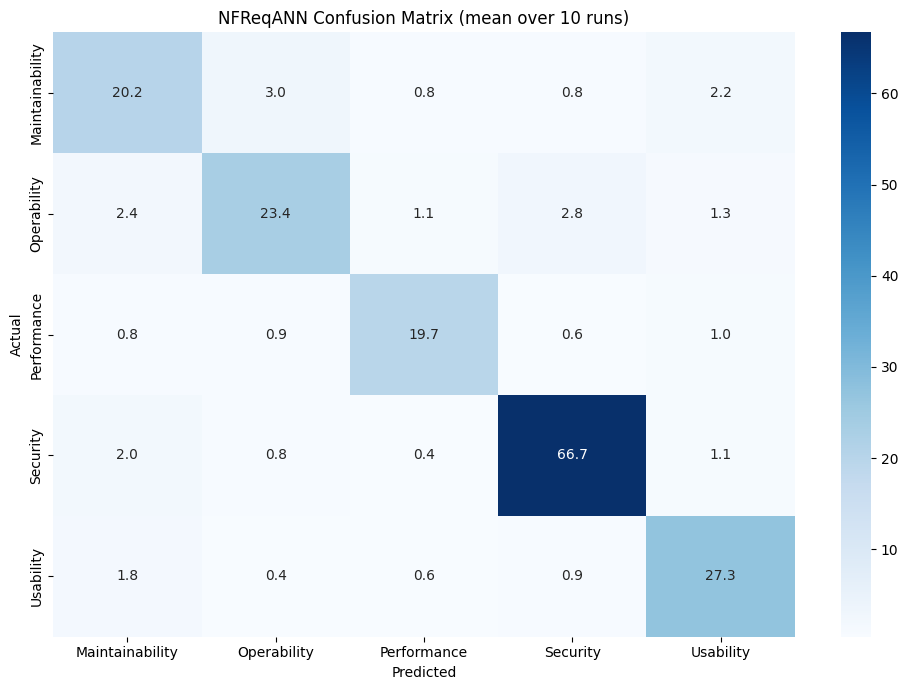

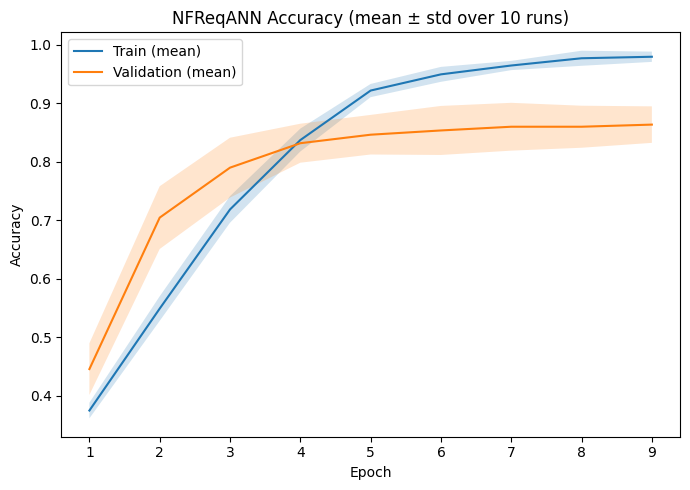

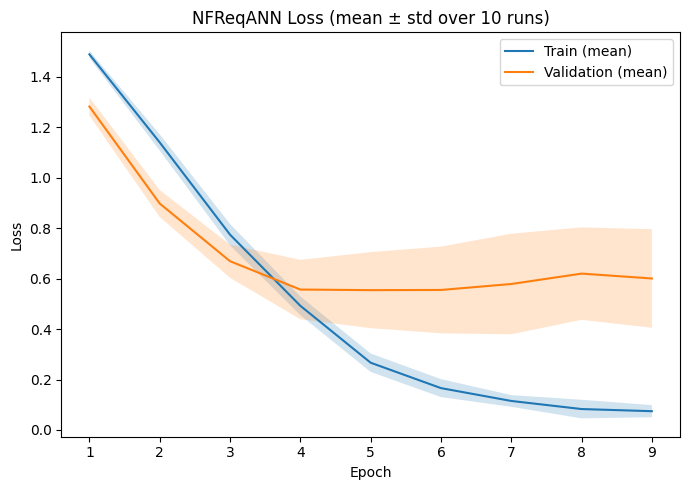


=== Top-20 words by avg positive LIME weight, aggregated over 10 runs ===
         word  avg_positive_lime_weight  avg_tfidf
     internal                    0.3837     0.0009
automatically                    0.2769     0.0010
      viruses                    0.2537     0.0020
      classes                    0.2443     0.0019
        tests                    0.2397     0.0007
        heart                    0.2327     0.0008
        above                    0.2175     0.0027
    usability                    0.2160     0.0010
         help                    0.2132     0.0032
    passwords                    0.2130     0.0072
       rights                    0.2110     0.0024
        logon                    0.2106     0.0037
      entered                    0.1997     0.0047
         role                    0.1969     0.0018
        areas                    0.1938     0.0005
      seconds                    0.1902     0.0128
          ccr                    0.1898     0.0021
      r

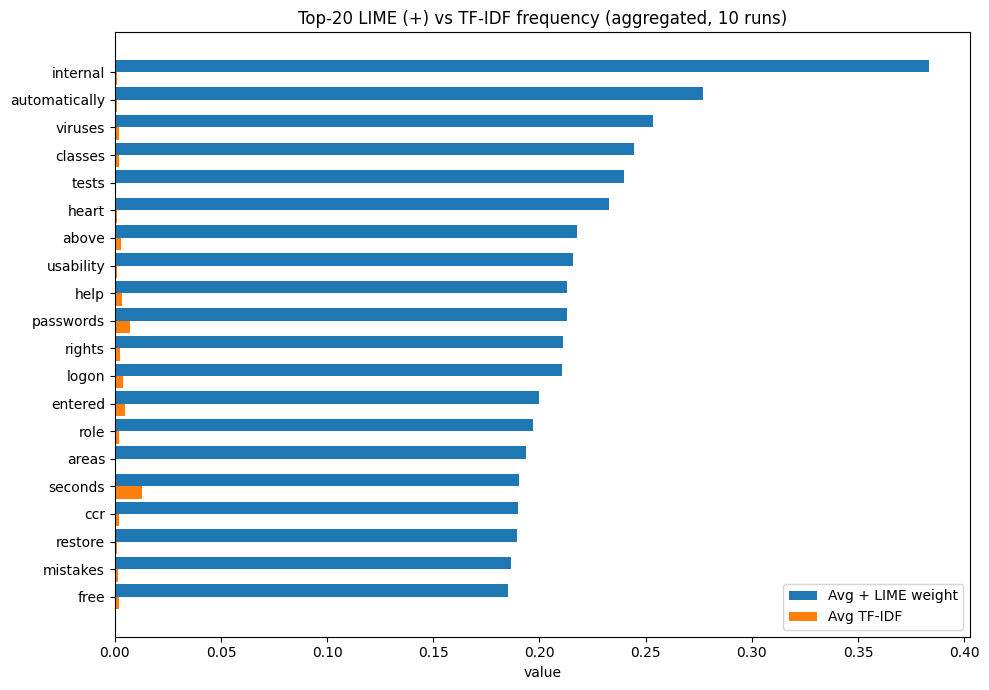

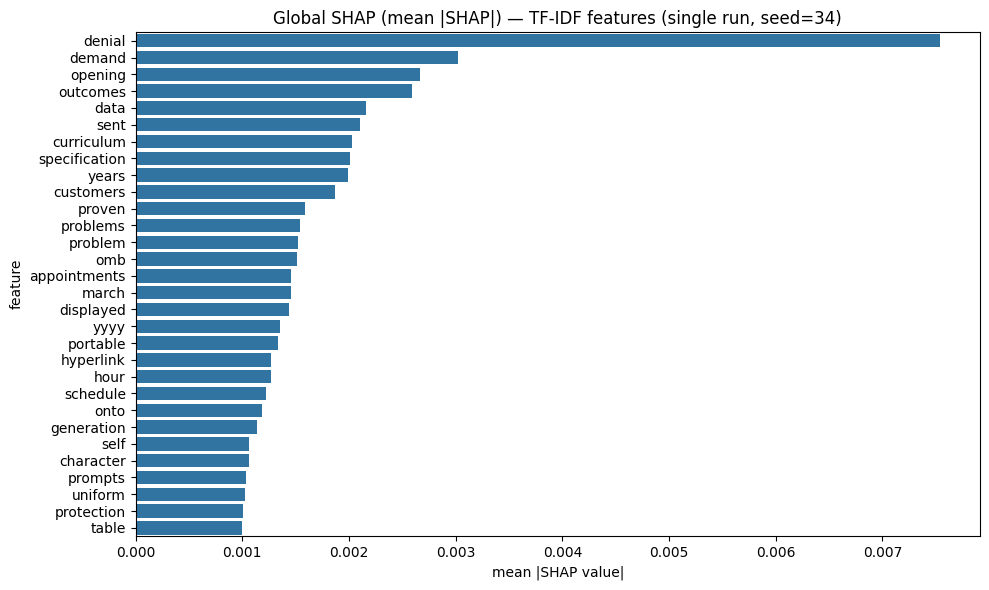


[INFO] All aggregate results, per-run CSVs, and figures saved to: /content/nfreqann_hybrid_uncleaned_multirun_results
[INFO] Files written:
   - accuracy_curve_mean.png
   - aggregate_metrics.csv
   - confusion_matrix_mean.png
   - faithfulness_results.csv
   - lime_vs_tfidf_top20.csv
   - lime_vs_tfidf_top20.png
   - loss_curve_mean.png
   - per_class_metrics.csv
   - per_run_metrics.csv
   - shap_global_summary.png
   - summary.json

DONE: 10 runs completed.


In [ ]:
# Deps: pip install lime shap transformers torch accelerate memory_profiler psutil

import os
import re
import json
import random
import numpy as np
import pandas as pd

# -------- NLTK setup --------
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

# -------- ML / DL --------
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix
)
from sklearn.preprocessing import normalize
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

# -------- Explainability --------
from lime.lime_text import LimeTextExplainer
import shap

# -------- Transformers --------
try:
    import torch
    from transformers import AutoTokenizer, AutoModel
    _TRANSFORMERS_OK = True
except Exception as _e:
    _TRANSFORMERS_OK = False
    print("[INFO] transformers/torch not available yet. "
          "Install with: pip install transformers torch accelerate")

# ============== Configuration ==============
CSV_PATH = "/content/NFR_five.csv"

# ---- Multi-run settings ----
N_RUNS = 10                      # how many times to repeat the whole pipeline (5-10 recommended)
BASE_SEED = 34                   # run i uses seed = BASE_SEED + i  (different split + init each run)
OUTPUT_DIR = "/content/nfreqann_hybrid_uncleaned_multirun_results"
SHAP_RUN_EVERY_ITERATION = False  # False = run SHAP once (run 0 only) -> standard practice, much faster
                                   # True  = run SHAP every iteration -> rigorous but very slow

TEST_SIZE = 0.20
MAX_FEATURES = 5000
EPOCHS = 12
BATCH_SIZE = 32

# LIME / Faithfulness parameters
LIME_NUM_SAMPLES = 1000         # perturbations per instance
LIME_NUM_FEATURES = 10          # tokens highlighted per instance
LIME_SUBSET_SIZE = 100          # how many test rows to explain (cap)
FAITHFULNESS_TOPK = [3, 5, 10]  # deletion tests

# SHAP parameters (keep tiny for speed; raise gradually if needed)
RUN_SHAP = True
SHAP_BACKGROUND_SIZE = 50       # from train set
SHAP_EVAL_SIZE = 100            # from test set
SHAP_NSAMPLES = 200             # Kernel SHAP nsamples heuristic ~ O(features)

# Expected categories (order defines columns)
EXPECTED_CATEGORIES = [
    'Maintainability', 'Operability', 'Performance', 'Security', 'Usability'
]
# EXPECTED_CATEGORIES = [
#     'Maintainability', 'Operability', 'Performance', 'Security', 'Usability',
#     'functional', 'other nonfunctional', 'not applicable'
# ]

# ============== DistilBERT feature settings ==============
USE_DISTILBERT = True and _TRANSFORMERS_OK   # flip to False to go back to pure TF-IDF
FEAT_COMBINE = "concat"                      # "tfidf" | "bert_only" | "concat"
DISTILBERT_MODEL = "distilbert-base-uncased"
BERT_MAX_LEN = 192
BERT_BATCH_SIZE = 32
BERT_POOLING = "mean"                         # "cls" | "mean"
LIME_USE_BERT = False                        # speed guard: use const-bert during LIME

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============== (Unused for modeling) Cleaning / Preprocessing ==============
REPLACE_BY_SPACE = re.compile(r'[/(){}|@,;]')
STOPWORDS = set(stopwords.words("english"))

# Preserve negation
for w in ["not", "no", "nor"]:
    STOPWORDS.discard(w)

lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = REPLACE_BY_SPACE.sub(" ", text)
    text = re.sub(r"\s+", " ", text).strip()

    tokens = text.split()

    tokens = [
        lemmatizer.lemmatize(t)
        for t in tokens
        if t not in STOPWORDS
    ]

    return " ".join(tokens)

# ============== Load data once (shared across all runs) ==============
df = pd.read_csv(CSV_PATH, encoding='latin1')

if 'sentence' not in df.columns or 'class_name' not in df.columns:
    raise ValueError("CSV must contain columns: 'sentence' and 'class_name'")

df['sentence'] = df['sentence'].fillna('')
df['class_name'] = df['class_name'].fillna('not applicable')

unknown_mask = ~df['class_name'].isin(EXPECTED_CATEGORIES)
df.loc[unknown_mask, 'class_name'] = 'not applicable'

Y_df = pd.get_dummies(df['class_name'], dtype=int)
Y_df = Y_df.reindex(columns=EXPECTED_CATEGORIES, fill_value=0)
Y_all = Y_df.values
y_idx_all = Y_all.argmax(axis=1)

# RAW text is now the single source of truth for both TF-IDF and BERT.
sentences_all = df['sentence'].tolist()

# ============== DistilBERT embedding helpers ==============
def _mean_pool(last_hidden_state, attention_mask):
    mask = attention_mask.unsqueeze(-1).expand(last_hidden_state.size()).float()
    masked = last_hidden_state * mask
    summed = torch.sum(masked, dim=1)
    counts = torch.clamp(mask.sum(dim=1), min=1e-9)
    return summed / counts

def _cls_pool(last_hidden_state):
    return last_hidden_state[:, 0, :]

_bert_tokenizer = None
_bert_model = None
_bert_device = None

def _get_bert():
    """Lazy-load DistilBERT once and reuse across all runs (weights don't change)."""
    global _bert_tokenizer, _bert_model, _bert_device
    if _bert_model is None:
        _bert_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        _bert_tokenizer = AutoTokenizer.from_pretrained(DISTILBERT_MODEL)
        _bert_model = AutoModel.from_pretrained(DISTILBERT_MODEL).to(_bert_device)
        _bert_model.eval()
    return _bert_tokenizer, _bert_model, _bert_device

def build_bert_embeddings(texts):
    tokenizer, model, device = _get_bert()
    outs = []
    with torch.no_grad():
        for i in range(0, len(texts), BERT_BATCH_SIZE):
            batch = texts[i:i+BERT_BATCH_SIZE]
            enc = tokenizer(
                batch, return_tensors="pt", padding=True, truncation=True,
                max_length=BERT_MAX_LEN
            ).to(device)
            out = model(**enc)
            if BERT_POOLING == "mean":
                pooled = _mean_pool(out.last_hidden_state, enc["attention_mask"])
            else:
                pooled = _cls_pool(out.last_hidden_state)
            outs.append(pooled.detach().cpu().numpy())
    return np.vstack(outs).astype(np.float32)


all_bert_embeddings = None
if USE_DISTILBERT:
    print("[INFO] Building DistilBERT sentence embeddings for the full dataset (once, RAW text)...")
    all_bert_embeddings = build_bert_embeddings(sentences_all)
    all_bert_embeddings = normalize(all_bert_embeddings, norm='l2')
    bert_dim = all_bert_embeddings.shape[1]
    print(f"[INFO] DistilBERT dims: {bert_dim}")

# ============== Model builder ==============
def create_model(input_dim: int, num_classes: int) -> tf.keras.Model:
    model = Sequential([
        Dense(2048, activation="relu", input_dim=input_dim),
        Dropout(0.3),
        Dense(256, activation="relu"),
        Dropout(0.5),
        Dense(128, activation="relu"),
        Dropout(0.5),
        Dense(num_classes, activation="softmax"),
    ])
    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    return model

def remove_tokens(raw_text: str, tokens_to_remove: list) -> str:
    words = raw_text.split()
    rem = set([t.lower() for t in tokens_to_remove])
    kept = [w for w in words if w.lower() not in rem]
    return " ".join(kept)

# ============================================================
# ===================== SINGLE RUN ===========================
# ============================================================
def run_once(seed: int, run_idx: int, run_shap_this_run: bool):
    """
    Executes the full pipeline (split -> TF-IDF (raw text) -> model -> eval ->
    LIME -> faithfulness -> optional SHAP) for one random seed.
    Returns a dict of scalar/array results for later aggregation.
    """
    print(f"\n{'='*70}\nRUN {run_idx+1}/{N_RUNS}  (seed={seed})\n{'='*70}")

    random.seed(seed)
    np.random.seed(seed)

    tf.keras.utils.set_random_seed(seed)

    if _TRANSFORMERS_OK:
        torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


    train_pos_outer, test_pos = train_test_split(
        np.arange(len(sentences_all)),
        test_size=TEST_SIZE,
        random_state=seed,
        stratify=y_idx_all
    )

    y_train_outer_idx = y_idx_all[train_pos_outer]
    train_pos, val_pos = train_test_split(
        train_pos_outer,
        test_size=0.15,
        random_state=seed,
        stratify=y_train_outer_idx
    )

    train_texts = [sentences_all[i] for i in train_pos]
    val_texts = [sentences_all[i] for i in val_pos]
    test_texts = [sentences_all[i] for i in test_pos]

    Y_train = Y_all[train_pos]
    Y_val = Y_all[val_pos]
    Y_test = Y_all[test_pos]

    y_train_idx = y_idx_all[train_pos]
    y_val_idx = y_idx_all[val_pos]
    y_test_idx = y_idx_all[test_pos]

    tfidf = TfidfVectorizer(
        max_features=MAX_FEATURES,
        min_df=1,
        smooth_idf=True,
        norm="l2"
    )

    X_train = tfidf.fit_transform(train_texts).toarray().astype(np.float32)
    X_val = tfidf.transform(val_texts).toarray().astype(np.float32)
    X_test = tfidf.transform(test_texts).toarray().astype(np.float32)

    Xb_train = Xb_val = Xb_test = None
    BERT_CONST = None
    if USE_DISTILBERT:
        Xb_train = all_bert_embeddings[train_pos]
        Xb_val = all_bert_embeddings[val_pos]
        Xb_test = all_bert_embeddings[test_pos]
        BERT_CONST = np.mean(Xb_train, axis=0, keepdims=True).astype(np.float32)
        BERT_CONST = normalize(BERT_CONST, norm='l2').astype(np.float32)

    X_train_model, X_val_model, X_test_model = X_train, X_val, X_test
    if USE_DISTILBERT:
        if FEAT_COMBINE == "bert_only":
            X_train_model, X_val_model, X_test_model = Xb_train, Xb_val, Xb_test
        elif FEAT_COMBINE == "concat":
            X_train_model = np.concatenate([X_train, Xb_train], axis=1).astype(np.float32)
            X_val_model = np.concatenate([X_val, Xb_val], axis=1).astype(np.float32)
            X_test_model = np.concatenate([X_test, Xb_test], axis=1).astype(np.float32)

    model = create_model(X_train_model.shape[1], num_classes=Y_train.shape[1])
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6, verbose=0)
    early_stop = EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)

    history = model.fit(
        X_train_model, Y_train,
        epochs=EPOCHS, batch_size=BATCH_SIZE,
        validation_data=(X_val_model, Y_val),
        callbacks=[reduce_lr, early_stop], verbose=0
    )

    # ---- classification metrics ----
    y_proba = model.predict(X_test_model, verbose=0)
    y_pred_idx = np.argmax(y_proba, axis=1)
    y_true_idx = y_test_idx

    cm = confusion_matrix(y_true_idx, y_pred_idx, labels=np.arange(len(EXPECTED_CATEGORIES)))
    acc = accuracy_score(y_true_idx, y_pred_idx)
    prec_macro = precision_score(y_true_idx, y_pred_idx, average='macro', zero_division=0)
    rec_macro = recall_score(y_true_idx, y_pred_idx, average='macro', zero_division=0)
    f1_macro = f1_score(y_true_idx, y_pred_idx, average='macro', zero_division=0)
    prec_weighted = precision_score(y_true_idx, y_pred_idx, average='weighted', zero_division=0)
    rec_weighted = recall_score(y_true_idx, y_pred_idx, average='weighted', zero_division=0)
    f1_weighted = f1_score(y_true_idx, y_pred_idx, average='weighted', zero_division=0)

    per_class_report = classification_report(
        y_true_idx, y_pred_idx, labels=np.arange(len(EXPECTED_CATEGORIES)),
        target_names=EXPECTED_CATEGORIES, digits=4, zero_division=0, output_dict=True
    )

    train_loss, train_acc = model.evaluate(X_train_model, Y_train, verbose=0)
    test_loss, test_acc = model.evaluate(X_test_model, Y_test, verbose=0)

    print(f"  Acc={acc:.4f}  F1(macro)={f1_macro:.4f}  F1(weighted)={f1_weighted:.4f}")

    # ---- feature builder for LIME / SHAP within this run's fitted tfidf/model ----
    def _build_features_for_texts(texts):
        X_tfidf = tfidf.transform(texts).toarray().astype(np.float32)
        if USE_DISTILBERT:
            if LIME_USE_BERT or len(texts) <= 64:
                X_bert = build_bert_embeddings(texts).astype(np.float32)
                X_bert = normalize(X_bert, norm='l2').astype(np.float32)
            else:
                X_bert = np.repeat(BERT_CONST, repeats=len(texts), axis=0).astype(np.float32)
            if FEAT_COMBINE == "bert_only":
                return X_bert
            elif FEAT_COMBINE == "concat":
                return np.concatenate([X_tfidf, X_bert], axis=1).astype(np.float32)
            else:
                return X_tfidf
        else:
            return X_tfidf

    def predict_proba_texts(texts: list) -> np.ndarray:
        X_ = _build_features_for_texts(texts)
        return model.predict(X_, verbose=0)

    # ---- LIME on test subset ----
    explainer = LimeTextExplainer(class_names=EXPECTED_CATEGORIES, bow=True)
    test_indices = np.arange(len(test_texts))
    rng = np.random.default_rng(seed)
    rng.shuffle(test_indices)
    subset_idx = test_indices[:min(LIME_SUBSET_SIZE, len(test_texts))]
    subset_texts = [test_texts[i] for i in subset_idx]

    lime_fidelities, lime_sparsities, lime_highlight_counts = [], [], []
    lime_token_weights_per_word = {}
    faithfulness_results = {k: [] for k in FAITHFULNESS_TOPK}

    for t in subset_texts:
        proba = predict_proba_texts([t])[0]
        pred_label = int(np.argmax(proba))
        exp = explainer.explain_instance(
            t, predict_proba_texts,
            num_features=LIME_NUM_FEATURES, num_samples=LIME_NUM_SAMPLES,
            labels=[pred_label]
        )
        lime_fidelities.append(exp.score)
        items = exp.as_list(label=pred_label)
        lime_sparsities.append(len(items))
        lime_highlight_counts.append(len(items))
        for tok, w in items:
            if w > 0:
                lime_token_weights_per_word.setdefault(tok.lower(), []).append(w)

        top_tokens = [tok for tok, w in sorted(items, key=lambda x: -x[1]) if w > 0]
        p_full = proba
        for k in FAITHFULNESS_TOPK:
            picked = top_tokens[:min(k, len(top_tokens))]
            t_del = remove_tokens(t, picked)
            p_del = predict_proba_texts([t_del])[0]
            drop = p_full[pred_label] - p_del[pred_label]
            faithfulness_results[k].append(max(0.0, drop))

    lime_summary = {
        "fidelity_mean": float(np.mean(lime_fidelities)),
        "fidelity_std": float(np.std(lime_fidelities)),
        "sparsity_mean": float(np.mean(lime_sparsities)),
        "n_explained": len(subset_texts),
    }
    faithfulness_summary = {
        k: {"mean": float(np.mean(v)), "std": float(np.std(v))}
        for k, v in faithfulness_results.items()
    }

    print(f"  LIME fidelity={lime_summary['fidelity_mean']:.3f}±{lime_summary['fidelity_std']:.3f}  "
          f"Faithfulness@5={faithfulness_summary[5]['mean']:.4f}")

    # ---- SHAP (optional, expensive) ----
    shap_top_features = None
    if RUN_SHAP and run_shap_this_run:
        print("  Running SHAP (KernelExplainer)...")
        rng2 = np.random.default_rng(seed)
        bg_idx = rng2.choice(len(X_train), size=min(SHAP_BACKGROUND_SIZE, len(X_train)), replace=False)
        ev_idx = rng2.choice(len(X_test), size=min(SHAP_EVAL_SIZE, len(X_test)), replace=False)
        X_bg = X_train[bg_idx]
        X_ev = X_test[ev_idx]

        def predict_proba_dense(x):
            x = np.asarray(x, dtype=np.float32)
            if USE_DISTILBERT:
                if FEAT_COMBINE == "bert_only":
                    full_x = np.repeat(BERT_CONST, repeats=x.shape[0], axis=0).astype(np.float32)
                elif FEAT_COMBINE == "concat":
                    bert_part = np.repeat(BERT_CONST, repeats=x.shape[0], axis=0).astype(np.float32)
                    full_x = np.concatenate([x, bert_part], axis=1).astype(np.float32)
                else:
                    full_x = x
            else:
                full_x = x
            return model.predict(full_x, verbose=0)

        explainer_shap = shap.KernelExplainer(predict_proba_dense, X_bg, link="identity")
        shap_values = explainer_shap.shap_values(X_ev, nsamples=SHAP_NSAMPLES)

        if isinstance(shap_values, list):
            mean_abs_per_class = [np.mean(np.abs(sv), axis=0) for sv in shap_values]
            mean_abs_global = np.mean(np.stack(mean_abs_per_class, axis=0), axis=0)
        else:
            mean_abs_global = np.mean(np.abs(shap_values), axis=0)

        vocab_items = sorted(tfidf.vocabulary_.items(), key=lambda kv: kv[1])
        feature_names = np.array([w for w, idx in vocab_items])
        mag = np.asarray(mean_abs_global, dtype=float).reshape(-1)[:feature_names.shape[0]]
        order = np.argsort(mag)[::-1][:min(30, len(mag))]
        shap_top_features = list(zip(feature_names[order].tolist(), mag[order].tolist()))

    return {
        "seed": seed,
        "history": history.history,
        "confusion_matrix": cm,
        "metrics": {
            "accuracy": acc, "precision_macro": prec_macro, "recall_macro": rec_macro,
            "f1_macro": f1_macro, "precision_weighted": prec_weighted,
            "recall_weighted": rec_weighted, "f1_weighted": f1_weighted,
            "train_acc": float(train_acc), "test_acc": float(test_acc),
            "train_loss": float(train_loss), "test_loss": float(test_loss),
        },
        "per_class_report": per_class_report,
        "lime_summary": lime_summary,
        "faithfulness_summary": faithfulness_summary,
        "lime_token_weights": lime_token_weights_per_word,
        "shap_top_features": shap_top_features,
        "tfidf_test_matrix": X_test if shap_top_features is not None else None,
        "tfidf_vocab": dict(tfidf.vocabulary_) if shap_top_features is not None else None,
    }

# ============================================================
# ===================== DRIVER LOOP ===========================
# ============================================================
all_results = []
for i in range(N_RUNS):
    seed_i = BASE_SEED + i
    shap_this_run = (i == 0) if not SHAP_RUN_EVERY_ITERATION else True
    res = run_once(seed_i, i, run_shap_this_run=shap_this_run)
    all_results.append(res)

# ============================================================
# ================= AGGREGATION / REPORTING ===================
# ============================================================
def agg_mean_std(values):
    arr = np.array(values, dtype=float)
    return float(np.mean(arr)), float(np.std(arr))

metric_keys = list(all_results[0]["metrics"].keys())
agg_metrics = {}
for mk in metric_keys:
    vals = [r["metrics"][mk] for r in all_results]
    mean_v, std_v = agg_mean_std(vals)
    agg_metrics[mk] = {"mean": mean_v, "std": std_v, "values": vals}

print(f"\n{'='*70}\nAGGREGATE RESULTS OVER {N_RUNS} RUNS (seeds {BASE_SEED}..{BASE_SEED+N_RUNS-1})\n{'='*70}")
metrics_table = pd.DataFrame({
    "metric": metric_keys,
    "mean": [agg_metrics[m]["mean"] for m in metric_keys],
    "std": [agg_metrics[m]["std"] for m in metric_keys],
})
print(metrics_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# ---- per-class metrics aggregation (precision/recall/f1 per category) ----
per_class_rows = []
for cat in EXPECTED_CATEGORIES:
    p_vals = [r["per_class_report"][cat]["precision"] for r in all_results]
    r_vals = [r["per_class_report"][cat]["recall"] for r in all_results]
    f_vals = [r["per_class_report"][cat]["f1-score"] for r in all_results]
    s_vals = [r["per_class_report"][cat]["support"] for r in all_results]
    p_m, p_s = agg_mean_std(p_vals)
    r_m, r_s = agg_mean_std(r_vals)
    f_m, f_s = agg_mean_std(f_vals)
    per_class_rows.append({
        "class": cat,
        "precision_mean": p_m, "precision_std": p_s,
        "recall_mean": r_m, "recall_std": r_s,
        "f1_mean": f_m, "f1_std": f_s,
        "support_mean": float(np.mean(s_vals)),
    })
per_class_df = pd.DataFrame(per_class_rows)
print("\n=== Per-class metrics (mean ± std across runs) ===")
print(per_class_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# ---- LIME aggregation ----
lime_fid_vals = [r["lime_summary"]["fidelity_mean"] for r in all_results]
lime_sparsity_vals = [r["lime_summary"]["sparsity_mean"] for r in all_results]
fid_m, fid_s = agg_mean_std(lime_fid_vals)
spar_m, spar_s = agg_mean_std(lime_sparsity_vals)
print(f"\n=== LIME (aggregated over {N_RUNS} runs, {LIME_SUBSET_SIZE} instances/run) ===")
print(f"Fidelity:  {fid_m:.4f} ± {fid_s:.4f}")
print(f"Sparsity:  {spar_m:.4f} ± {spar_s:.4f}")

# ---- Faithfulness aggregation ----
print(f"\n=== Faithfulness (Deletion Test), aggregated over {N_RUNS} runs ===")
faith_rows = []
for k in FAITHFULNESS_TOPK:
    vals = [r["faithfulness_summary"][k]["mean"] for r in all_results]
    m, s = agg_mean_std(vals)
    faith_rows.append({"top_k": k, "mean_prob_drop": m, "std_prob_drop": s})
    print(f"Top-{k} removal -> Avg prob drop: {m:.4f} ± {s:.4f}")
faith_df = pd.DataFrame(faith_rows)

# ---- averaged confusion matrix ----
cm_stack = np.stack([r["confusion_matrix"] for r in all_results], axis=0)
cm_mean = cm_stack.mean(axis=0)
cm_std = cm_stack.std(axis=0)

plt.figure(figsize=(10,7))
sns.heatmap(cm_mean, annot=True, fmt='.1f', cmap='Blues',
            xticklabels=EXPECTED_CATEGORIES, yticklabels=EXPECTED_CATEGORIES)
plt.title(f'NFReqANN Confusion Matrix (mean over {N_RUNS} runs)')
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix_mean.png"), dpi=150)
plt.show()

# ---- averaged training curves (pad/truncate to shortest run length due to early stopping) ----
min_epochs = min(len(r["history"]["accuracy"]) for r in all_results)
train_acc_mat = np.stack([r["history"]["accuracy"][:min_epochs] for r in all_results])
val_acc_mat = np.stack([r["history"]["val_accuracy"][:min_epochs] for r in all_results])
train_loss_mat = np.stack([r["history"]["loss"][:min_epochs] for r in all_results])
val_loss_mat = np.stack([r["history"]["val_loss"][:min_epochs] for r in all_results])

epochs_axis = np.arange(1, min_epochs + 1)

plt.figure(figsize=(7,5))
plt.plot(epochs_axis, train_acc_mat.mean(axis=0), label='Train (mean)')
plt.fill_between(epochs_axis, train_acc_mat.mean(0)-train_acc_mat.std(0),
                  train_acc_mat.mean(0)+train_acc_mat.std(0), alpha=0.2)
plt.plot(epochs_axis, val_acc_mat.mean(axis=0), label='Validation (mean)')
plt.fill_between(epochs_axis, val_acc_mat.mean(0)-val_acc_mat.std(0),
                  val_acc_mat.mean(0)+val_acc_mat.std(0), alpha=0.2)
plt.title(f'NFReqANN Accuracy (mean ± std over {N_RUNS} runs)')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "accuracy_curve_mean.png"), dpi=150)
plt.show()

plt.figure(figsize=(7,5))
plt.plot(epochs_axis, train_loss_mat.mean(axis=0), label='Train (mean)')
plt.fill_between(epochs_axis, train_loss_mat.mean(0)-train_loss_mat.std(0),
                  train_loss_mat.mean(0)+train_loss_mat.std(0), alpha=0.2)
plt.plot(epochs_axis, val_loss_mat.mean(axis=0), label='Validation (mean)')
plt.fill_between(epochs_axis, val_loss_mat.mean(0)-val_loss_mat.std(0),
                  val_loss_mat.mean(0)+val_loss_mat.std(0), alpha=0.2)
plt.title(f'NFReqANN Loss (mean ± std over {N_RUNS} runs)')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "loss_curve_mean.png"), dpi=150)
plt.show()

# ---- LIME vs TF-IDF top-20 words, aggregated across all runs ----
combined_lime_weights = {}
for r in all_results:
    for w, ws in r["lime_token_weights"].items():
        combined_lime_weights.setdefault(w, []).extend(ws)

lime_avg_pos = {w: np.mean(ws) for w, ws in combined_lime_weights.items() if len(ws) > 0}

# Reference TF-IDF fit on the RAW corpus (used purely to look up average
# TF-IDF weight per word for the comparison plot below).
tfidf_ref = TfidfVectorizer(max_features=MAX_FEATURES, min_df=1, smooth_idf=True, norm='l2')
X_ref_sparse = tfidf_ref.fit_transform(sentences_all)
X_ref = X_ref_sparse.toarray().astype(np.float32)
vocab_ref = tfidf_ref.vocabulary_

def avg_tfidf_for_word(w):
    idx = vocab_ref.get(w, None)
    if idx is None:
        return 0.0
    return float(np.mean(X_ref[:, idx]))

pairs = [(w, avg_w, avg_tfidf_for_word(w)) for w, avg_w in lime_avg_pos.items()]
comp_df = pd.DataFrame(pairs, columns=["word", "avg_positive_lime_weight", "avg_tfidf"])
comp_top20 = comp_df.sort_values("avg_positive_lime_weight", ascending=False).head(20).reset_index(drop=True)

print(f"\n=== Top-20 words by avg positive LIME weight, aggregated over {N_RUNS} runs ===")
print(comp_top20.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

plt.figure(figsize=(10,7))
indices = np.arange(len(comp_top20))
barw = 0.45
plt.barh(indices + 0.0, comp_top20["avg_positive_lime_weight"].values, height=barw, label="Avg + LIME weight")
plt.barh(indices + barw, comp_top20["avg_tfidf"].values, height=barw, label="Avg TF-IDF")
plt.yticks(indices + barw/2, comp_top20["word"].values)
plt.gca().invert_yaxis()
plt.title(f"Top-20 LIME (+) vs TF-IDF frequency (aggregated, {N_RUNS} runs)")
plt.xlabel("value"); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "lime_vs_tfidf_top20.png"), dpi=150)
plt.show()

# ---- SHAP (from whichever run computed it) ----
shap_run = next((r for r in all_results if r["shap_top_features"] is not None), None)
if shap_run is not None:
    feats, vals = zip(*shap_run["shap_top_features"])
    plt.figure(figsize=(10,6))
    sns.barplot(x=list(vals), y=list(feats), orient='h')
    note = "single run" if not SHAP_RUN_EVERY_ITERATION else "averaged"
    plt.title(f"Global SHAP (mean |SHAP|) — TF-IDF features ({note}, seed={shap_run['seed']})")
    plt.xlabel("mean |SHAP value|"); plt.ylabel("feature")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "shap_global_summary.png"), dpi=150)
    plt.show()

# ============================================================
# ===================== SAVE ARTIFACTS =========================
# ============================================================
metrics_table.to_csv(os.path.join(OUTPUT_DIR, "aggregate_metrics.csv"), index=False)
per_class_df.to_csv(os.path.join(OUTPUT_DIR, "per_class_metrics.csv"), index=False)
faith_df.to_csv(os.path.join(OUTPUT_DIR, "faithfulness_results.csv"), index=False)
comp_top20.to_csv(os.path.join(OUTPUT_DIR, "lime_vs_tfidf_top20.csv"), index=False)

run_level_rows = []
for r in all_results:
    row = {"seed": r["seed"], **r["metrics"],
           "lime_fidelity": r["lime_summary"]["fidelity_mean"],
           "lime_sparsity": r["lime_summary"]["sparsity_mean"]}
    for k in FAITHFULNESS_TOPK:
        row[f"faithfulness_top{k}"] = r["faithfulness_summary"][k]["mean"]
    run_level_rows.append(row)
run_level_df = pd.DataFrame(run_level_rows)
run_level_df.to_csv(os.path.join(OUTPUT_DIR, "per_run_metrics.csv"), index=False)

summary_json = {
    "n_runs": N_RUNS,
    "seeds": [r["seed"] for r in all_results],
    "metrics_mean_std": {m: {"mean": agg_metrics[m]["mean"], "std": agg_metrics[m]["std"]} for m in metric_keys},
    "lime_fidelity_mean_std": {"mean": fid_m, "std": fid_s},
    "lime_sparsity_mean_std": {"mean": spar_m, "std": spar_s},
    "faithfulness_mean_std": {str(k): {"mean": float(np.mean([r["faithfulness_summary"][k]["mean"] for r in all_results])),
                                        "std": float(np.std([r["faithfulness_summary"][k]["mean"] for r in all_results]))}
                               for k in FAITHFULNESS_TOPK},
}
with open(os.path.join(OUTPUT_DIR, "summary.json"), "w") as f:
    json.dump(summary_json, f, indent=2)

print(f"\n[INFO] All aggregate results, per-run CSVs, and figures saved to: {OUTPUT_DIR}")
print("[INFO] Files written:")
for fn in sorted(os.listdir(OUTPUT_DIR)):
    print(f"   - {fn}")

print(f"\n{'='*70}\nDONE: {N_RUNS} runs completed.\n{'='*70}")

# **Baseline DistilBERT (multiseed)**

In [ ]:
pip install transformers torch accelerate scikit-learn pandas memory_profiler

In [ ]:
# Deps: pip install transformers torch accelerate scikit-learn pandas memory_profiler


import os
import re
import json
import random
import time
import gc
import numpy as np
import pandas as pd
from memory_profiler import memory_usage

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    get_linear_schedule_with_warmup
)

# ============== Configuration ==============
CSV_PATH = "/content/NFR_five.csv"

N_RUNS = 10
BASE_SEED = 34
TEST_SIZE = 0.20          # outer split: identical protocol to the other scripts
INNER_VAL_SIZE = 0.15     # inner split: carved from the 80% train partition ONLY

MODEL_NAME = "distilbert-base-uncased"
MAX_LEN = 192             # matches the frozen-DistilBERT branch's max length
BATCH_SIZE = 16           # smaller than the other models' 32 -- full fine-tuning
                          # of all DistilBERT layers is far more memory-hungry
                          # than a frozen-embedding + dense-head setup on the
                          # same T4 GPU.
MAX_EPOCHS = 12
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
WARMUP_RATIO = 0.1
EARLY_STOP_PATIENCE = 3   # transformer fine-tuning converges much faster than
                          # the other models' patience=6; using the same
                          # patience here would very likely overfit a 620-item
                          # inner-train partition.

INFERENCE_TIMING_REPEATS = 5

OUTPUT_DIR = "/content/finetuned_distilbert_results"
EXPECTED_CATEGORIES = [
    "Maintainability", "Operability", "Performance", "Security", "Usability"
]

os.makedirs(OUTPUT_DIR, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ============== Load & filter data once (identical convention to the other scripts) ==============
df = pd.read_csv(CSV_PATH, encoding='latin1')
if 'sentence' not in df.columns or 'class_name' not in df.columns:
    raise ValueError("CSV must contain columns: 'sentence' and 'class_name'")

df['sentence'] = df['sentence'].fillna('')
df['class_name'] = df['class_name'].fillna('')
df = df[df['class_name'].isin(EXPECTED_CATEGORIES)].reset_index(drop=True)
if df.empty:
    raise ValueError("No rows left after filtering by EXPECTED_CATEGORIES.")

cat_to_idx = {c: i for i, c in enumerate(EXPECTED_CATEGORIES)}
y_idx_all = df['class_name'].map(cat_to_idx).values
sentences_all = df['sentence'].tolist()   # RAW text -- DistilBERT is surface-form sensitive

# ============== Dataset wrapper ==============
class NFRDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        enc = self.tokenizer(
            self.texts[idx], truncation=True, max_length=self.max_len,
            padding="max_length", return_tensors="pt"
        )
        item = {k: v.squeeze(0) for k, v in enc.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

def _reset_gpu_peak():
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats(DEVICE)

def _get_gpu_peak_mb():
    if torch.cuda.is_available():
        return torch.cuda.max_memory_allocated(DEVICE) / (1024 ** 2)
    return None

# ============================================================
# ===================== SINGLE RUN ===========================
# ============================================================
def run_once(seed: int, run_idx: int):
    print(f"\n{'='*70}\nRUN {run_idx+1}/{N_RUNS}  (seed={seed})\n{'='*70}")

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    # ---- Outer split: identical protocol to the other scripts ----
    train_idx_outer, test_idx = train_test_split(
        np.arange(len(sentences_all)),
        test_size=TEST_SIZE,
        random_state=seed,
        stratify=y_idx_all
    )

    # ---- Inner split: carved from the TRAIN partition only. Test set is
    #      not touched again until final evaluation below. ----
    y_train_outer = y_idx_all[train_idx_outer]
    train_idx, val_idx = train_test_split(
        train_idx_outer,
        test_size=INNER_VAL_SIZE,
        random_state=seed,
        stratify=y_train_outer
    )

    train_texts = [sentences_all[i] for i in train_idx]
    val_texts = [sentences_all[i] for i in val_idx]
    test_texts = [sentences_all[i] for i in test_idx]

    y_train = y_idx_all[train_idx]
    y_val = y_idx_all[val_idx]
    y_test = y_idx_all[test_idx]

    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=len(EXPECTED_CATEGORIES)
    ).to(DEVICE)

    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

    train_ds = NFRDataset(train_texts, y_train, tokenizer, MAX_LEN)
    val_ds = NFRDataset(val_texts, y_val, tokenizer, MAX_LEN)
    test_ds = NFRDataset(test_texts, y_test, tokenizer, MAX_LEN)

    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
    test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    total_steps = len(train_loader) * MAX_EPOCHS
    scheduler = get_linear_schedule_with_warmup(
        optimizer, num_warmup_steps=int(WARMUP_RATIO * total_steps), num_training_steps=total_steps
    )

    def run_epoch(loader, train_mode):
        model.train() if train_mode else model.eval()
        total_loss = 0.0
        n_batches = 0
        with torch.set_grad_enabled(train_mode):
            for batch in loader:
                batch = {k: v.to(DEVICE) for k, v in batch.items()}
                outputs = model(**batch)
                loss = outputs.loss
                if train_mode:
                    optimizer.zero_grad()
                    loss.backward()
                    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                    optimizer.step()
                    scheduler.step()
                total_loss += loss.item()
                n_batches += 1
        return total_loss / max(n_batches, 1)

    def _fit_call():
        history = {"train_loss": [], "val_loss": []}
        best_val_loss = float("inf")
        best_state = None
        patience_counter = 0
        for epoch in range(MAX_EPOCHS):
            tr_loss = run_epoch(train_loader, train_mode=True)
            val_loss = run_epoch(val_loader, train_mode=False)
            history["train_loss"].append(tr_loss)
            history["val_loss"].append(val_loss)
            print(f"    epoch {epoch+1}/{MAX_EPOCHS}  train_loss={tr_loss:.4f}  val_loss={val_loss:.4f}")
            if val_loss < best_val_loss - 1e-4:
                best_val_loss = val_loss
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                patience_counter = 0
            else:
                patience_counter += 1
                if patience_counter >= EARLY_STOP_PATIENCE:
                    print(f"    early stopping at epoch {epoch+1} (best val_loss={best_val_loss:.4f})")
                    break
        if best_state is not None:
            model.load_state_dict(best_state)
        return history

    gc.collect()
    _reset_gpu_peak()

    t0 = time.time()
    peak_mem_train_mb, history = memory_usage((_fit_call, (), {}), interval=0.5, max_usage=True, retval=True)
    train_time_sec = time.time() - t0
    gpu_peak_train_mb = _get_gpu_peak_mb()

    # ---- final evaluation on the untouched test partition ----
    def predict_all(loader):
        model.eval()
        all_logits, all_labels = [], []
        with torch.no_grad():
            for batch in loader:
                labels = batch.pop("labels")
                batch = {k: v.to(DEVICE) for k, v in batch.items()}
                out = model(**batch)
                all_logits.append(out.logits.detach().cpu().numpy())
                all_labels.append(labels.numpy())
        return np.concatenate(all_logits, axis=0), np.concatenate(all_labels, axis=0)

    _ = predict_all(test_loader)  # warm-up call, excluded from timing

    gc.collect()
    _reset_gpu_peak()

    def _predict_call():
        return predict_all(test_loader)

    inf_times = []
    peak_mem_inf_mb = 0.0
    for _ in range(INFERENCE_TIMING_REPEATS):
        t0 = time.time()
        mem_usage_val, _ = memory_usage((_predict_call, (), {}), interval=0.5, max_usage=True, retval=True)
        inf_times.append(time.time() - t0)
        peak_mem_inf_mb = max(peak_mem_inf_mb, mem_usage_val)

    logits, y_true_idx = predict_all(test_loader)
    y_pred_idx = np.argmax(logits, axis=1)

    n_test_items = len(y_true_idx)
    inference_time_per_item_sec = float(np.mean(inf_times)) / n_test_items
    gpu_peak_inf_mb = _get_gpu_peak_mb()

    peak_memory_mb = max(peak_mem_train_mb, peak_mem_inf_mb)
    gpu_peak_mb = None
    if gpu_peak_train_mb is not None or gpu_peak_inf_mb is not None:
        gpu_peak_mb = max(x for x in [gpu_peak_train_mb, gpu_peak_inf_mb] if x is not None)

    cm = confusion_matrix(y_true_idx, y_pred_idx, labels=np.arange(len(EXPECTED_CATEGORIES)))
    acc = accuracy_score(y_true_idx, y_pred_idx)
    prec_macro = precision_score(y_true_idx, y_pred_idx, average='macro', zero_division=0)
    rec_macro = recall_score(y_true_idx, y_pred_idx, average='macro', zero_division=0)
    f1_macro = f1_score(y_true_idx, y_pred_idx, average='macro', zero_division=0)
    prec_weighted = precision_score(y_true_idx, y_pred_idx, average='weighted', zero_division=0)
    rec_weighted = recall_score(y_true_idx, y_pred_idx, average='weighted', zero_division=0)
    f1_weighted = f1_score(y_true_idx, y_pred_idx, average='weighted', zero_division=0)

    per_class_report = classification_report(
        y_true_idx, y_pred_idx, labels=np.arange(len(EXPECTED_CATEGORIES)),
        target_names=EXPECTED_CATEGORIES, digits=4, zero_division=0, output_dict=True
    )

    train_loss_final = history["train_loss"][-1]
    val_loss_final = history["val_loss"][-1]
    # test loss, for parity with the other scripts' reported train/test loss columns
    test_logits, test_labels = logits, y_true_idx
    test_loss = nn.functional.cross_entropy(
        torch.tensor(test_logits), torch.tensor(test_labels, dtype=torch.long)
    ).item()

    print(f"  Acc={acc:.4f}  F1(macro)={f1_macro:.4f}  F1(weighted)={f1_weighted:.4f}")

    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return {
        "seed": seed,
        "history": history,
        "confusion_matrix": cm,
        "metrics": {
            "accuracy": acc, "precision_macro": prec_macro, "recall_macro": rec_macro,
            "f1_macro": f1_macro, "precision_weighted": prec_weighted,
            "recall_weighted": rec_weighted, "f1_weighted": f1_weighted,
            "train_loss": float(train_loss_final), "val_loss": float(val_loss_final),
            "test_loss": float(test_loss),
        },
        "per_class_report": per_class_report,
        "computational_cost": {
            "trainable_params": int(trainable_params),
            "train_time_sec": float(train_time_sec),
            "inference_time_per_item_sec": float(inference_time_per_item_sec),
            "peak_memory_mb": float(peak_memory_mb),
            "gpu_peak_memory_mb": gpu_peak_mb,
        },
    }

# ============================================================
# ===================== DRIVER LOOP ===========================
# ============================================================
all_results = []
for i in range(N_RUNS):
    seed_i = BASE_SEED + i
    res = run_once(seed_i, i)
    all_results.append(res)

# ============================================================
# ================= AGGREGATION / REPORTING ===================
# ============================================================
def agg_mean_std(values):
    arr = np.array(values, dtype=float)
    return float(np.mean(arr)), float(np.std(arr))

metric_keys = list(all_results[0]["metrics"].keys())
agg_metrics = {}
for mk in metric_keys:
    vals = [r["metrics"][mk] for r in all_results]
    mean_v, std_v = agg_mean_std(vals)
    agg_metrics[mk] = {"mean": mean_v, "std": std_v}

print(f"\n{'='*70}\nAGGREGATE RESULTS: FineTunedDistilBERT OVER {N_RUNS} RUNS "
      f"(seeds {BASE_SEED}..{BASE_SEED+N_RUNS-1})\n{'='*70}")
metrics_table = pd.DataFrame({
    "metric": metric_keys,
    "mean": [agg_metrics[m]["mean"] for m in metric_keys],
    "std": [agg_metrics[m]["std"] for m in metric_keys],
})
print(metrics_table.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
metrics_table.to_csv(os.path.join(OUTPUT_DIR, "aggregate_metrics_FineTunedDistilBERT.csv"), index=False)

# ---- per-class ----
per_class_rows = []
for cat in EXPECTED_CATEGORIES:
    p_vals = [r["per_class_report"][cat]["precision"] for r in all_results]
    r_vals = [r["per_class_report"][cat]["recall"] for r in all_results]
    f_vals = [r["per_class_report"][cat]["f1-score"] for r in all_results]
    s_vals = [r["per_class_report"][cat]["support"] for r in all_results]
    p_m, p_s = agg_mean_std(p_vals)
    r_m, r_s = agg_mean_std(r_vals)
    f_m, f_s = agg_mean_std(f_vals)
    per_class_rows.append({
        "class": cat, "precision_mean": p_m, "precision_std": p_s,
        "recall_mean": r_m, "recall_std": r_s, "f1_mean": f_m, "f1_std": f_s,
        "support_mean": float(np.mean(s_vals)),
    })
per_class_df = pd.DataFrame(per_class_rows)
per_class_df.to_csv(os.path.join(OUTPUT_DIR, "per_class_metrics_FineTunedDistilBERT.csv"), index=False)

# ---- computational cost ----
cost_keys = ["trainable_params", "train_time_sec", "inference_time_per_item_sec", "peak_memory_mb"]
cost_rows = []
for ck in cost_keys:
    vals = [r["computational_cost"][ck] for r in all_results]
    m, s = agg_mean_std(vals)
    cost_rows.append({"metric": ck, "mean": m, "std": s})
gpu_vals = [r["computational_cost"]["gpu_peak_memory_mb"] for r in all_results
            if r["computational_cost"]["gpu_peak_memory_mb"] is not None]
if gpu_vals:
    gm, gs = agg_mean_std(gpu_vals)
    cost_rows.append({"metric": "gpu_peak_memory_mb", "mean": gm, "std": gs})
cost_df = pd.DataFrame(cost_rows)
print(f"\n=== Computational cost (mean ± std over {N_RUNS} runs) ===")
print(cost_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
cost_df.to_csv(os.path.join(OUTPUT_DIR, "computational_cost_FineTunedDistilBERT.csv"), index=False)

# ---- per-run (for paired stats against NFReqANN-Hybrid, same seeds) ----
run_level_rows = [{"seed": r["seed"], **r["metrics"], **r["computational_cost"]} for r in all_results]
pd.DataFrame(run_level_rows).to_csv(
    os.path.join(OUTPUT_DIR, "per_run_metrics_FineTunedDistilBERT.csv"), index=False
)

# ---- EXPORT CONFUSION MATRICES (long format, one row per seed x true x pred cell) ----
cm_rows = []
for r in all_results:
    cm = r["confusion_matrix"]
    seed = r["seed"]
    for i, true_cat in enumerate(EXPECTED_CATEGORIES):
        for j, pred_cat in enumerate(EXPECTED_CATEGORIES):
            cm_rows.append({
                "seed": seed, "true_class": true_cat, "pred_class": pred_cat,
                "count": int(cm[i, j])
            })
pd.DataFrame(cm_rows).to_csv(
    os.path.join(OUTPUT_DIR, "confusion_matrices_FineTunedDistilBERT.csv"), index=False
)

print(f"\n[INFO] All results saved to: {OUTPUT_DIR}")
print("[INFO] Files written:")
for fn in sorted(os.listdir(OUTPUT_DIR)):
    print(f"   - {fn}")


RUN 1/10  (seed=34)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


    epoch 1/12  train_loss=1.5463  val_loss=1.4173
    epoch 2/12  train_loss=1.2028  val_loss=0.9765
    epoch 3/12  train_loss=0.6970  val_loss=0.6700
    epoch 4/12  train_loss=0.3924  val_loss=0.5882
    epoch 5/12  train_loss=0.2211  val_loss=0.6183
    epoch 6/12  train_loss=0.1324  val_loss=0.5844
    epoch 7/12  train_loss=0.0791  val_loss=0.6464
    epoch 8/12  train_loss=0.0608  val_loss=0.6736
    epoch 9/12  train_loss=0.0475  val_loss=0.6765
    early stopping at epoch 9 (best val_loss=0.5844)
  Acc=0.8743  F1(macro)=0.8495  F1(weighted)=0.8755

RUN 2/10  (seed=35)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (21 outputs left out)

    epoch 1/12  train_loss=1.5297  val_loss=1.3780
    epoch 2/12  train_loss=1.2185  val_loss=0.9818
    epoch 3/12  train_loss=0.8794  val_loss=0.6223
    epoch 4/12  train_loss=0.5566  val_loss=0.4372
    epoch 5/12  train_loss=0.3346  val_loss=0.3686
    epoch 6/12  train_loss=0.2085  val_loss=0.3191
    epoch 7/12  train_loss=0.1253  val_loss=0.2780
    epoch 8/12  train_loss=0.0772  val_loss=0.2801
    epoch 9/12  train_loss=0.0561  val_loss=0.3131
    epoch 10/12  train_loss=0.0473  val_loss=0.3136
    early stopping at epoch 10 (best val_loss=0.2780)
  Acc=0.8962  F1(macro)=0.8766  F1(weighted)=0.8953

RUN 10/10  (seed=43)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


    epoch 1/12  train_loss=1.5489  val_loss=1.3785
    epoch 2/12  train_loss=1.1912  val_loss=0.9066
    epoch 3/12  train_loss=0.7531  val_loss=0.5728
    epoch 4/12  train_loss=0.4358  val_loss=0.4121
    epoch 5/12  train_loss=0.2459  val_loss=0.3923
    epoch 6/12  train_loss=0.1540  val_loss=0.3680
    epoch 7/12  train_loss=0.1017  val_loss=0.3862
    epoch 8/12  train_loss=0.0653  val_loss=0.4231
    epoch 9/12  train_loss=0.0538  val_loss=0.4159
    early stopping at epoch 9 (best val_loss=0.3680)
  Acc=0.8634  F1(macro)=0.8296  F1(weighted)=0.8612

AGGREGATE RESULTS: FineTunedDistilBERT OVER 10 RUNS (seeds 34..43)
            metric   mean    std
          accuracy 0.8672 0.0238
   precision_macro 0.8503 0.0274
      recall_macro 0.8426 0.0305
          f1_macro 0.8435 0.0285
precision_weighted 0.8690 0.0257
   recall_weighted 0.8672 0.0238
       f1_weighted 0.8658 0.0244
        train_loss 0.0557 0.0159
          val_loss 0.4702 0.1360
         test_loss 0.4345 0.0815

=== 